# 05 - Interpretation, error analysis and the final model (ESOL)

CHE1147 Final Project, Team 9. Notebooks 03 and 04 showed how well the models predict log S. This notebook looks at why. We check which inputs the models rely on, how each input pushes a prediction up or down, and which families of molecules are predicted worst. Section 4 of our proposal planned that "permutation importance will show which inputs they rely on, with TPSA and HBA shuffled together", that "we will check which families, such as multi-ring molecules and sugars, are predicted worst", and that partial dependence plots would "test other interactions". Partial dependence plots are not part of the course, so we use SHAP (SHapley Additive exPlanations, Lecture 8) for the same purpose.

We also compare the training and test errors, plot a learning curve and a validation curve (bias and variance, Lecture 4), measure how long each model takes to train, describe the diversity of the dataset (Lecture 8), and save the final model so it can be used on new molecules (Lecture 9, slide 27).

The main results use no new tuning. Each model is refitted on each random split with the settings that cross-validation chose in `03_models.ipynb`, and we check that it gives the same test predictions as in notebook 03. Only sections 4.2 to 4.4 tune the models of notebooks 03 and 04 again. Sections 4.2 and 4.3 check whether the 20 settings that we tried for kernel ridge, the random forest and XGBoost in notebook 03 (random splits) and notebook 04 (scaffold splits) were enough, and section 4.4 tunes the models of notebook 04 again with folds grouped by scaffold. Sections 4.1, 4.5, 4.6, 5.1 and 5.2 also use cross-validation on the training sets, for their own checks.

We decided before running (in our written plan for this notebook) to compute the permutation importance on the test sets, because on the training set it is inflated by molecules the model has already seen. TPSA and HBA, and AromRings and AromProp, are shuffled together, and all fingerprint bits form one group. SHAP is computed on XGBoost with the 9 descriptors, because single fingerprint bits cannot be read chemically. The families and their rules (section 8) are printed before any error is computed.

Outline:

0. Setup
1. Data
2. Refitting the models of notebook 03
3. Training and test error
4. Learning curve, validation curve and tuning checks
5. Permutation importance
6. SHAP
7. Do the fingerprints tell isomers apart?
8. Families of molecules
9. Which families are predicted worst?
10. Training time
11. Diversity of the dataset
12. The final model
13. Figures
14. Summary of the notebooks

Abbreviations used in this notebook: CV (cross-validation), EDA (exploratory data analysis), HBA and HBD (hydrogen-bond acceptors and donors), kNN (k-nearest neighbours), LASSO (least absolute shrinkage and selection operator), MAE (mean absolute error), MOF (metal-organic framework), MW (molecular weight), PAH (polycyclic aromatic hydrocarbon), PCB (polychlorinated biphenyl), RMSE (root mean squared error), SD (standard deviation), SHAP (SHapley Additive exPlanations), SMARTS (SMILES arbitrary target specification), SMILES (simplified molecular-input line-entry system), t-SNE (t-distributed stochastic neighbour embedding), TPSA (topological polar surface area).

## 0. Setup

In [1]:
# Source: import blocks of Tutorial 4 (0.2) and Tutorial 5 (0.2), as in 03_models.ipynb
# Changes: shap, more RDKit (Tutorial 3), and TSNE, GridSearchCV, MAE and joblib from Tutorial 4

# basics
import os
import sys
import ast   # reads the settings saved as text in notebook 03
import time
import warnings   # to hide one expected warning (section 11)
import joblib
import numpy as np
import pandas as pd

# chemistry
from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, Draw, rdFingerprintGenerator

# machine learning dependencies
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso   # LASSO as in Tutorial 4 (8.2)
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV, cross_val_score   # cross_val_score as in Tutorial 4 (11.3)
# to rebuild the shuffled folds of notebook 04 in section 4.3, as in Tutorial 4 (11.1)
from sklearn.model_selection import KFold
from sklearn.model_selection import ParameterSampler   # the random draws of RandomizedSearchCV (section 4.2)
# section 4.4: RandomizedSearchCV as in notebook 04, GroupKFold (not in the tutorials) for folds grouped by scaffold
from sklearn.model_selection import RandomizedSearchCV, GroupKFold
from sklearn.metrics import mean_absolute_error
from sklearn.manifold import TSNE
import xgboost
from xgboost import XGBRegressor
import shap   # only for the plots (see section 6)

# plotting
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D   # legend entries drawn by hand
%matplotlib inline

# our shared functions in src/ (imported like MOF_descriptors.py in Tutorial 4)
sys.path.append(os.path.join('..', 'src'))
from esol_data import (RANDOM_SEED, TARGET, TARGET_BINARY, FEATURES, FEATURES_9, ESOL_TERMS, FP_COLUMNS, FP_RADIUS,
                       FP_SIZE, LABELS, prepare_esol, canonicalize_smiles, morgan_fingerprints,
                       stratified_split, murcko_scaffolds,
                       scaffold_split, SHORT_NAMES, molecule_families, FAMILY_ORDER)
from esol_evaluation import set_paper_style, MODEL_COLOURS, FULL_WIDTH, HALF_WIDTH

set_paper_style()

In [2]:
# Source: Tutorial 4 (0.3 Fix the random seed). RANDOM_SEED = 1 is defined in src/esol_data.py
np.random.seed(RANDOM_SEED)

FIG_DIR = os.path.join('..', 'results', 'figures')
TABLE_DIR = os.path.join('..', 'results', 'tables')
MODEL_DIR = os.path.join('..', 'results', 'models')
os.makedirs(MODEL_DIR, exist_ok=True)

# the results of notebooks 02, 03 and 04 are needed
for file_name in ['baselines_test_predictions.csv', 'baselines_knn_settings.csv', 'models_all_results.csv',
                  'models_test_predictions.csv', 'models_xgb_settings_tried.csv', 'models_comparison_per_split.csv',
                  'scaffold_test_predictions.csv', 'scaffold_settings.csv']:
    if not os.path.exists(os.path.join(TABLE_DIR, file_name)):
        raise FileNotFoundError(f"results/tables/{file_name} is missing: run notebooks 02, 03 and 04 first")

SPLIT_SEEDS = range(1, 11)   # the same 10 random splits as in notebooks 02 and 03
N_JOBS = -1                  # all CPU cores, as in notebook 03
N_REPEATS = 5                # shuffles per input group, as in the 2025 version of Tutorial 4

# True: run the three big tuning checks of sections 4.2, 4.3 and 4.4 (about 2.5 hours).
# False: read their saved results from the last full run instead (the rest of the notebook takes about 25 minutes)
RUN_TUNING_CHECKS = True

## 1. Data

In [3]:
# Source: prepare_esol(), morgan_fingerprints() and murcko_scaffolds() in src/esol_data.py
df_clean = prepare_esol()
fingerprint_df = morgan_fingerprints(df_clean)
df_model = pd.concat([df_clean, fingerprint_df], axis=1)
scaffolds = murcko_scaffolds(df_clean)
DESCRIPTORS_AND_FP = FEATURES_9 + FP_COLUMNS

Loaded data/delaney-processed.csv, shape = (1128, 10)


Dataset size: 1128 rows, 1115 unique molecules


## 2. Refitting the models of notebook 03

We use the same builder functions as in `03_models.ipynb`, with the settings that cross-validation chose there for each split (`results/tables/models_all_results.csv`). We refit five models:
- XGBoost on descriptors + fingerprints, the main model
- XGBoost on the 9 descriptors, the model we explain with SHAP in section 6
- kernel ridge on descriptors + fingerprints, a very different kind of model, to see whether the importance depends on the model
- the random forest and ridge on descriptors + fingerprints, for the training and test errors in section 3

In [4]:
# Source: the builder functions and parameter ranges of 03_models.ipynb, in src/esol_models.py
from esol_models import (make_preprocessing, make_ridge_pipeline, make_knn_pipeline, make_krr_pipeline,
                         make_rf_pipeline, make_xgb_pipeline, ridge_param_grid, knn_param_grid,
                         krr_param_grid, rf_param_grid, xgb_param_grid)

# model name: (builder, model name in notebook 03, feature set, columns)
REFIT_MODELS = {
    'XGBoost': (make_xgb_pipeline, 'XGBoost', 'descriptors + fingerprints', DESCRIPTORS_AND_FP),
    'XGBoost (9 descriptors)': (make_xgb_pipeline, 'XGBoost', '9 descriptors', FEATURES_9),
    'Kernel ridge': (make_krr_pipeline, 'Kernel ridge', 'descriptors + fingerprints', DESCRIPTORS_AND_FP),
    'Random forest': (make_rf_pipeline, 'Random forest', 'descriptors + fingerprints', DESCRIPTORS_AND_FP),
    'Ridge (descriptors + fingerprints)': (make_ridge_pipeline, 'Ridge', 'descriptors + fingerprints',
                                           DESCRIPTORS_AND_FP),
}
IMPORTANCE_MODELS = ['XGBoost', 'XGBoost (9 descriptors)', 'Kernel ridge']

In [5]:
# Source: new (final project). Settings and test predictions of 03_models.ipynb
results_03 = pd.read_csv(os.path.join(TABLE_DIR, 'models_all_results.csv'))
predictions_03 = pd.read_csv(os.path.join(TABLE_DIR, 'models_test_predictions.csv'), index_col=0)


def settings_03(seed, model_03, feature_set):
    """The settings that cross-validation chose in notebook 03 for one model, feature set and split."""
    row = results_03[(results_03['seed'] == seed) & (results_03['model'] == model_03)
                     & (results_03['feature_set'] == feature_set)].iloc[0]
    # saved as text, so ast.literal_eval turns it back into a dictionary
    return ast.literal_eval(row['best_params'])


def rmse(errors):
    """Root mean squared error of a list of errors."""
    return np.sqrt((errors ** 2).mean())


fitted = {}            # (model name, seed): fitted pipeline
train_test_rows = []   # training and test RMSE of each model and split
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    for model_name, (make_model, model_03, feature_set, columns) in REFIT_MODELS.items():
        model = make_model(feature_set)
        # ** passes each key and value of the dictionary as a separate setting
        model.set_params(**settings_03(seed, model_03, feature_set))
        model.fit(df_train[columns], df_train[TARGET])

        # check: the same test predictions as in notebook 03
        saved = predictions_03[(predictions_03['seed'] == seed) & (predictions_03['model'] == model_03)
                               & (predictions_03['feature_set'] == feature_set)]
        test_prediction = model.predict(df_test[columns])
        assert np.allclose(test_prediction, saved.loc[df_test.index, 'y_pred'], atol=1e-6)
        fitted[(model_name, seed)] = model

        train_test_rows.append({'model': model_name, 'seed': seed,
                                'train_rmse': rmse(model.predict(df_train[columns]) - df_train[TARGET]),
                                'test_rmse': rmse(test_prediction - df_test[TARGET])})

print(f"Refitted {len(fitted)} models. All give the same test predictions as in 03_models.ipynb")

Refitted 50 models. All give the same test predictions as in 03_models.ipynb


## 3. Training and test error

Lecture 4 (slides 6 to 8) explains the bias-variance trade-off. A model with a much lower error on the training set than on the test set has learned the training molecules too closely (high variance). A model with a high error on both is too simple (high bias). Here we compare the two errors for each model.

In [6]:
# Source: training and validation error as in Tutorial 4 (7.2), here training and test RMSE over the 10 random splits
# mean and standard deviation over the 10 splits
train_test = pd.DataFrame(train_test_rows)
train_test['gap'] = train_test['test_rmse'] - train_test['train_rmse']
train_test_summary = train_test.groupby('model')[['train_rmse', 'test_rmse', 'gap']].agg(['mean', 'std'])
train_test_summary = train_test_summary.loc[list(REFIT_MODELS)]
train_test_summary.round(3).to_csv(os.path.join(TABLE_DIR, 'interpretation_train_test_rmse.csv'))
train_test_summary.round(3)

train_rmse        test_rmse           gap  \
                                         mean    std      mean    std   mean   
model                                                                          
XGBoost                                 0.149  0.016     0.607  0.036  0.458   
XGBoost (9 descriptors)                 0.259  0.082     0.707  0.029  0.447   
Kernel ridge                            0.070  0.003     0.654  0.016  0.583   
Random forest                           0.330  0.007     0.667  0.032  0.337   
Ridge (descriptors + fingerprints)      0.447  0.058     0.790  0.057  0.343   

                                           
                                      std  
model                                      
XGBoost                             0.046  
XGBoost (9 descriptors)             0.089  
Kernel ridge                        0.015  
Random forest                       0.033  
Ridge (descriptors + fingerprints)  0.101

**Observations (training and test error)**
- All models fit the training molecules much better than the test molecules. XGBoost has a training RMSE of 0.149 against 0.607 on the test sets, kernel ridge 0.070 against 0.654, and the random forest 0.330 against 0.667.
- Ridge on descriptors + fingerprints has the highest training error (0.447) and also the highest test error (0.790), so it is the model most limited by bias. But its gap between training and test error (0.343) is as large as the random forest's (0.337), so with 2,057 inputs it also has some variance.
- Kernel ridge and XGBoost have the largest gaps (0.583 and 0.458), which Lecture 4 (slide 6) links to high variance, although the test RMSE of kernel ridge changes the least between splits (0.016 in notebook 03). Kernel ridge fits the training molecules almost exactly (0.070), far below its test error (0.654), so it probably also fits noise in the measured values. Their test errors are still the lowest, so on this dataset the extra flexibility gives better predictions. The learning curve below shows whether more data would help.

### 3.1 Fingerprints or a nonlinear model?

XGBoost on descriptors + fingerprints differs from ridge on the 9 descriptors in two ways: it is nonlinear and it has the fingerprints. `03_models.ipynb` fitted all four combinations on the same splits, so we can look at each change on its own. No model is fitted here.

In [7]:
# Source: paired comparison per split as in 02_baselines.ipynb (section 4), test RMSE from notebook 03 (no fitting)
# Changes: all 4 combinations of ridge or XGBoost with 9 descriptors or descriptors + fingerprints
ridge_xgb_rows = results_03[results_03['model'].isin(['Ridge', 'XGBoost'])
                            & results_03['feature_set'].isin(['9 descriptors', 'descriptors + fingerprints'])]
# one row per split, each column (model, feature set) is picked with a tuple
rmse_table = ridge_xgb_rows.pivot(index='seed', columns=['model', 'feature_set'], values='rmse')
print("Test RMSE (log mol/L), mean over the 10 random splits:")
print(rmse_table.mean().unstack('feature_set').round(3))   # feature set to the columns: a 2x2 table

ridge_fp_gain = rmse_table[('Ridge', 'descriptors + fingerprints')] - rmse_table[('Ridge', '9 descriptors')]
xgb_fp_gain = rmse_table[('XGBoost', 'descriptors + fingerprints')] - rmse_table[('XGBoost', '9 descriptors')]
xgb_gain_9 = rmse_table[('XGBoost', '9 descriptors')] - rmse_table[('Ridge', '9 descriptors')]
xgb_gain_fp = (rmse_table[('XGBoost', 'descriptors + fingerprints')]
               - rmse_table[('Ridge', 'descriptors + fingerprints')])
print("\nChange in test RMSE on the same split (negative = better):")
for name, d in [('adding the fingerprints, ridge', ridge_fp_gain), ('adding the fingerprints, XGBoost', xgb_fp_gain),
                ('XGBoost instead of ridge, 9 descriptors', xgb_gain_9),
                ('XGBoost instead of ridge, descriptors + fingerprints', xgb_gain_fp)]:
    print(f"{name:52s} {d.mean():+.3f} ± {d.std():.3f}, lower in {(d < 0).sum()} of 10 splits")

# overlap: how much smaller the fingerprint gain is with XGBoost than with ridge
overlap = xgb_fp_gain - ridge_fp_gain
print(f"\nOverlap of the two gains: {overlap.mean():.3f} ± {overlap.std():.3f}, positive in "
      f"{(overlap > 0).sum()} of 10 splits")

Test RMSE (log mol/L), mean over the 10 random splits:
feature_set  9 descriptors  descriptors + fingerprints
model                                                 
Ridge                0.997                       0.790
XGBoost              0.707                       0.607

Change in test RMSE on the same split (negative = better):
adding the fingerprints, ridge                       -0.207 ± 0.026, lower in 10 of 10 splits
adding the fingerprints, XGBoost                     -0.100 ± 0.039, lower in 10 of 10 splits
XGBoost instead of ridge, 9 descriptors              -0.290 ± 0.040, lower in 10 of 10 splits
XGBoost instead of ridge, descriptors + fingerprints -0.183 ± 0.041, lower in 10 of 10 splits

Overlap of the two gains: 0.108 ± 0.030, positive in 10 of 10 splits


**Observations (fingerprints or a nonlinear model?)**
- Both changes help on their own, in 10 of 10 splits. Adding the fingerprints lowers the test RMSE of ridge by 0.207 ± 0.026 and of XGBoost by 0.100 ± 0.039. Using XGBoost instead of ridge lowers it by 0.290 ± 0.040 on the 9 descriptors and by 0.183 ± 0.041 with the fingerprints.
- The two gains overlap. Together they lower the RMSE by 0.390, from 0.997 to 0.607, which is less than 0.207 + 0.290 = 0.497. The fingerprints help XGBoost less than ridge by 0.108 ± 0.030, in 10 of 10 splits. We see two possible reasons but did not test them: the trees can partly get from the descriptors the same information that the fingerprint bits give directly, and at a lower error there is less left to gain, because part of the error comes from the measured values and no model can remove it.
- For the research question, changing from ridge to XGBoost matters more than adding the fingerprints. XGBoost on the 9 descriptors alone has a lower test RMSE than kNN in 10 of 10 splits (`03_models.ipynb`), while ridge with the fingerprints has a lower RMSE in only 7 of 10, which does not meet our rule of at least 8 of 10.

### 3.2 Bootstrap confidence interval of the gain over kNN

Lecture 9 (slide 15) uses bootstrapping to "estimate the variability (ergo, uncertainty) of a statistic" when there is only one dataset. We apply this idea to the test molecules of each split. 1,000 times, we draw 223 test molecules with replacement, use the same draw for kNN and XGBoost, and compute RMSE(kNN) minus RMSE(XGBoost). The 2.5% and 97.5% values of these 1,000 gains give a 95% interval. Before the run we decided that the gain on a split counts as clear only if the whole interval is above 0.

The interval has three weaknesses. The models are not refitted, so it only shows how much the result depends on which test molecules were drawn (the 10 splits show the effect of retraining). The test molecules are not independent (for example the series of polychlorinated biphenyls (PCBs) and whole scaffold groups in the scaffold test sets), so the intervals are too narrow. The 20 intervals overlap and are not independent tests.

In [8]:
# Source: bootstrapping as in Lecture 9 (slides 15 and 16) and the bootstrap samples of the random forest in
#         Tutorial 4 (12.), np.random.default_rng as in Tutorial 4 (4.1). Test predictions saved by notebook 04
all_predictions = pd.read_csv(os.path.join(TABLE_DIR, 'scaffold_test_predictions.csv'))
N_BOOTSTRAP = 1000
bootstrap_rng = np.random.default_rng(RANDOM_SEED)   # its own generator, so later cells are not affected

bootstrap_rows = []
for split_type in ['random', 'scaffold']:
    for seed in SPLIT_SEEDS:
        rows = all_predictions[(all_predictions['split'] == split_type) & (all_predictions['seed'] == seed)]
        knn_rows = rows[rows['model'] == 'kNN (8 descriptors)'].set_index('molecule')
        xgb_rows = rows[rows['model'] == 'XGBoost'].set_index('molecule').loc[knn_rows.index]
        knn_errors = knn_rows['error'].values
        xgb_errors = xgb_rows['error'].values
        n = len(knn_errors)

        gains = []
        for b in range(N_BOOTSTRAP):
            draw = bootstrap_rng.integers(0, n, n)   # n test molecules drawn with replacement, the same for both models
            gains.append(rmse(knn_errors[draw]) - rmse(xgb_errors[draw]))
        low, high = np.percentile(gains, [2.5, 97.5])
        bootstrap_rows.append({'split': split_type, 'seed': seed, 'gain': rmse(knn_errors) - rmse(xgb_errors),
                               'low': low, 'high': high})

bootstrap_ci = pd.DataFrame(bootstrap_rows)
bootstrap_ci.round(3).to_csv(os.path.join(TABLE_DIR, 'bootstrap_ci.csv'), index=False)
for split_type in ['random', 'scaffold']:
    rows = bootstrap_ci[bootstrap_ci['split'] == split_type]
    width = rows['high'] - rows['low']
    print(f"{split_type} splits: whole interval above 0 in {(rows['low'] > 0).sum()} of 10, "
          f"interval width {width.min():.2f} to {width.max():.2f}")
bootstrap_ci.round(3)

random splits: whole interval above 0 in 10 of 10, interval width 0.14 to 0.24
scaffold splits: whole interval above 0 in 10 of 10, interval width 0.13 to 0.17


,split,seed,gain,low,high
0,random,1,0.145,0.075,0.216
1,random,2,0.214,0.120,0.325
2,random,3,0.172,0.098,0.250
3,random,4,0.320,0.201,0.443
4,random,5,0.243,0.149,0.351
5,random,6,0.118,0.038,0.193
6,random,7,0.190,0.083,0.300
7,random,8,0.175,0.085,0.274
8,random,9,0.198,0.102,0.299
9,random,10,0.182,0.085,0.286


**Observations (bootstrap)**
- On every split, random and scaffold, the whole 95% interval of the gain over kNN is above 0. The lowest lower end is 0.038 (random split 6). This suggests that on each split the gain is larger than what the choice of test molecules alone could explain.
- The intervals are 0.13 to 0.24 wide. A width of about 0.2 matches a standard deviation of about 0.05, which is about the size of the spread of the gain over the 10 splits (0.056 random, 0.044 scaffold, `03_models.ipynb` and `04_scaffold_split_and_uncertainty.ipynb`).
- Because of the weaknesses above, this adds no new evidence to the 10 of 10 result. It only suggests that the result on each split does not depend on a lucky draw of test molecules.

## 4. Learning curve, validation curve and tuning checks

Lecture 4 (slide 7) shows that for a model of fixed capacity the variance goes down when there is more data, and calls the error against the training set size a "learning curve". We refit XGBoost and ridge (both on descriptors + fingerprints, with the settings of each split) on 20, 40, 60, 80 and 100% of each training set and test them on the same test set. If the test error is still falling at 100%, more data would probably help.

In [9]:
# Source: Lecture 4 (slide 7). sample() and the training vs validation error of Tutorial 4 (7.2)
TRAIN_FRACTIONS = [0.2, 0.4, 0.6, 0.8, 1.0]
CURVE_MODELS = ['XGBoost', 'Ridge (descriptors + fingerprints)']

curve_rows = []
# refit each model on 20% to 100% of the training set, with the settings of notebook 03
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    for model_name in CURVE_MODELS:
        make_model, model_03, feature_set, columns = REFIT_MODELS[model_name]
        for fraction in TRAIN_FRACTIONS:
            if fraction == 1.0:
                part = df_train
            else:
                part = df_train.sample(frac=fraction, random_state=seed)
            model = make_model(feature_set)
            model.set_params(**settings_03(seed, model_03, feature_set))
            model.fit(part[columns], part[TARGET])
            # training and test RMSE of this fit
            curve_rows.append({'model': model_name, 'seed': seed, 'fraction': fraction, 'n_train': len(part),
                               'train_rmse': rmse(model.predict(part[columns]) - part[TARGET]),
                               'test_rmse': rmse(model.predict(df_test[columns]) - df_test[TARGET])})

# mean and SD over the 10 splits for each training set size
learning_curve = pd.DataFrame(curve_rows)
curve_summary = learning_curve.groupby(['model', 'n_train'])[['train_rmse', 'test_rmse']].agg(['mean', 'std'])
curve_summary.round(3).to_csv(os.path.join(TABLE_DIR, 'interpretation_learning_curve.csv'))
curve_summary.round(3)

train_rmse        test_rmse       
                                                 mean    std      mean    std
model                              n_train                                   
Ridge (descriptors + fingerprints) 178          0.422  0.086     0.911  0.048
                                   357          0.430  0.070     0.855  0.051
                                   535          0.426  0.067     0.828  0.048
                                   714          0.441  0.060     0.795  0.050
                                   892          0.447  0.058     0.790  0.057
XGBoost                            178          0.027  0.006     0.771  0.045
                                   357          0.061  0.009     0.699  0.036
                                   535          0.094  0.015     0.670  0.020
                                   714          0.123  0.017     0.626  0.025
                                   892          0.149  0.016     0.607  0.036

In [10]:
# Source: paired comparison per split as in 02_baselines.ipynb (section 4), last two steps of the curve
curve_by_split = {}
for model_name in CURVE_MODELS:
    # one row per split, one column per training fraction
    one_model = learning_curve[learning_curve['model'] == model_name]
    rows = one_model.pivot(index='seed', columns='fraction', values='test_rmse')
    curve_by_split[model_name] = rows
    for start, end in [(0.6, 0.8), (0.8, 1.0)]:
        d = rows[end] - rows[start]
        print(f"{model_name}, {start:.0%} to {end:.0%} of the training set: test RMSE {d.mean():+.3f} ± {d.std():.3f}, "
              f"lower in {(d < 0).sum()} of {len(d)} splits")
xgb_gain = curve_by_split['XGBoost'][1.0] - curve_by_split['XGBoost'][0.8]
ridge_gain = (curve_by_split['Ridge (descriptors + fingerprints)'][1.0]
              - curve_by_split['Ridge (descriptors + fingerprints)'][0.8])
print(f"From 80% to 100%, XGBoost improves more than ridge in {(xgb_gain < ridge_gain).sum()} of 10 splits")

XGBoost, 60% to 80% of the training set: test RMSE -0.044 ± 0.019, lower in 10 of 10 splits
XGBoost, 80% to 100% of the training set: test RMSE -0.019 ± 0.031, lower in 7 of 10 splits
Ridge (descriptors + fingerprints), 60% to 80% of the training set: test RMSE -0.033 ± 0.012, lower in 10 of 10 splits
Ridge (descriptors + fingerprints), 80% to 100% of the training set: test RMSE -0.005 ± 0.016, lower in 6 of 10 splits
From 80% to 100%, XGBoost improves more than ridge in 6 of 10 splits


**Observations (learning curve)**
- With more training molecules the test RMSE of XGBoost falls from 0.771 with 178 molecules to 0.607 with all 892, but the fall slows down at the end. From 60% to 80% of the training set it is lower in 10 of 10 splits (-0.044 ± 0.019), and from 80% to 100% only in 7 of 10 (-0.019 ± 0.031), which is within the spread between splits. We decided before the run to call the curve still falling only if it is lower in at least 8 of 10 splits, so we do not call it still falling. Its training RMSE goes up slowly (0.027 to 0.149) probably because the trees can no longer fit every molecule (we did not test this).
- Ridge improves less (0.911 to 0.790) and has almost flattened out at the end (-0.005 ± 0.016 from 80% to 100%, lower in 6 of 10 splits). Its training error stays between 0.42 and 0.45.
- Each point uses the settings that were tuned on the full training set, which probably makes the smaller training sets look a bit worse than they would with their own tuning.
- Over the whole curve XGBoost gains more than ridge (0.164 against 0.121), but from 80% to 100% it improves more than ridge in only 6 of 10 splits, below the same limit of 8 of 10, so we cannot say that more data would help XGBoost more.
- A larger dataset such as AqSolDB (Sorkun et al., 2019) could still help, but we did not test this. AqSolDB combines many sources, so it would also bring more noise.

### 4.1 Training and validation error against model complexity

The learning curve changes the amount of data. Here we change the complexity of the model, as in Tutorial 4 (section 7.2), where the training and validation errors are plotted against the polynomial degree. Lecture 4 (slide 6) shows the bias-variance trade-off as a U-shaped error against model complexity, and slide 16 says that "The training error only decreases with increasing model complexity." A simple model has a high error on both sets (high bias). A complex model has a low training error but a higher validation error. The distance between the two lines is the generalization gap (Lecture 4, slide 9).

For XGBoost we change the maximum tree depth (1, 2, 3, 4, 6, 8, 10 and 12, where notebook 03 searched only 3, 4, 6 and 8). For ridge we change alpha over the same 13 values from 0.001 to 1,000 as in notebook 03. Both use descriptors + fingerprints, and all other settings stay at the values cross-validation chose in `03_models.ipynb`. For each split we use `GridSearchCV` with `cv=5` on the training set only, as in notebook 03, and keep the training error too (`return_train_score=True`). The training error is then the error on the 4 folds used for fitting and the validation error the error on the left-out fold, each averaged over the 5 folds. The test set is not used. Because the folds are the same as in notebook 03, the validation error at the chosen value must be the cross-validation error that notebook 03 saved, and the code checks this. scikit-learn's `validation_curve` (imported in Tutorial 4) does the same with one score, while `GridSearchCV` gives the MAE and the RMSE in one run.

We decided before running to call a curve U-shaped only if its validation error has a clear minimum, and otherwise to describe the shape we see. The other settings were tuned together with the chosen depth, so the curve tends to have its lowest point there. In split 8, cross-validation chose different XGBoost settings (depth 8, 1,200 trees, learning rate 0.03, `colsample_bytree` 0.3, `min_child_weight` 3), and its curve is averaged with the others. The number of trees stays fixed, so the shallow end shows depth 1 with 800 trees and not the best possible shallow model.

In [11]:
# Source: training and validation error as in Tutorial 4 (7.2), 5-fold CV (GridSearchCV, Tutorial 4, 9.1)
#         instead of one validation set (Lecture 4, slide 16)
#         ridge alpha as the complexity setting as in Tutorial 4 (8.1 Regularization strength)
# Changes: return_train_score=True keeps the training-fold error. Only the training set is used
DEPTH_VALUES = [1, 2, 3, 4, 6, 8, 10, 12]
ALPHA_VALUES = np.logspace(-3, 3, 13)   # the ridge grid of notebook 03
COMPLEXITY_PARAMS = {'XGBoost': ('xgb__max_depth', DEPTH_VALUES),
                     'Ridge (descriptors + fingerprints)': ('ridge__alpha', ALPHA_VALUES)}
SCORING = {'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error'}   # as in notebook 03

complexity_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)   # only the training set is used here
    for model_name, (param, values) in COMPLEXITY_PARAMS.items():
        make_model, model_03, feature_set, columns = REFIT_MODELS[model_name]
        chosen = settings_03(seed, model_03, feature_set)
        model = make_model(feature_set)
        model.set_params(**chosen)   # the other settings as chosen in notebook 03
        # cv=5: the same folds as in notebook 03. refit=False: we only need the CV scores, not a final model
        search = GridSearchCV(model, param_grid={param: values}, cv=5, scoring=SCORING, refit=False,
                              return_train_score=True, n_jobs=N_JOBS)
        search.fit(df_train[columns], df_train[TARGET])
        scores = search.cv_results_   # "test" here is the validation fold
        for i, value in enumerate(values):   # cv_results_ is in the order of values
            complexity_rows.append({'model': model_name, 'seed': seed, 'value': value,
                                    # alpha is a float read back from text, so == could miss it
                                    'chosen': np.isclose(value, chosen[param]),
                                    'train_rmse': -scores['mean_train_rmse'][i],
                                    'val_rmse': -scores['mean_test_rmse'][i],
                                    'train_mae': -scores['mean_train_mae'][i], 'val_mae': -scores['mean_test_mae'][i]})

complexity = pd.DataFrame(complexity_rows)
complexity.round(4).to_csv(os.path.join(TABLE_DIR, 'interpretation_validation_curve.csv'), index=False)

# check: at the chosen values we get the CV errors that notebook 03 saved
at_chosen = complexity[complexity['chosen']]
assert len(at_chosen) == len(COMPLEXITY_PARAMS) * len(SPLIT_SEEDS)   # one chosen value per model and split
for row in at_chosen.itertuples():
    make_model, model_03, feature_set, columns = REFIT_MODELS[row.model]
    saved = results_03[(results_03['seed'] == row.seed) & (results_03['model'] == model_03)
                       & (results_03['feature_set'] == feature_set)].iloc[0]
    assert np.isclose(row.val_rmse, saved['cv_rmse'], atol=1e-4)
    assert np.isclose(row.val_mae, saved['cv_mae'], atol=1e-4)
print("At the chosen values the validation errors are the same as in 03_models.ipynb")

complexity_summary = complexity.groupby(['model', 'value'])[['train_rmse', 'val_rmse', 'val_mae']].agg(['mean', 'std'])
for model_name in COMPLEXITY_PARAMS:
    rows = complexity_summary.loc[model_name]
    print(f"{model_name}: lowest mean validation RMSE at {rows[('val_rmse', 'mean')].idxmin():g}, "
          f"lowest mean validation MAE at {rows[('val_mae', 'mean')].idxmin():g}")
print("Values chosen in notebook 03:")
print(at_chosen.groupby('model')['value'].value_counts().to_string())

# XGBoost: validation RMSE at each depth minus depth 6, on the same split (paired as in notebook 02)
xgb_curve = complexity[complexity['model'] == 'XGBoost'].pivot(index='seed', columns='value', values='val_rmse')
print("\nXGBoost validation RMSE minus depth 6, on the same split:")
for depth in [1, 2, 3, 4, 8, 10, 12]:
    d = xgb_curve[depth] - xgb_curve[6]
    print(f"depth {depth:2d}: {d.mean():+.4f} ± {d.std():.4f}, higher than depth 6 in {(d > 0).sum()} of 10 splits")
complexity_summary.round(3)

At the chosen values the validation errors are the same as in 03_models.ipynb
XGBoost: lowest mean validation RMSE at 6, lowest mean validation MAE at 6
Ridge (descriptors + fingerprints): lowest mean validation RMSE at 10, lowest mean validation MAE at 10
Values chosen in notebook 03:
model                               value    
Ridge (descriptors + fingerprints)  10.000000    8
                                    3.162278     2
XGBoost                             6.000000     9
                                    8.000000     1

XGBoost validation RMSE minus depth 6, on the same split:
depth  1: +0.1116 ± 0.0102, higher than depth 6 in 10 of 10 splits
depth  2: +0.0359 ± 0.0054, higher than depth 6 in 10 of 10 splits
depth  3: +0.0109 ± 0.0035, higher than depth 6 in 10 of 10 splits
depth  4: +0.0032 ± 0.0041, higher than depth 6 in 8 of 10 splits
depth  8: +0.0041 ± 0.0035, higher than depth 6 in 9 of 10 splits
depth 10: +0.0068 ± 0.0045, higher than depth 6 in 9 of 10 splits
depth

train_rmse        val_rmse  \
                                                     mean    std     mean   
model                              value                                    
Ridge (descriptors + fingerprints) 0.001000         0.130  0.015    1.736   
                                   0.003162         0.132  0.016    1.423   
                                   0.010000         0.135  0.016    1.207   
                                   0.031623         0.140  0.016    1.073   
                                   0.100000         0.149  0.016    0.989   
                                   0.316228         0.172  0.016    0.918   
                                   1.000000         0.229  0.013    0.851   
                                   3.162278         0.330  0.010    0.801   
                                   10.000000        0.468  0.009    0.785   
                                   31.622777        0.620  0.009    0.806   
                                   100.000000       0.772  0.010    0.866   
                                   316.227766       0.943  0.009    0.987   
                                   1000.000000      1.198  0.006    1.219   
XGBoost                            1.000000         0.577  0.009    0.737   
                                   2.000000         0.403  0.006    0.661   
                                   3.000000         0.299  0.005    0.636   
                                   4.000000         0.225  0.005    0.628   
                                   6.000000         0.131  0.003    0.625   
                                   8.000000         0.079  0.002    0.629   
                                   10.000000        0.052  0.002    0.632   
                                   12.000000        0.037  0.002    0.635   

                                                      val_mae         
                                                  std    mean    std  
model                              value                              
Ridge (descriptors + fingerprints) 0.001000     0.205   1.245  0.133  
                                   0.003162     0.134   1.032  0.083  
                                   0.010000     0.089   0.882  0.056  
                                   0.031623     0.053   0.786  0.034  
                                   0.100000     0.032   0.725  0.023  
                                   0.316228     0.022   0.674  0.018  
                                   1.000000     0.019   0.628  0.015  
                                   3.162278     0.018   0.596  0.014  
                                   10.000000    0.017   0.591  0.012  
                                   31.622777    0.014   0.614  0.010  
                                   100.000000   0.012   0.669  0.010  
                                   316.227766   0.010   0.776  0.009  
                                   1000.000000  0.007   0.966  0.006  
XGBoost                            1.000000     0.012   0.567  0.007  
                                   2.000000     0.013   0.500  0.009  
                                   3.000000     0.014   0.474  0.012  
                                   4.000000     0.015   0.463  0.010  
                                   6.000000     0.016   0.457  0.011  
                                   8.000000     0.014   0.459  0.012  
                                   10.000000    0.015   0.461  0.011  
                                   12.000000    0.015   0.464  0.012

**Observations (validation curve)**
- Ridge shows the full U-shaped curve of Lecture 4 (slide 6). With strong regularization (alpha 1,000) the training and validation errors are both high and almost equal (1.198 and 1.219). The model underfits (high bias). With weak regularization (alpha 0.001) the training error is low (0.130) but the validation error is high (1.736) and changes much more between splits (standard deviation 0.205 against 0.017 at alpha 10). The model overfits (high variance). The lowest validation error is at alpha 10 (0.785). Even there the training error is well below the validation error (0.468 against 0.785), so the best ridge model has high bias and also some variance.
- For XGBoost the validation error falls from 0.737 at depth 1 to 0.625 at depth 6, the depth chosen in 9 of 10 splits, while the training error keeps falling, from 0.577 to 0.037 at depth 12, as Lecture 4 (slide 16) says. Depth 1 underfits. Deeper trees fit the training molecules almost exactly, but this costs little on the validation folds (0.635 at depth 12). We did not test why. One possible reason is that each tree adds only a small step (learning rate 0.05) and sees only part of the molecules and inputs (`subsample` 0.7, `colsample_bytree` 0.5).
- From depth 4 to 8 the validation RMSE changes by less than 0.005. Depth 6 is lower than depth 4 in 8 of 10 splits and lower than depth 8 in 9 of 10, but only by 0.003 to 0.004, and the other settings were tuned together with depth 6, which favours it. So the bottom of the curve is flat, even though depth 6 is the lowest in most splits. Depths 10 and 12, which notebook 03 did not try, have a higher validation error than depth 6 in 9 of 10 splits, so a wider depth range in notebook 03 would not have helped. For ridge the curve repeats the search of notebook 03 on the same folds, so it is not a separate check.
- At depth 6 the generalization gap of XGBoost is large (training 0.131 against validation 0.625), like the gap between training and test error in section 3 (0.149 against 0.607). The training error here is a bit lower because each model is fitted on 4 of the 5 folds. A training error far below the validation error shows that the trees also fit noise in the measured values of the training molecules (Lecture 4, slide 9), but the flat validation curve shows that this costs little. A smaller depth gives a smaller gap but a higher validation error.

### 4.2 Were 20 settings per model enough?

In notebook 03 we tuned kernel ridge, the random forest and XGBoost with the same budget of 20 random settings each, while ridge and kNN tried every setting of their small grids. We used `RandomizedSearchCV`, which Tutorial 4 (9.1) mentions and the 2025 version of Tutorial 4 (7.2) practises as an option. Here we check whether a much bigger search would have changed anything. We use exactly the same 5 folds of each training set as in notebook 03 (`cv=5`) and the same grids:
- kernel ridge: every setting of its grid (117), on each of its three feature sets.
- random forest on descriptors + fingerprints: every setting of its grid (24, only 4 more than in notebook 03, so this part is a weak check).
- XGBoost on descriptors + fingerprints: the 20 settings that notebook 03 tried plus 100 new random settings from the same grid.
- XGBoost on the 9 descriptors: the same 120 settings.

We added XGBoost on the 9 descriptors after a first run of this check, because it is the model we explain with SHAP (section 6) and one of the models compared in section 3.1.

For XGBoost, if we call the best 1% of the grid good settings, 20 random draws include at least one good setting with a chance of 18%, and 120 draws with a chance of 70%, so this is a real test of the budget. The notebook 03 results stay our main results whatever happens here (decided before the run). Our rule for this check, also set before the run, was that the notebook 03 budget was enough if (a) the cross-validation ranking of kernel ridge, random forest and XGBoost is the same as in notebook 03 in at least 8 of 10 splits, (b) the model with the best cross-validation MAE still beats kNN on the test set in at least 8 of 10 splits, and (c) the mean gain in cross-validation MAE of each model is below 0.01 log units.

How the code works, in four steps: (1) make the list of candidate settings, (2) score each one with 5-fold cross-validation on the training set (`GridSearchCV`), (3) find the setting that notebook 03 chose and the best setting in this list, (4) compare their cross-validation and test errors. Two tools here are not in the course: `ParameterSampler` (the function that `RandomizedSearchCV` uses to draw its random settings, so we can list the same 20 settings that notebook 03 tried), and giving `GridSearchCV` a list of one-value dictionaries (each dictionary is then exactly one candidate setting). Together with the searches of sections 4.3 and 4.4 they take about 2.5 hours. To skip them, set `RUN_TUNING_CHECKS = False` in section 0, and the notebook reads the saved results of the last full run instead.

The best of 120 settings is more optimistic than the best of 20, so the gain in cross-validation MAE is likely larger than the true gain. The test set is not used for any choice here, so the change in test RMSE is a fair comparison, but with 223 test molecules per split it is noisy.

In [12]:
# Source: GridSearchCV as in Tutorial 4 (9.1), the grids of 03_models.ipynb (imported in section 2).
#         ParameterSampler (not in the course) is the function RandomizedSearchCV uses to draw its settings
# Changes: bigger searches on the same 5 folds, XGBoost candidates = notebook 03's 20 settings + 100 new random ones
settings_tried_03 = pd.read_csv(os.path.join(TABLE_DIR, 'models_xgb_settings_tried.csv')).to_dict('records')
# check: ParameterSampler with the seed of notebook 03 gives the same 20 settings that notebook 03 saved
assert list(ParameterSampler(xgb_param_grid, n_iter=20, random_state=RANDOM_SEED)) == settings_tried_03

# XGBoost: GridSearchCV tries every combination inside each dictionary of a list.
# Each dictionary below has one value per setting, so it is exactly one candidate
xgb_candidates = []
for setting in settings_tried_03:
    xgb_candidates.append({name: [value] for name, value in setting.items()})
n_from_03 = len(xgb_candidates)
# ParameterSampler is how RandomizedSearchCV draws its random settings
for setting in ParameterSampler(xgb_param_grid, n_iter=100, random_state=RANDOM_SEED):
    candidate = {name: [value] for name, value in setting.items()}
    if candidate not in xgb_candidates:
        xgb_candidates.append(candidate)
print(f"XGBoost candidates: {n_from_03} from notebook 03 + {len(xgb_candidates) - n_from_03} new = "
      f"{len(xgb_candidates)}")

FEATURE_COLUMNS = {'9 descriptors': FEATURES_9, 'fingerprints': FP_COLUMNS,
                   'descriptors + fingerprints': DESCRIPTORS_AND_FP}
CHECKS = [('Kernel ridge', '9 descriptors', make_krr_pipeline, krr_param_grid),
          ('Kernel ridge', 'fingerprints', make_krr_pipeline, krr_param_grid),
          ('Kernel ridge', 'descriptors + fingerprints', make_krr_pipeline, krr_param_grid),
          ('Random forest', 'descriptors + fingerprints', make_rf_pipeline, rf_param_grid),
          ('XGBoost', 'descriptors + fingerprints', make_xgb_pipeline, xgb_candidates),
          ('XGBoost', '9 descriptors', make_xgb_pipeline, xgb_candidates)]   # added after the first run

XGBoost candidates: 20 from notebook 03 + 100 new = 120


In [13]:
# Source: GridSearchCV and cv_results_ as in Tutorial 4 (9.1), training sets only
# Changes: also refit the best setting and record its test RMSE (for information, no choice is made with it)
if RUN_TUNING_CHECKS:
    start = time.time()
    tuning_rows = []
    for seed in SPLIT_SEEDS:
        df_train, df_test = stratified_split(df_model, seed)
        for model_name, feature_set, make_model, grid in CHECKS:
            model = make_model(feature_set)
            columns = FEATURE_COLUMNS[feature_set]
            search = GridSearchCV(model, param_grid=grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
            search.fit(df_train[columns], df_train[TARGET])

            # find the setting that notebook 03 chose in this bigger search
            chosen_03 = settings_03(seed, model_name, feature_set)
            k_03 = search.cv_results_['params'].index(chosen_03)
            k_best = search.best_index_
            row_03 = results_03[(results_03['seed'] == seed) & (results_03['model'] == model_name)
                                & (results_03['feature_set'] == feature_set)].iloc[0]
            fold_gains = []
            for fold in range(5):
                scores = search.cv_results_[f'split{fold}_test_score']
                fold_gains.append(scores[k_best] - scores[k_03])   # scores are minus MAE, so a gain is positive
            tuning_rows.append({
                'seed': seed, 'model': model_name, 'feature_set': feature_set,
                'settings_tried': len(search.cv_results_['params']),
                'cv_mae_03_saved': row_03['cv_mae'], 'cv_mae_03_here': -search.cv_results_['mean_test_score'][k_03],
                'cv_mae_best': -search.best_score_, 'best_params': str(search.best_params_),
                'same_setting_as_03': k_best == k_03,
                'fold_gains_positive': sum(gain > 0 for gain in fold_gains),
                'test_rmse_03': row_03['rmse'],
                'test_rmse_best': rmse(search.predict(df_test[columns]) - df_test[TARGET]),
            })
        print(f"split {seed} done ({time.time() - start:.0f} s)")

    tuning_check = pd.DataFrame(tuning_rows)
    tuning_check['cv_gain'] = tuning_check['cv_mae_03_here'] - tuning_check['cv_mae_best']
    tuning_check.round(5).to_csv(os.path.join(TABLE_DIR, 'tuning_check_per_split.csv'), index=False)
else:
    # quick run: the saved results of the last full run (rounded to 5 decimals)
    tuning_check = pd.read_csv(os.path.join(TABLE_DIR, 'tuning_check_per_split.csv'))
largest = (tuning_check['cv_mae_03_here'] - tuning_check['cv_mae_03_saved']).abs().max()
print(f"Check: notebook 03's settings get the same CV MAE as in notebook 03 (largest difference {largest:.1e})")

split 1 done (425 s)


split 2 done (839 s)


split 3 done (1259 s)


split 4 done (1676 s)


split 5 done (2098 s)


split 6 done (2510 s)


split 7 done (2896 s)


split 8 done (3307 s)


split 9 done (3733 s)


split 10 done (4104 s)
Check: notebook 03's settings get the same CV MAE as in notebook 03 (largest difference 5.6e-17)


In [14]:
# Source: new (final project). The rule of section 4.2, set before the run
knn_rows = pd.read_csv(os.path.join(TABLE_DIR, 'models_comparison_per_split.csv'))
knn_rmse = knn_rows[knn_rows['model'] == 'kNN (8 descriptors)'].set_index('seed')['rmse']

print("Gain in CV MAE from the bigger search (mean ± SD over 10 splits), and test RMSE in notebook 03 and "
      "after the bigger search:")
for model_name, feature_set, make_model, grid in CHECKS:
    rows = tuning_check[(tuning_check['model'] == model_name) & (tuning_check['feature_set'] == feature_set)]
    print(f"   {model_name:13s} {feature_set:27s} {rows['settings_tried'].iloc[0]:4d} settings, "
          f"gain {rows['cv_gain'].mean():.4f} ± {rows['cv_gain'].std():.4f} (better on "
          f"{rows['fold_gains_positive'].sum()} of 50 folds), "
          f"same setting as notebook 03 in {rows['same_setting_as_03'].sum()} of 10, "
          f"test RMSE {rows['test_rmse_03'].mean():.3f} to {rows['test_rmse_best'].mean():.3f}")

# (a) ranking of the three models (descriptors + fingerprints) by CV MAE, notebook 03 against the bigger search
same_ranking = 0
best_beats_knn = 0
for seed in SPLIT_SEEDS:
    rows = tuning_check[(tuning_check['seed'] == seed) & (tuning_check['feature_set'] == 'descriptors + fingerprints')]
    ranking_03 = list(rows.sort_values('cv_mae_03_saved')['model'])
    ranking_new = list(rows.sort_values('cv_mae_best')['model'])
    if ranking_03 == ranking_new:
        same_ranking += 1
    # (b) the model with the best CV MAE in the bigger search, against kNN on the test set
    best_row = rows.sort_values('cv_mae_best').iloc[0]
    if best_row['test_rmse_best'] < knn_rmse[seed]:
        best_beats_knn += 1
largest_gain = 0
for model_name, feature_set, make_model, grid in CHECKS:
    rows = tuning_check[(tuning_check['model'] == model_name) & (tuning_check['feature_set'] == feature_set)]
    largest_gain = max(largest_gain, rows['cv_gain'].mean())
print(f"\n(a) same CV ranking of the three models as in notebook 03 in {same_ranking} of 10 splits")
print(f"(b) the best model by CV beats kNN on the test set in {best_beats_knn} of 10 splits")
print(f"(c) largest mean CV gain of any model: {largest_gain:.4f} (limit 0.01)")
enough = same_ranking >= 8 and best_beats_knn >= 8 and largest_gain < 0.01
print("The 20-setting budget of notebook 03 was enough by our rule" if enough else "By our rule the "
      "20-setting budget of notebook 03 was not enough")

Gain in CV MAE from the bigger search (mean ± SD over 10 splits), and test RMSE in notebook 03 and after the bigger search:
   Kernel ridge  9 descriptors                117 settings, gain 0.0219 ± 0.0056 (better on 42 of 50 folds), same setting as notebook 03 in 0 of 10, test RMSE 0.730 to 0.727
   Kernel ridge  fingerprints                 117 settings, gain 0.0002 ± 0.0006 (better on 6 of 50 folds), same setting as notebook 03 in 8 of 10, test RMSE 1.077 to 1.078
   Kernel ridge  descriptors + fingerprints   117 settings, gain 0.0016 ± 0.0024 (better on 14 of 50 folds), same setting as notebook 03 in 5 of 10, test RMSE 0.654 to 0.648
   Random forest descriptors + fingerprints    24 settings, gain 0.0031 ± 0.0022 (better on 37 of 50 folds), same setting as notebook 03 in 0 of 10, test RMSE 0.667 to 0.662
   XGBoost       descriptors + fingerprints   120 settings, gain 0.0011 ± 0.0015 (better on 13 of 50 folds), same setting as notebook 03 in 5 of 10, test RMSE 0.607 to 0.611
   XGBo

In [15]:
# Source: new (final project). Kernel ridge on the 9 descriptors, the only model with a gain above 0.01.
#         ParameterSampler (not in the course) lists the 20 settings that RandomizedSearchCV drew in notebook 03
# Changes: compare the best settings of the full grid (saved above) with the 20 random settings that notebook 03 tried
# notebook 03 used random_state=RANDOM_SEED in every split, so ParameterSampler gives the same 20 settings as
# notebook 03
krr_tried_03 = list(ParameterSampler(krr_param_grid, n_iter=20, random_state=RANDOM_SEED))
print("Settings of notebook 03 with alpha at most 0.0316 and gamma at least 0.0316:")
for setting in krr_tried_03:
    if setting['krr__regressor__alpha'] <= 0.0317 and setting['krr__regressor__gamma'] >= 0.0316:
        print(f"   alpha {setting['krr__regressor__alpha']:.4f}, gamma {setting['krr__regressor__gamma']:.4f}")

# kernel ridge: the best setting of the full grid in each split, next to the setting of notebook 03
krr_rows = {}
for feature_set in ['9 descriptors', 'descriptors + fingerprints']:
    rows = tuning_check[(tuning_check['model'] == 'Kernel ridge') & (tuning_check['feature_set'] == feature_set)]
    krr_rows[feature_set] = rows.set_index('seed')
    print(f"\nBest setting of the full grid, kernel ridge on {feature_set} (notebook 03's choice in parentheses):")
    for seed, best_params in zip(rows['seed'], rows['best_params']):
        best = ast.literal_eval(best_params)   # the setting was saved as text
        chosen_03 = settings_03(seed, 'Kernel ridge', feature_set)
        print(f"   split {seed}: alpha {best['krr__regressor__alpha']:.4f}, gamma {best['krr__regressor__gamma']:.4f} "
              f"(alpha {chosen_03['krr__regressor__alpha']:.4f}, gamma {chosen_03['krr__regressor__gamma']:.4f})")

# 9 descriptors: change in test RMSE, and how far it stays behind descriptors + fingerprints in CV
rows_9, rows_both = krr_rows['9 descriptors'], krr_rows['descriptors + fingerprints']
test_change = rows_9['test_rmse_best'] - rows_9['test_rmse_03']
print(f"\nKernel ridge (9 descriptors), test RMSE after minus before: {test_change.mean():.3f} ± "
      f"{test_change.std():.3f}, "
      f"lower in {(test_change < 0).sum()} of 10 splits")
margin_03 = rows_9['cv_mae_03_here'] - rows_both['cv_mae_03_here']
margin_new = rows_9['cv_mae_best'] - rows_both['cv_mae_best']
print(f"CV MAE of 9 descriptors minus descriptors + fingerprints: {margin_03.mean():.3f} in notebook 03, "
      f"{margin_new.mean():.3f} after the bigger search (from {margin_new.min():.3f} to {margin_new.max():.3f})")

# More numbers from the table of the bigger search, for the observations below
xgb_9_rows = tuning_check[(tuning_check['model'] == 'XGBoost')
                          & (tuning_check['feature_set'] == '9 descriptors')].set_index('seed')
print(f"\nXGBoost (9 descriptors): CV gain of 0.01 or more in {(xgb_9_rows['cv_gain'] >= 0.01).sum()} of 10 splits, "
      f"lower test RMSE than kNN in {(xgb_9_rows['test_rmse_best'] < knn_rmse).sum()} of 10 splits after the "
      "bigger search")
xgb_beats_krr_03 = (xgb_9_rows['cv_mae_03_here'] < rows_9['cv_mae_03_here']).sum()
xgb_beats_krr_new = (xgb_9_rows['cv_mae_best'] < rows_9['cv_mae_best']).sum()
print(f"9 descriptors: XGBoost has a lower CV MAE than kernel ridge in {xgb_beats_krr_03} of 10 splits in notebook 03, "
      f"{xgb_beats_krr_new} of 10 after the bigger search")
# how much lower the CV MAE of XGBoost is than that of kernel ridge (descriptors + fingerprints)
krr_both = tuning_check[(tuning_check['model'] == 'Kernel ridge')
                        & (tuning_check['feature_set'] == 'descriptors + fingerprints')]
xgb_both = tuning_check[(tuning_check['model'] == 'XGBoost')
                        & (tuning_check['feature_set'] == 'descriptors + fingerprints')]
xgb_lead = krr_both.set_index('seed')['cv_mae_best'] - xgb_both.set_index('seed')['cv_mae_best']
print(f"CV MAE of kernel ridge minus XGBoost (descriptors + fingerprints) after the bigger search: "
      f"{xgb_lead.mean():.4f} ± {xgb_lead.std():.4f}, smallest {xgb_lead.min():.4f} (split {xgb_lead.idxmin()})")
# test RMSE of kernel ridge, 9 descriptors minus descriptors + fingerprints,
# with the settings of notebook 03 and after the bigger search
test_margin_03 = rows_9['test_rmse_03'] - rows_both['test_rmse_03']
test_margin_new = rows_9['test_rmse_best'] - rows_both['test_rmse_best']
print(f"Kernel ridge, test RMSE of 9 descriptors minus descriptors + fingerprints: "
      f"{test_margin_03.mean():.3f} in notebook 03, "
      f"{test_margin_new.mean():.3f} after the bigger search")

# The search chose by MAE but we compared test RMSE above, so we also refit kernel ridge (9 descriptors)
# with both settings and compare the test MAE
mae_changes = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    test_mae = []
    for setting in [settings_03(seed, 'Kernel ridge', '9 descriptors'),
                    ast.literal_eval(rows_9.loc[seed, 'best_params'])]:
        model = make_krr_pipeline('9 descriptors')
        model.set_params(**setting)
        model.fit(df_train[FEATURES_9], df_train[TARGET])
        test_mae.append((model.predict(df_test[FEATURES_9]) - df_test[TARGET]).abs().mean())
    # check: the setting of notebook 03 gives the test MAE saved in notebook 03
    saved_mae = results_03[(results_03['seed'] == seed) & (results_03['model'] == 'Kernel ridge')
                           & (results_03['feature_set'] == '9 descriptors')]['mae'].iloc[0]
    assert abs(test_mae[0] - saved_mae) < 1e-6
    mae_changes.append(test_mae[1] - test_mae[0])
mae_changes = pd.Series(mae_changes, index=SPLIT_SEEDS)
print(f"Kernel ridge (9 descriptors), test MAE after minus before: {mae_changes.mean():.3f} ± {mae_changes.std():.3f}, "
      f"lower in {(mae_changes < 0).sum()} of 10 splits")

Settings of notebook 03 with alpha at most 0.0316 and gamma at least 0.0316:
   alpha 0.0316, gamma 0.0316

Best setting of the full grid, kernel ridge on 9 descriptors (notebook 03's choice in parentheses):
   split 1: alpha 0.0316, gamma 0.1000 (alpha 0.0316, gamma 0.0316)
   split 2: alpha 0.0316, gamma 0.1000 (alpha 0.0316, gamma 0.0316)
   split 3: alpha 0.0316, gamma 0.1000 (alpha 0.0316, gamma 0.0316)
   split 4: alpha 0.0100, gamma 0.1000 (alpha 0.0316, gamma 0.0316)
   split 5: alpha 0.0100, gamma 0.0316 (alpha 0.0316, gamma 0.0316)
   split 6: alpha 0.0316, gamma 0.1000 (alpha 0.0316, gamma 0.0316)
   split 7: alpha 0.0032, gamma 0.0316 (alpha 0.0316, gamma 0.0316)
   split 8: alpha 0.0316, gamma 0.1000 (alpha 0.0316, gamma 0.0316)
   split 9: alpha 0.0316, gamma 0.1000 (alpha 0.0316, gamma 0.0316)
   split 10: alpha 0.0316, gamma 0.1000 (alpha 0.0316, gamma 0.0316)

Best setting of the full grid, kernel ridge on descriptors + fingerprints (notebook 03's choice in parentheses

Kernel ridge (9 descriptors), test MAE after minus before: -0.020 ± 0.016, lower in 9 of 10 splits


**Observations (tuning check)**
- The check uses the same folds as notebook 03. The setting that notebook 03 chose gets the same cross-validation MAE here as in notebook 03 (largest difference 5.6e-17).
- Rules (a) and (b) hold in 10 of 10 splits. XGBoost, kernel ridge and random forest on descriptors + fingerprints keep the same cross-validation ranking as in notebook 03 (in that order), and the model with the best cross-validation MAE still beats kNN on the test set in every split. The lead of XGBoost over kernel ridge is small, though. After the bigger search it is 0.0127 ± 0.0082 in cross-validation MAE, and only 0.0006 on split 2. These three models also pass rule (c), with gains of 0.0011 (XGBoost), 0.0031 (random forest) and 0.0016 (kernel ridge).
- Rule (c) does not hold for kernel ridge on the 9 descriptors, so by the rule we set before the run the 20-setting budget of notebook 03 was not enough. This model gains 0.0219 ± 0.0056 in cross-validation MAE (better on 42 of 50 folds), and the full grid never picks the setting of notebook 03. XGBoost on the 9 descriptors gains 0.0079 ± 0.0049. That is below the limit, but the gain is 0.01 or more in 3 of 10 splits, it shows on 37 of 50 folds, and the bigger search keeps the setting of notebook 03 in only 1 of 10 splits. Kernel ridge on the fingerprints gains only 0.0002.
- The cell above shows where the gain of kernel ridge on the 9 descriptors comes from. In notebook 03 it chose alpha 0.0316 and gamma 0.0316 in all 10 splits. It was the only one of its 20 settings with alpha at most 0.0316 and gamma at least 0.0316. The full grid picks gamma 0.1 in 8 of 10 splits, with alpha 0.0316 in 7 of these 8. The best setting is inside the grid and not on its edge, so the grid itself was wide enough. We did not test why a larger gamma suits the 9 descriptors.
- So the way we tuned in notebook 03 has a weakness. With a fixed `random_state`, every split tried the same 20 settings, so a part of the grid that these 20 settings miss is missed in all 10 splits. This also makes it more likely that XGBoost on descriptors + fingerprints chose the same setting in 9 of 10 splits in notebook 03 (with 120 settings it keeps that setting in only 5 of 10). The 100 new XGBoost settings of this check have the same weakness, because they are also the same in every split. Only kernel ridge and the random forest were searched on their full grids.
- For kernel ridge on the 9 descriptors the gain also shows on the test set, but mainly in MAE, the score we tuned with. Its test MAE drops by 0.020 ± 0.016 (lower in 9 of 10 splits). Its test RMSE changes by only -0.004 ± 0.035 (lower in 7 of 10 splits), which is small next to its spread over the splits. RMSE gives more weight to the largest errors (Lecture 3, slide 26), so the better setting seems to help the typical molecule more than the worst ones.
- For XGBoost on descriptors + fingerprints the small gain in cross-validation (0.0011) comes with a slightly higher test RMSE (0.607 to 0.611). So this small gain in cross-validation did not carry over to the test molecules.
- No conclusion of the main comparison on the random splits changes. For the three main models the mean test RMSE changes by less than 0.01 (XGBoost 0.607 to 0.611, random forest 0.667 to 0.662, kernel ridge 0.654 to 0.648). XGBoost on the 9 descriptors goes from 0.707 to 0.700 and still beats kNN in 10 of 10 splits. Kernel ridge on descriptors + fingerprints still has a lower cross-validation MAE than on the 9 descriptors in every split, so the feature set that notebook 03 chose stays the same. The margin in cross-validation is smaller (0.035 instead of 0.055), but the margin in test RMSE is not (0.077 in notebook 03, 0.079 after).
- One ranking outside the main comparison changes. On the 9 descriptors, XGBoost has a lower cross-validation MAE than kernel ridge in 9 of 10 splits after the bigger search, against 10 of 10 in notebook 03.
- Section 4.3 repeats this check on the scaffold splits of `04_scaffold_split_and_uncertainty.ipynb`.
- As decided before the run, the notebook 03 results stay our main results. SHAP in section 6 uses XGBoost on the 9 descriptors with the settings of notebook 03, and section 6 also repeats it with the settings of this bigger search. In the paper we report the result for kernel ridge on the 9 descriptors as a limitation of the 20-setting budget, with its cross-validation gain and both test changes.

### 4.3 The same check on the scaffold splits

Section 4.2 used the random splits only. In notebook 04 we tuned kernel ridge, random forest and XGBoost on the 10 scaffold splits with the same budget of 20 random settings, and again every split tried the same 20 settings. Here we repeat the check of section 4.2 on the scaffold splits, for the four searches of notebook 04 (about an hour):
- kernel ridge on descriptors + fingerprints: every setting of its grid (117).
- random forest on descriptors + fingerprints: every setting of its grid (24, only 4 more than in notebook 04, so this part is a weak check).
- XGBoost on descriptors + fingerprints: the same 120 settings as in section 4.2.
- XGBoost on the 9 descriptors: the same 120 settings.

We use the same 5 folds of each training set as in notebook 04 and the same score (MAE). These folds are shuffled with `KFold` (Tutorial 4, section 11.1) and not grouped by scaffold, so the cross-validation here tells us how well each setting does on molecules like the training molecules. Only the change on the scaffold test sets says something about new scaffolds, and we do not use it for any choice. Notebook 04 saved the setting it chose but not its cross-validation MAE. So we check two things instead: the setting of notebook 04 must be the best of the 20 settings that notebook 04 tried, and when we refit it here, it must give the same test predictions as in notebook 04. Notebook 04 has no kernel ridge on the 9 descriptors, the one model that failed rule (c) in section 4.2, so that model is not checked here.

We use the rule of section 4.2, set before this run: the notebook 04 budget was enough if (a) the cross-validation ranking of kernel ridge, random forest and XGBoost on descriptors + fingerprints is the same as in notebook 04 in at least 8 of 10 splits, (b) the model with the best cross-validation MAE beats kNN on the scaffold test set in at least 8 of 10 splits, and (c) the mean gain in cross-validation MAE of each model is below 0.01 log units. The limit of 0.01 is copied from section 4.2. Rule (b) is a weak test here, because in notebook 04 XGBoost beats kNN on every scaffold split by a wide margin. The notebook 04 results stay our main results whatever happens here. The scaffold test sets are harder than the random ones, and their errors change more between splits (notebook 04, section 5), so the test changes here are noisier than in section 4.2.

In [16]:
# Source: GridSearchCV as in Tutorial 4 (9.1), the scaffold splits (notebook 04, section 2) and the
#         folds and grids of notebook 04 (section 3)
# Changes: the bigger searches of 4.2 on the scaffold splits, plus two checks that we rebuild the choice of notebook 04.
#          ParameterSampler (not in the course) lists the 20 settings that RandomizedSearchCV drew in notebook 04
# the same order as CHECKS in 4.2: model name, feature set, builder, settings to try
SCAFFOLD_CHECKS = [('Kernel ridge', 'descriptors + fingerprints', make_krr_pipeline, krr_param_grid),
                   ('Random forest', 'descriptors + fingerprints', make_rf_pipeline, rf_param_grid),
                   ('XGBoost', 'descriptors + fingerprints', make_xgb_pipeline, xgb_candidates),
                   ('XGBoost (9 descriptors)', '9 descriptors', make_xgb_pipeline, xgb_candidates)]
GRIDS_04 = {'Kernel ridge': krr_param_grid, 'Random forest': rf_param_grid,
            'XGBoost': xgb_param_grid, 'XGBoost (9 descriptors)': xgb_param_grid}

# what notebook 04 chose and predicted on the scaffold splits
settings_04 = pd.read_csv(os.path.join(TABLE_DIR, 'scaffold_settings.csv'))
predictions_04 = pd.read_csv(os.path.join(TABLE_DIR, 'scaffold_test_predictions.csv'), index_col=0)
predictions_04 = predictions_04[predictions_04['split'] == 'scaffold']

if RUN_TUNING_CHECKS:
    start = time.time()
    scaffold_tuning_rows = []
    for seed in SPLIT_SEEDS:
        df_train, df_test = scaffold_split(df_model, scaffolds, seed)
        cv_folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(df_train))   # as in notebook 04
        for model_name, feature_set, make_model, grid in SCAFFOLD_CHECKS:
            columns = FEATURE_COLUMNS[feature_set]
            search = GridSearchCV(make_model(feature_set), param_grid=grid, cv=cv_folds,
                                  scoring='neg_mean_absolute_error',
                                  n_jobs=N_JOBS)
            search.fit(df_train[columns], df_train[TARGET])
            params = search.cv_results_['params']
            cv_mae = -search.cv_results_['mean_test_score']

            # check: of the 20 settings that notebook 04 tried, the setting of notebook 04 has the lowest CV MAE here
            row_04 = settings_04[(settings_04['seed'] == seed) & (settings_04['model'] == model_name)].iloc[0]
            k_04 = params.index(ast.literal_eval(row_04['best_params']))
            tried_04 = []
            for setting in ParameterSampler(GRIDS_04[model_name], n_iter=20, random_state=RANDOM_SEED):
                tried_04.append(params.index(setting))
            assert k_04 in tried_04
            assert abs(cv_mae[k_04] - cv_mae[tried_04].min()) < 1e-12
            # check: the setting of notebook 04, refitted here, gives the same test predictions as in notebook 04
            saved = predictions_04[(predictions_04['seed'] == seed) & (predictions_04['model'] == model_name)]
            model_04 = make_model(feature_set)
            model_04.set_params(**params[k_04])
            model_04.fit(df_train[columns], df_train[TARGET])
            assert np.allclose(model_04.predict(df_test[columns]), saved.loc[df_test.index, 'y_pred'], atol=1e-6)

            # CV gain of the best setting over the setting of notebook 04, fold by fold
            k_best = search.best_index_
            fold_gains = []
            for fold in range(5):
                scores = search.cv_results_[f'split{fold}_test_score']
                fold_gains.append(scores[k_best] - scores[k_04])   # scores are minus MAE, so a gain is positive
            # test the best setting of the bigger search and save one row for this split and model
            y_pred = search.predict(df_test[columns])
            scaffold_tuning_rows.append({
                'seed': seed, 'model': model_name, 'settings_tried': len(params),
                'cv_mae_04': cv_mae[k_04], 'cv_mae_best': cv_mae[k_best], 'best_params': str(search.best_params_),
                'same_setting_as_04': k_best == k_04, 'fold_gains_positive': sum(gain > 0 for gain in fold_gains),
                'test_rmse_04': rmse(saved['y_pred'] - saved['y_true']),
                'test_rmse_best': rmse(y_pred - df_test[TARGET]),
                'test_mae_04': mean_absolute_error(saved['y_true'], saved['y_pred']),
                'test_mae_best': mean_absolute_error(df_test[TARGET], y_pred),
            })
        print(f"scaffold split {seed} done ({time.time() - start:.0f} s)")

    # all splits and models in one table, saved so the quick run can read it
    scaffold_tuning = pd.DataFrame(scaffold_tuning_rows)
    scaffold_tuning['cv_gain'] = scaffold_tuning['cv_mae_04'] - scaffold_tuning['cv_mae_best']
    scaffold_tuning.round(5).to_csv(os.path.join(TABLE_DIR, 'tuning_check_scaffold_per_split.csv'), index=False)
    print("Checks passed: in every split and model, the setting of notebook 04 is the best of its 20 settings here,\n"
          "and refitted it gives the same test predictions as in notebook 04")
else:
    # quick run: the saved results of the last full run (rounded to 5 decimals)
    scaffold_tuning = pd.read_csv(os.path.join(TABLE_DIR, 'tuning_check_scaffold_per_split.csv'))

scaffold split 1 done (346 s)


scaffold split 2 done (693 s)


scaffold split 3 done (1041 s)


scaffold split 4 done (1383 s)


scaffold split 5 done (1735 s)


scaffold split 6 done (2080 s)


scaffold split 7 done (2426 s)


scaffold split 8 done (2772 s)


scaffold split 9 done (3119 s)


scaffold split 10 done (3472 s)
Checks passed: in every split and model, the setting of notebook 04 is the best of its 20 settings here,
and refitted it gives the same test predictions as in notebook 04


In [17]:
# Source: new (final project). The rule of section 4.2 on the scaffold splits
knn_04 = predictions_04[predictions_04['model'] == 'kNN (8 descriptors)']
knn_rmse_scaffold = {}
for seed in SPLIT_SEEDS:
    rows = knn_04[knn_04['seed'] == seed]
    knn_rmse_scaffold[seed] = rmse(rows['y_pred'] - rows['y_true'])
scaffold_tuning['knn_rmse'] = scaffold_tuning['seed'].map(knn_rmse_scaffold)

print("Scaffold splits: gain in CV MAE from the bigger search (mean ± SD over the 10 splits), then the test "
      "results in notebook 04 and after "
      "the bigger search (descriptors + fingerprints unless the 9 descriptors are named):")
for model_name, feature_set, make_model, grid in SCAFFOLD_CHECKS:
    rows = scaffold_tuning[scaffold_tuning['model'] == model_name]
    big_gain = (rows['cv_gain'] >= 0.01).sum()   # splits at or above the limit of rule (c)
    print(f"   {model_name:24s} {rows['settings_tried'].iloc[0]:4d} settings, "
          f"gain {rows['cv_gain'].mean():.4f} ± {rows['cv_gain'].std():.4f} (0.01 or more in {big_gain} of 10 splits, "
          f"better on {rows['fold_gains_positive'].sum()} of 50 folds), "
          f"same setting as notebook 04 in {rows['same_setting_as_04'].sum()} of 10, "
          f"SD of the CV MAE of notebook 04 over the splits {rows['cv_mae_04'].std():.4f}")
    print(f"   {'':24s} test RMSE {rows['test_rmse_04'].mean():.3f} to {rows['test_rmse_best'].mean():.3f}, "
          f"test MAE {rows['test_mae_04'].mean():.3f} to {rows['test_mae_best'].mean():.3f}, "
          f"beats kNN in {(rows['test_rmse_04'] < rows['knn_rmse']).sum()} of 10 to "
          f"{(rows['test_rmse_best'] < rows['knn_rmse']).sum()} of 10")
    rmse_change = rows['test_rmse_best'] - rows['test_rmse_04']   # paired: the same split before and after
    mae_change = rows['test_mae_best'] - rows['test_mae_04']
    # count only the splits with a new setting (with the same setting the change is 0 up to rounding)
    new_setting = ~rows['same_setting_as_04']
    print(f"   {'':24s} change after minus before: test RMSE {rmse_change.mean():.3f} ± {rmse_change.std():.3f}, "
          f"test MAE {mae_change.mean():.3f} ± {mae_change.std():.3f}")
    print(f"   {'':24s} new setting in {new_setting.sum()} of 10 splits. In these the test RMSE is lower in "
          f"{(rmse_change[new_setting] < 0).sum()} and the test MAE in {(mae_change[new_setting] < 0).sum()}")

# (a) ranking of the three models on descriptors + fingerprints by CV MAE, notebook 04 against the bigger search
THREE_MODELS = ['Kernel ridge', 'Random forest', 'XGBoost']
same_ranking = 0
best_beats_knn = 0
best_is_xgboost = 0
for seed in SPLIT_SEEDS:
    rows = scaffold_tuning[(scaffold_tuning['seed'] == seed) & scaffold_tuning['model'].isin(THREE_MODELS)]
    ranking_04 = list(rows.sort_values('cv_mae_04')['model'])
    ranking_new = list(rows.sort_values('cv_mae_best')['model'])
    if ranking_04 == ranking_new:
        same_ranking += 1
    # (b) the model with the best CV MAE in the bigger search, against kNN on the scaffold test set
    best_row = rows.sort_values('cv_mae_best').iloc[0]
    if best_row['test_rmse_best'] < best_row['knn_rmse']:
        best_beats_knn += 1
    if best_row['model'] == 'XGBoost':
        best_is_xgboost += 1
largest_gain = scaffold_tuning.groupby('model')['cv_gain'].mean().max()
print(f"\n(a) same CV ranking of the three models as in notebook 04 in {same_ranking} of 10 scaffold splits")
print(f"(b) the best model by CV beats kNN on the scaffold test set in {best_beats_knn} of 10 splits "
      f"(XGBoost is the best model by CV in {best_is_xgboost} of 10)")
print(f"(c) largest mean CV gain of any model: {largest_gain:.4f} (limit 0.01)")
enough = same_ranking >= 8 and best_beats_knn >= 8 and largest_gain < 0.01
print("The 20-setting budget of notebook 04 was enough by our rule" if enough else "By our rule the "
      "20-setting budget of notebook 04 was not enough")

Scaffold splits: gain in CV MAE from the bigger search (mean ± SD over the 10 splits), then the test results in notebook 04 and after the bigger search (descriptors + fingerprints unless the 9 descriptors are named):
   Kernel ridge              117 settings, gain 0.0014 ± 0.0016 (0.01 or more in 0 of 10 splits, better on 20 of 50 folds), same setting as notebook 04 in 3 of 10, SD of the CV MAE of notebook 04 over the splits 0.0080
                            test RMSE 0.962 to 0.907, test MAE 0.709 to 0.677, beats kNN in 9 of 10 to 10 of 10
                            change after minus before: test RMSE -0.055 ± 0.094, test MAE -0.031 ± 0.054
                            new setting in 7 of 10 splits. In these the test RMSE is lower in 6 and the test MAE in 5
   Random forest              24 settings, gain 0.0028 ± 0.0026 (0.01 or more in 0 of 10 splits, better on 33 of 50 folds), same setting as notebook 04 in 1 of 10, SD of the CV MAE of notebook 04 over the splits 0.0098
          

In [18]:
# Source: new (final project). Kernel ridge on the scaffold splits, the model whose test RMSE changes the most
krr_scaffold_rows = scaffold_tuning[scaffold_tuning['model'] == 'Kernel ridge'].set_index('seed')
print("Best setting of the full grid, kernel ridge on the scaffold splits (notebook 04's choice in parentheses):")
for seed in SPLIT_SEEDS:
    best = ast.literal_eval(krr_scaffold_rows.loc[seed, 'best_params'])   # the setting was saved as text
    row_04 = settings_04[(settings_04['seed'] == seed) & (settings_04['model'] == 'Kernel ridge')].iloc[0]
    chosen_04 = ast.literal_eval(row_04['best_params'])
    print(f"   split {seed}: alpha {best['krr__regressor__alpha']:.4f}, gamma {best['krr__regressor__gamma']:.4f} "
          f"(alpha {chosen_04['krr__regressor__alpha']:.4f}, gamma {chosen_04['krr__regressor__gamma']:.4f})")
krr_change = krr_scaffold_rows['test_rmse_best'] - krr_scaffold_rows['test_rmse_04']
# + 0.0 turns -0.0 (a tiny negative change, rounded) into 0.0
print("Kernel ridge, scaffold test RMSE after minus before, splits 1 to 10:", (krr_change.round(3) + 0.0).tolist())
print(f"Median change {krr_change.median():.3f}")
largest_split = krr_change.abs().idxmax()   # the split with the largest change (the index is the split number)
print(f"Mean change {krr_change.mean():.3f}, without split {largest_split} (the largest change) "
      f"{krr_change.drop(largest_split).mean():.3f}")

# kernel ridge against ridge on the same inputs (the linear check of notebook 04), on the scaffold test sets
ridge_04 = predictions_04[predictions_04['model'] == 'Ridge (descriptors + fingerprints)']
krr_beats_ridge_04 = 0
krr_beats_ridge_after = 0
for seed in SPLIT_SEEDS:
    rows = ridge_04[ridge_04['seed'] == seed]
    ridge_rmse = rmse(rows['y_pred'] - rows['y_true'])
    if krr_scaffold_rows.loc[seed, 'test_rmse_04'] < ridge_rmse:
        krr_beats_ridge_04 += 1
    if krr_scaffold_rows.loc[seed, 'test_rmse_best'] < ridge_rmse:
        krr_beats_ridge_after += 1
print(f"Kernel ridge beats ridge (descriptors + fingerprints) on the scaffold test set in {krr_beats_ridge_04} of 10 "
      f"splits in notebook 04, {krr_beats_ridge_after} of 10 after the bigger search")

# the order of the mean scaffold test RMSE of the three models, in notebook 04 and after the bigger search
mean_rmse = (scaffold_tuning[scaffold_tuning['model'].isin(THREE_MODELS)]
             .groupby('model')[['test_rmse_04', 'test_rmse_best']].mean())
print("\nOrder of mean scaffold test RMSE in notebook 04:", ', '.join(mean_rmse['test_rmse_04'].sort_values().index))
print("Order of mean scaffold test RMSE after the bigger search:",
      ', '.join(mean_rmse['test_rmse_best'].sort_values().index))

# the rise in test RMSE from the random splits (4.2) to the scaffold splits, with the settings of notebooks 03
# and 04 and after
# the bigger searches (notebook 04, section 5 reports the first one)
print("\nRise in mean test RMSE from the random to the scaffold splits (descriptors + fingerprints):")
for model_name in THREE_MODELS:
    random_rows = tuning_check[(tuning_check['model'] == model_name)
                               & (tuning_check['feature_set'] == 'descriptors + fingerprints')]
    scaffold_rows = scaffold_tuning[scaffold_tuning['model'] == model_name]
    rise_before = scaffold_rows['test_rmse_04'].mean() - random_rows['test_rmse_03'].mean()
    rise_after = scaffold_rows['test_rmse_best'].mean() - random_rows['test_rmse_best'].mean()
    print(f"   {model_name:13s} {rise_before:.3f} with the settings of notebooks 03 and 04, {rise_after:.3f} "
          "after the bigger searches")

# added after we checked the final run (the rule did not change): kernel ridge minus XGBoost and minus the
# random forest on the same split, as in notebook 04 (section 5), with the settings of notebooks 03 and 04 and
# after the bigger searches
random_both = tuning_check[tuning_check['feature_set'] == 'descriptors + fingerprints']
print("\nKernel ridge minus the other models, test RMSE on the same split (mean ± SD over the 10 splits):")
for settings_label, scaffold_column, random_column in [
        ('settings of notebooks 03 and 04', 'test_rmse_04', 'test_rmse_03'),
        ('after the bigger searches', 'test_rmse_best', 'test_rmse_best')]:
    # pivot as in notebook 04 (section 5): one row per split (seed), one column per model
    random_rmse = random_both.pivot(index='seed', columns='model', values=random_column)
    scaffold_rmse = scaffold_tuning.pivot(index='seed', columns='model', values=scaffold_column)
    # a positive difference means kernel ridge has the higher error
    minus_xgb_random = random_rmse['Kernel ridge'] - random_rmse['XGBoost']
    minus_xgb_scaffold = scaffold_rmse['Kernel ridge'] - scaffold_rmse['XGBoost']
    minus_rf_scaffold = scaffold_rmse['Kernel ridge'] - scaffold_rmse['Random forest']
    print(f"   {settings_label}:")
    print(f"      kernel ridge minus XGBoost, random splits {minus_xgb_random.mean():.3f} ± "
          f"{minus_xgb_random.std():.3f} "
          f"(XGBoost lower in {(minus_xgb_random > 0).sum()} of 10), scaffold splits {minus_xgb_scaffold.mean():.3f} ± "
          f"{minus_xgb_scaffold.std():.3f} (XGBoost lower in {(minus_xgb_scaffold > 0).sum()} of 10)")
    # the difference of these two means is the rise of kernel ridge minus the rise of XGBoost printed above
    # no standard error here: the 10 splits share molecules, so they are not independent samples
    print(f"      so from the random to the scaffold splits, kernel ridge rises "
          f"{minus_xgb_scaffold.mean() - minus_xgb_random.mean():.3f} more than XGBoost")
    print(f"      kernel ridge minus random forest, scaffold splits {minus_rf_scaffold.mean():.3f} ± "
          f"{minus_rf_scaffold.std():.3f} (random forest lower in {(minus_rf_scaffold > 0).sum()} of 10)")

Best setting of the full grid, kernel ridge on the scaffold splits (notebook 04's choice in parentheses):
   split 1: alpha 0.0316, gamma 0.0100 (alpha 0.0316, gamma 0.0316)
   split 2: alpha 0.0316, gamma 0.0100 (alpha 0.0316, gamma 0.0316)
   split 3: alpha 0.0316, gamma 0.0316 (alpha 0.0316, gamma 0.0316)
   split 4: alpha 0.0100, gamma 0.0316 (alpha 0.0316, gamma 0.0316)
   split 5: alpha 0.0316, gamma 0.0100 (alpha 0.0316, gamma 0.0316)
   split 6: alpha 0.0100, gamma 0.0316 (alpha 0.0316, gamma 0.0316)
   split 7: alpha 0.0316, gamma 0.0316 (alpha 0.0316, gamma 0.0316)
   split 8: alpha 0.0316, gamma 0.0100 (alpha 0.0316, gamma 0.0316)
   split 9: alpha 0.0316, gamma 0.0100 (alpha 0.0316, gamma 0.0316)
   split 10: alpha 0.0316, gamma 0.0316 (alpha 0.0316, gamma 0.0316)
Kernel ridge, scaffold test RMSE after minus before, splits 1 to 10: [-0.061, -0.064, 0.0, -0.002, -0.062, 0.002, 0.0, -0.059, -0.308, 0.0]
Median change -0.030
Mean change -0.055, without split 9 (the largest cha

**Observations (tuning check on the scaffold splits)**
- Both checks of the setup pass for all four models in all 10 splits. The setting of notebook 04 is the best of the 20 settings that notebook 04 tried, and when we refit it here, it gives the same test predictions as in notebook 04. This is what we expect if the folds are the same as in notebook 04.
- By the rule we set before the run, the 20-setting budget of notebook 04 was enough on the scaffold splits. Kernel ridge, random forest and XGBoost on descriptors + fingerprints keep the same cross-validation ranking as in notebook 04 in all 10 splits. XGBoost is the best model by cross-validation in every split and still beats kNN on every scaffold test set. The largest mean gain in cross-validation MAE is 0.0085 (XGBoost on the 9 descriptors), below the limit of 0.01. As in section 4.2, this model is close to the limit, though. Its gain is 0.01 or more in 3 of 10 splits, it shows on 34 of 50 folds, and the bigger search keeps the setting of notebook 04 in only 1 of 10 splits.
- Kernel ridge gains only 0.0014 in cross-validation MAE, but its mean scaffold test RMSE changes the most, from 0.962 to 0.907 (-0.055 ± 0.094). The full grid picks gamma 0.01 instead of 0.0316 in 5 of 10 splits (1, 2, 5, 8 and 9), and these are exactly the 5 splits where the test RMSE drops by more than 0.05. It drops by 0.059 to 0.064 in four of them and by 0.308 on split 9. In the two splits where only alpha changes (4 and 6), the test RMSE changes by only 0.002. Split 9 gives much of the mean change. Without it the mean change is -0.027, and the median over the 10 splits is -0.030. With the new settings, kernel ridge beats kNN in 10 of 10 scaffold splits instead of 9, and ridge on the same inputs in 8 of 10 instead of 6.
- So on these 10 scaffold splits, kernel ridge did better on new scaffolds with gamma 0.01 than with the setting of notebook 04, and the cross-validation inside the training set hardly showed this. A possible reason (not tested): the folds are shuffled, so a molecule in a validation fold usually has molecules with the same scaffold in the training folds, but a molecule in the scaffold test set does not. A smaller gamma makes the kernel wider (the length scale is $1/\sqrt{2\gamma}$, see notebook 04, section 8.1), so each prediction depends less on the closest training molecules.
- Every kernel ridge result of notebook 04 on the scaffold splits uses the settings of notebook 04. That includes its RMSE and R², its wins over kNN, its rise from the random splits and the two parts of that rise (notebook 04, section 6). Here we recomputed only the RMSE, the wins and the rise. In notebook 04 the rise of kernel ridge (0.308) is the largest of the three models. After the bigger searches it is 0.259, against 0.234 for XGBoost and 0.204 for the random forest. Kernel ridge minus XGBoost on the same split grows from 0.046 on the random splits to 0.128 on the scaffold splits with the settings of notebooks 03 and 04, but only from 0.036 to 0.061 after the bigger searches. Kernel ridge then rises only 0.025 more than XGBoost, against 0.081 with the settings of notebooks 03 and 04. So with better settings we can no longer say that kernel ridge rises more than XGBoost. On the scaffold test sets, the random forest beats kernel ridge in 6 of 10 splits after the bigger searches, against 10 of 10 in notebook 04, and XGBoost beats it in 8 of 10, against 10 of 10. In the paper we give both numbers.
- For XGBoost on descriptors + fingerprints the bigger search finds a new setting in 5 of 10 splits, and in 4 of these 5 the scaffold test RMSE gets higher (mean over the 10 splits 0.834 to 0.845). XGBoost on the 9 descriptors (0.880 to 0.882) and the random forest (0.870 to 0.867) hardly change. As in section 4.2, a small gain in cross-validation did not carry over to the test molecules.
- The order of the mean scaffold test RMSE (XGBoost, random forest, kernel ridge) is the same before and after, and XGBoost is still the best model on new scaffolds. With folds grouped by scaffold (section 4.4), kernel ridge reaches about the same scaffold test RMSE as XGBoost. The gaps between the three models are smaller after the bigger searches (see the fifth point). The notebook 04 results stay our main results. The Gaussian process of notebook 04 (section 8.1) keeps the kernel ridge settings of notebook 04, and we did not repeat it with the new settings.
- The check has limits. The 120 XGBoost settings are the same in every split, and kernel ridge on the 9 descriptors is not part of notebook 04, so it is not checked here. Also, the scaffold test errors change a lot from split to split, so with only 10 splits the test changes are noisy.
- We added prints in two steps, and the rule did not change. After the first full run, before writing these observations, we added the counts of lower test errors in the splits with a new setting, the settings of kernel ridge per split and the rise from the random splits. After we checked the final run we added the gain of 0.01 or more per split, the mean change of kernel ridge without split 9, and the differences between kernel ridge and the other two models on the same split.

### 4.4 Tuning with folds grouped by scaffold

In notebook 04 every model was tuned with shuffled 5-fold cross-validation, although each scaffold test set holds only scaffolds that are not in its training set. So a molecule in a validation fold usually has molecules with the same scaffold in the training folds, and a test molecule never does. Could this choose settings that suit molecules like the training molecules, for example kNN with distance weights and a small k, and make some models look worse on new scaffolds than they need to? Here we tune again with folds built by the same rule as the scaffold test sets. This is a check of a design that we fixed before notebook 04 ran. Notebook 04 stays our main result whatever happens here, because changing it after seeing its test results would mean choosing with the test set.

How the folds are built (a group split, Lecture 3, slide 17, used inside the training set):
- the molecules with the empty scaffold or the benzene scaffold are in the training part of every fold and never in a validation fold, the same rule as for the scaffold test sets (`scaffold_split()` in `src/esol_data.py`, step 1)
- the other ring molecules of the training set (325 in every split, or 286 when the biphenyl group stays in training, see the next point) are cut into 5 folds with `GroupKFold(n_splits=5)`, with the scaffold as the group. `GroupKFold` is not in the tutorials. It puts all molecules with the same scaffold in the same fold.
- one more rule copies `scaffold_split()` one level down: a scaffold group larger than half a validation fold also stays in the training part. In ESOL this is only the biphenyl group (39 molecules, mostly PCBs), in the 7 splits in which it is in the training set. We added this rule after a code review and before the full run, because without it one validation fold would be 60% biphenyls in those splits.
- so each validation fold has about 57 to 65 molecules, all with a scaffold that is not in its training part, and each training part has about 827 to 835 molecules. The validation folds are smaller than in notebook 04 (178 molecules), so the grouped cross-validation MAE is noisier.

Everything else is the same as in notebook 04: the same 10 scaffold splits, models, feature sets and score (MAE), the full grid for ridge and kNN, and the same 20 random settings (`RandomizedSearchCV` with the same `random_state`) for kernel ridge, the random forest and XGBoost. Only the folds change. We also run the full grid of kernel ridge (117 settings) with the grouped folds, to test the reason given in section 4.3 for its better scaffold results with gamma 0.01. This is part of the `RUN_TUNING_CHECKS` switch.

We set these rules before running the check:
- (a) For each model, a split counts as "grouped lower" or "grouped higher" only if the grouped folds chose a different setting. Grouped tuning helps a model if its scaffold test RMSE is lower in at least 8 of 10 splits, hurts if it is higher in at least 8 of 10, and otherwise there is no clear difference. If the setting changed in fewer than 8 splits, there is no clear difference by construction.
- (b) Our main result on new scaffolds (XGBoost beats kNN, notebook 04) does not depend on the tuning folds if XGBoost has a lower scaffold test RMSE than kNN in at least 8 of 10 splits, with grouped settings for both (ties count as losses).
- (c) The rise in error on new scaffolds does not depend on the tuning folds if XGBoost's step from the "other ring" molecules of the random splits (0.690, notebook 04, section 6) to the scaffold test sets keeps at least half its size (at least +0.072, half of +0.144) with grouped settings.
- (d) For the setting that notebook 04 chose, the grouped cross-validation MAE is a better estimate of the scaffold test MAE than the shuffled one if it is closer to the test MAE in at least 8 of 10 splits.
- (e) The reason given in section 4.3 (shuffled folds favour a narrower kernel) is supported if the full grid of kernel ridge with grouped folds picks gamma 0.01 or smaller in at least 8 of 10 splits (shuffled folds: 5 of 10 in section 4.3, notebook 04: 0 of 10).

In [19]:
# Source: a group split as in Lecture 3 (slide 17), here inside the training set, with the rule of scaffold_split().
#         GroupKFold is not in the tutorials
# the scaffold groups that scaffold_split() always puts in the training set (larger than half the test set)
n_test = round(0.2 * len(df_model))
group_sizes = scaffolds.value_counts()
ALWAYS_TRAIN = list(group_sizes[group_sizes > n_test / 2].index)
print("Scaffolds that are always in the training set:", ALWAYS_TRAIN, "(the empty scaffold and benzene)")


def grouped_folds(df_train):
    """5 cross-validation folds of one scaffold training set, as (training rows, validation rows) by position.

    The empty-scaffold and benzene molecules are always in the training part, and so is any other scaffold group
    larger than half a validation fold (the rule of scaffold_split()). The other molecules are split by scaffold
    with GroupKFold, so every validation molecule has a scaffold that its training part lacks.
    Returns the folds and the list of the big groups kept in training.
    """
    train_scaffolds = scaffolds.loc[df_train.index].values
    is_always_train = np.isin(train_scaffolds, ALWAYS_TRAIN)
    # the rule of scaffold_split() one level down: groups larger than half a validation fold stay in training
    other_sizes = pd.Series(train_scaffolds[~is_always_train]).value_counts()
    fold_size = (~is_always_train).sum() / 5
    big_groups = list(other_sizes[other_sizes > fold_size / 2].index)
    is_always_train = is_always_train | np.isin(train_scaffolds, big_groups)
    # positions (0, 1, 2, ...) of the molecules in df_train
    always_positions = np.where(is_always_train)[0]
    other_positions = np.where(~is_always_train)[0]
    folds = []
    # GroupKFold splits only the other ring molecules, keeping each scaffold in one fold
    group_kfold = GroupKFold(n_splits=5)
    for train_part, validation_part in group_kfold.split(other_positions, groups=train_scaffolds[other_positions]):
        # GroupKFold gives positions inside other_positions, so we turn them into positions in df_train
        fold_train = np.concatenate([always_positions, other_positions[train_part]])
        fold_validation = other_positions[validation_part]
        folds.append((fold_train, fold_validation))
    return folds, big_groups


# check the folds of every split before using them
for seed in SPLIT_SEEDS:
    df_train, df_test = scaffold_split(df_model, scaffolds, seed)
    train_scaffolds = scaffolds.loc[df_train.index].values
    folds, big_groups = grouped_folds(df_train)
    kept_in_training = ALWAYS_TRAIN + big_groups
    validation_rows = []
    for fold_train, fold_validation in folds:
        # no validation scaffold is in its training part, and no molecule of a big group is in a validation fold
        assert set(train_scaffolds[fold_validation]).isdisjoint(train_scaffolds[fold_train])
        assert not np.isin(train_scaffolds[fold_validation], kept_in_training).any()
        validation_rows.extend(fold_validation)
    # every other ring molecule is in exactly one validation fold
    n_others = (~np.isin(train_scaffolds, kept_in_training)).sum()
    assert len(validation_rows) == n_others and len(set(validation_rows)) == n_others
    print(f"Split {seed}: {n_others} of the {len(df_train)} training molecules are in the validation folds. "
          f"Big groups also kept in training: {big_groups}")
    if seed == 1:
        for fold_train, fold_validation in folds:
            print(f"   training part {len(fold_train)} molecules, validation fold {len(fold_validation)} molecules "
                  f"({len(set(train_scaffolds[fold_validation]))} scaffolds)")
print("Checks passed for all 10 scaffold splits: the validation scaffolds are never in the training part")

Scaffolds that are always in the training set: ['', 'c1ccccc1'] (the empty scaffold and benzene)
Split 1: 286 of the 892 training molecules are in the validation folds. Big groups also kept in training: ['c1ccc(-c2ccccc2)cc1']
   training part 834 molecules, validation fold 58 molecules (32 scaffolds)
   training part 835 molecules, validation fold 57 molecules (30 scaffolds)
   training part 835 molecules, validation fold 57 molecules (31 scaffolds)
   training part 835 molecules, validation fold 57 molecules (32 scaffolds)
   training part 835 molecules, validation fold 57 molecules (32 scaffolds)
Split 2: 286 of the 892 training molecules are in the validation folds. Big groups also kept in training: ['c1ccc(-c2ccccc2)cc1']
Split 3: 325 of the 892 training molecules are in the validation folds. Big groups also kept in training: []
Split 4: 286 of the 892 training molecules are in the validation folds. Big groups also kept in training: ['c1ccc(-c2ccccc2)cc1']
Split 5: 286 of the 892 

In [20]:
# Source: GridSearchCV and RandomizedSearchCV as in Tutorial 4 (9.1), with the searches of notebook 04 (section 3)
# Changes: the grouped folds above instead of shuffled KFold folds. For ridge, kNN and ridge + fingerprints we
#          also repeat notebook 04's search on its shuffled folds, to get their cross-validation MAE (not saved in 04)
# model name: (builder, feature set, parameter ranges, True = full grid as in notebook 04, False = 20 random settings)
SEARCHES_04 = {
    'Ridge (8 descriptors)': (make_ridge_pipeline, '8 descriptors', ridge_param_grid, True),
    'kNN (8 descriptors)': (make_knn_pipeline, '8 descriptors', knn_param_grid, True),
    'Ridge (descriptors + fingerprints)': (make_ridge_pipeline, 'descriptors + fingerprints', ridge_param_grid, True),
    'Kernel ridge': (make_krr_pipeline, 'descriptors + fingerprints', krr_param_grid, False),
    'Random forest': (make_rf_pipeline, 'descriptors + fingerprints', rf_param_grid, False),
    'XGBoost': (make_xgb_pipeline, 'descriptors + fingerprints', xgb_param_grid, False),
    'XGBoost (9 descriptors)': (make_xgb_pipeline, '9 descriptors', xgb_param_grid, False),
}
# FEATURE_COLUMNS is from section 4.2. Ridge and kNN of notebook 04 also use the 8 descriptors
FEATURE_COLUMNS['8 descriptors'] = FEATURES

if RUN_TUNING_CHECKS:
    start = time.time()
    grouped_rows = []
    krr_grid_rows = []
    for seed in SPLIT_SEEDS:
        df_train, df_test = scaffold_split(df_model, scaffolds, seed)
        y_train = df_train[TARGET]
        folds, big_groups = grouped_folds(df_train)
        shuffled_folds = list(KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED).split(df_train))   # as in 04
        for model_name, (make_model, feature_set, grid, full_grid) in SEARCHES_04.items():
            columns = FEATURE_COLUMNS[feature_set]
            if model_name == 'kNN (8 descriptors)':
                model = make_model()   # the kNN builder takes no feature set
            else:
                model = make_model(feature_set)
            # the same search as in notebook 04, with the grouped folds.
            # GridSearchCV fits copies of the model, so the same model can go into two searches
            if full_grid:
                search = GridSearchCV(model, param_grid=grid, cv=folds, scoring='neg_mean_absolute_error',
                                      n_jobs=N_JOBS)
            else:
                search = RandomizedSearchCV(model, param_distributions=grid, n_iter=20, cv=folds,
                                            scoring='neg_mean_absolute_error', random_state=RANDOM_SEED,
                                            n_jobs=N_JOBS)
            search.fit(df_train[columns], y_train)
            params = search.cv_results_['params']

            # the setting of notebook 04 is one of the candidates here, so we read its grouped CV MAE
            row_04 = settings_04[(settings_04['seed'] == seed) & (settings_04['model'] == model_name)].iloc[0]
            chosen_04 = ast.literal_eval(row_04['best_params'])
            k_04 = params.index(chosen_04)
            cv_grouped_04 = -search.cv_results_['mean_test_score'][k_04]

            # the CV MAE of notebook 04's setting on the shuffled folds of notebook 04
            saved = predictions_04[(predictions_04['seed'] == seed) & (predictions_04['model'] == model_name)]
            if full_grid:
                # repeat notebook 04's search on its folds (a few seconds) and check that it gives notebook 04's result
                search_04 = GridSearchCV(model, param_grid=grid, cv=shuffled_folds,
                                         scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
                search_04.fit(df_train[columns], y_train)
                assert search_04.best_params_ == chosen_04
                assert np.allclose(search_04.predict(df_test[columns]), saved.loc[df_test.index, 'y_pred'],
                                   atol=1e-6)
                cv_shuffled_04 = -search_04.best_score_
            else:
                # saved by the check of section 4.3, on the same folds and for the same setting
                row_43 = scaffold_tuning[(scaffold_tuning['seed'] == seed) & (scaffold_tuning['model'] == model_name)]
                cv_shuffled_04 = row_43['cv_mae_04'].iloc[0]

            y_pred = search.predict(df_test[columns])
            grouped_rows.append({
                'seed': seed, 'model': model_name,
                'params_04': str(chosen_04), 'params_grouped': str(search.best_params_),
                'same_setting_as_04': search.best_params_ == chosen_04,
                'cv_mae_shuffled_04': cv_shuffled_04, 'cv_mae_grouped_04': cv_grouped_04,
                'cv_mae_grouped_best': -search.best_score_,
                'test_rmse_04': rmse(saved['y_pred'] - saved['y_true']),
                'test_rmse_grouped': rmse(y_pred - df_test[TARGET]),
                'test_mae_04': mean_absolute_error(saved['y_true'], saved['y_pred']),
                'test_mae_grouped': mean_absolute_error(df_test[TARGET], y_pred),
            })

        # kernel ridge: every setting of its grid (117) with the grouped folds, as in section 4.3
        columns = FEATURE_COLUMNS['descriptors + fingerprints']
        search = GridSearchCV(make_krr_pipeline('descriptors + fingerprints'), param_grid=krr_param_grid, cv=folds,
                              scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        search.fit(df_train[columns], y_train)
        krr_grid_rows.append({'seed': seed, 'best_params': str(search.best_params_),
                              'gamma': search.best_params_['krr__regressor__gamma'],
                              'alpha': search.best_params_['krr__regressor__alpha'],
                              'test_rmse': rmse(search.predict(df_test[columns]) - df_test[TARGET])})
        print(f"scaffold split {seed} done ({time.time() - start:.0f} s)")

    # saved so the quick run can read them
    grouped_tuning = pd.DataFrame(grouped_rows)
    grouped_tuning.round(5).to_csv(os.path.join(TABLE_DIR, 'tuning_check_grouped_per_split.csv'), index=False)
    krr_grouped_grid = pd.DataFrame(krr_grid_rows)
    krr_grouped_grid.round(5).to_csv(os.path.join(TABLE_DIR, 'tuning_check_grouped_krr_grid.csv'), index=False)
    # read them back, so the full run and the quick run use exactly the same (rounded) numbers below
    grouped_tuning = pd.read_csv(os.path.join(TABLE_DIR, 'tuning_check_grouped_per_split.csv'))
    krr_grouped_grid = pd.read_csv(os.path.join(TABLE_DIR, 'tuning_check_grouped_krr_grid.csv'))
    print("Checks passed: for ridge, kNN and ridge + fingerprints the search on notebook 04's folds gives the "
          "setting and test predictions of notebook 04")
else:
    # quick run: the saved results of the last full run (rounded to 5 decimals)
    grouped_tuning = pd.read_csv(os.path.join(TABLE_DIR, 'tuning_check_grouped_per_split.csv'))
    krr_grouped_grid = pd.read_csv(os.path.join(TABLE_DIR, 'tuning_check_grouped_krr_grid.csv'))

scaffold split 1 done (140 s)


scaffold split 2 done (283 s)


scaffold split 3 done (425 s)


scaffold split 4 done (564 s)


scaffold split 5 done (706 s)


scaffold split 6 done (844 s)


scaffold split 7 done (988 s)


scaffold split 8 done (1126 s)


scaffold split 9 done (1265 s)


scaffold split 10 done (1410 s)
Checks passed: for ridge, kNN and ridge + fingerprints the search on notebook 04's folds gives the setting and test predictions of notebook 04


In [21]:
# Source: new (final project). The rules (a) to (e) of section 4.4 (set before the run)
summary_rows = []
print("Scaffold test RMSE with the settings of notebook 04 and with grouped tuning (mean over the 10 splits):")
for model_name in SEARCHES_04:
    rows = grouped_tuning[grouped_tuning['model'] == model_name]
    changed = ~rows['same_setting_as_04']
    difference = rows['test_rmse_grouped'] - rows['test_rmse_04']   # paired: the same split
    lower = ((difference < 0) & changed).sum()
    higher = ((difference > 0) & changed).sum()
    # rule (a)
    if lower >= 8:
        verdict = 'helps'
    elif higher >= 8:
        verdict = 'hurts'
    else:
        verdict = 'no clear difference'
    # rule (d): is the grouped CV MAE of notebook 04's setting closer to its test MAE than the shuffled one?
    closer = ((rows['cv_mae_grouped_04'] - rows['test_mae_04']).abs()
              < (rows['cv_mae_shuffled_04'] - rows['test_mae_04']).abs()).sum()
    print(f"   {model_name:35s} {rows['test_rmse_04'].mean():.3f} to {rows['test_rmse_grouped'].mean():.3f} "
          f"(change {difference.mean():+.3f} ± {difference.std():.3f}), new setting in {changed.sum()} of 10, "
          f"lower in {lower}, higher in {higher}: (a) {verdict}")
    print(f"   {'':35s} test MAE minus CV MAE (notebook 04's setting): shuffled folds "
          f"{(rows['test_mae_04'] - rows['cv_mae_shuffled_04']).mean():+.3f}, grouped folds "
          f"{(rows['test_mae_04'] - rows['cv_mae_grouped_04']).mean():+.3f}. (d) grouped closer in {closer} of 10")
    summary_rows.append({'model': model_name, 'test_rmse_04': rows['test_rmse_04'].mean(),
                         'test_rmse_grouped': rows['test_rmse_grouped'].mean(),
                         'change_mean': difference.mean(), 'change_sd': difference.std(),
                         'new_setting': changed.sum(), 'lower': lower, 'higher': higher, 'verdict': verdict,
                         'test_minus_cv_shuffled': (rows['test_mae_04'] - rows['cv_mae_shuffled_04']).mean(),
                         'test_minus_cv_grouped': (rows['test_mae_04'] - rows['cv_mae_grouped_04']).mean(),
                         'grouped_cv_closer': closer})
pd.DataFrame(summary_rows).round(4).to_csv(os.path.join(TABLE_DIR, 'tuning_check_grouped_summary.csv'), index=False)

# rule (b): XGBoost against kNN on the scaffold test sets, both with grouped settings
xgb_grouped_rows = grouped_tuning[grouped_tuning['model'] == 'XGBoost'].set_index('seed')
knn_grouped_rows = grouped_tuning[grouped_tuning['model'] == 'kNN (8 descriptors)'].set_index('seed')
difference_04 = xgb_grouped_rows['test_rmse_04'] - knn_grouped_rows['test_rmse_04']
difference_grouped = xgb_grouped_rows['test_rmse_grouped'] - knn_grouped_rows['test_rmse_grouped']
print(f"\nXGBoost minus kNN: notebook 04 {difference_04.mean():.3f} ± {difference_04.std():.3f} "
      f"(XGBoost lower in {(difference_04 < 0).sum()} of 10), grouped {difference_grouped.mean():.3f} ± "
      f"{difference_grouped.std():.3f} (XGBoost lower in {(difference_grouped < 0).sum()} of 10)")
print(f"Rule (b) holds: {(difference_grouped < 0).sum() >= 8}")

# rule (c): the step from the 'other ring' molecules of the random splits (notebook 04, section 6) to new scaffolds
by_kind = pd.read_csv(os.path.join(TABLE_DIR, 'scaffold_rmse_by_kind.csv')).set_index('model')
other_ring = by_kind.loc['XGBoost', 'random: other ring (all)']
step_04 = xgb_grouped_rows['test_rmse_04'].mean() - other_ring
step_grouped = xgb_grouped_rows['test_rmse_grouped'].mean() - other_ring
print(f"\nRise on new scaffolds, XGBoost: from {other_ring:.3f} ('other ring', random splits) to "
      f"{xgb_grouped_rows['test_rmse_04'].mean():.3f} (notebook 04, step {step_04:+.3f}) or "
      f"{xgb_grouped_rows['test_rmse_grouped'].mean():.3f} (grouped, step {step_grouped:+.3f})")
print(f"Rule (c) holds (the step is at least +0.072, half of notebook 04's +0.144): {step_grouped >= 0.072}")

# the kNN settings that each kind of folds chose
print("\nkNN settings (k, weights), notebook 04 then grouped folds:")
for seed in SPLIT_SEEDS:
    setting_04 = ast.literal_eval(knn_grouped_rows.loc[seed, 'params_04'])
    setting_grouped = ast.literal_eval(knn_grouped_rows.loc[seed, 'params_grouped'])
    print(f"   split {seed}: k = {setting_04['knn__n_neighbors']}, {setting_04['knn__weights']}   then   "
          f"k = {setting_grouped['knn__n_neighbors']}, {setting_grouped['knn__weights']}")

# rule (e): kernel ridge, full grid with the grouped folds. Is gamma 0.01 or smaller?
small_gamma = (krr_grouped_grid['gamma'] <= 0.01).sum()
print(f"\nKernel ridge, full grid with grouped folds: gamma 0.01 or smaller in {small_gamma} of 10 splits "
      f"(chosen gamma per split: {[f'{gamma:.2g}' for gamma in krr_grouped_grid['gamma']]}), "
      f"mean scaffold test RMSE {krr_grouped_grid['test_rmse'].mean():.3f}")
print(f"Rule (e) holds: {small_gamma >= 8}")

Scaffold test RMSE with the settings of notebook 04 and with grouped tuning (mean over the 10 splits):
   Ridge (8 descriptors)               1.080 to 1.100 (change +0.021 ± 0.062), new setting in 10 of 10, lower in 4, higher in 6: (a) no clear difference
                                       test MAE minus CV MAE (notebook 04's setting): shuffled folds +0.104, grouped folds -0.039. (d) grouped closer in 4 of 10
   kNN (8 descriptors)                 1.030 to 1.065 (change +0.035 ± 0.070), new setting in 9 of 10, lower in 3, higher in 6: (a) no clear difference
                                       test MAE minus CV MAE (notebook 04's setting): shuffled folds +0.248, grouped folds -0.010. (d) grouped closer in 10 of 10
   Ridge (descriptors + fingerprints)  0.972 to 0.947 (change -0.025 ± 0.028), new setting in 10 of 10, lower in 8, higher in 2: (a) helps
                                       test MAE minus CV MAE (notebook 04's setting): shuffled folds +0.185, grouped folds -0.033.

In [22]:
# Source: new (final project). Added after we saw the output above, with no rule set before: kernel ridge
#         changed the most with grouped tuning, so we compare it with XGBoost on the same scaffold splits
krr_grouped_rows = grouped_tuning[grouped_tuning['model'] == 'Kernel ridge'].set_index('seed')
for label, column in [("notebook 04's settings", 'test_rmse_04'), ('grouped settings', 'test_rmse_grouped')]:
    difference_krr = krr_grouped_rows[column] - xgb_grouped_rows[column]   # paired: the same split
    print(f"Kernel ridge minus XGBoost, {label}: {difference_krr.mean():+.3f} ± {difference_krr.std():.3f} "
          f"(kernel ridge lower in {(difference_krr < 0).sum()} of 10)")

Kernel ridge minus XGBoost, notebook 04's settings: +0.128 ± 0.085 (kernel ridge lower in 0 of 10)
Kernel ridge minus XGBoost, grouped settings: -0.004 ± 0.033 (kernel ridge lower in 4 of 10)


**Observations (tuning with grouped folds)**
- The folds work as planned. In all 10 splits no validation scaffold is in its training part, and in split 1 the validation folds hold 57 or 58 molecules. For ridge, kNN and ridge on descriptors + fingerprints, the search on the folds of notebook 04 gives the settings and test predictions of notebook 04 again, so only the folds change. These checks run only with `RUN_TUNING_CHECKS = True`, and they passed in our full run.
- Rule (b) holds. With grouped settings for both, XGBoost still beats kNN on new scaffolds in 10 of 10 splits (-0.226 ± 0.096, against -0.196 ± 0.044 in notebook 04). Our main result on new scaffolds does not depend on how we tuned.
- Rule (c) holds. The step of XGBoost from the "other ring" molecules of the random splits to new scaffolds is +0.149 with grouped settings, against +0.144 in notebook 04. So the rise on new scaffolds does not come from the tuning folds.
- Rule (a). Grouped tuning helps kernel ridge (0.962 to 0.835, lower in 10 of 10 splits) and ridge on descriptors + fingerprints (0.972 to 0.947, lower in 8 of 10). For the other five models there is no clear difference. Ridge on the 8 descriptors (1.080 to 1.100), kNN (1.030 to 1.065) and XGBoost (0.834 to 0.839) are a little worse on average. So we found no sign that the shuffled folds made kNN look worse on new scaffolds. With grouped folds kNN mostly picks a larger k (10 or 15 in 7 of 10 splits, against 5 or 7 in every split of notebook 04), always with distance weights.
- Rule (e) holds. The full grid of kernel ridge with grouped folds picks gamma 0.01 in 10 of 10 splits (mean scaffold test RMSE 0.831). This supports the reason given in section 4.3: shuffled folds favour a narrower kernel (gamma 0.0316 in notebook 04), and grouped folds do not.
- Rule (d) holds for six of the seven models. For the setting of notebook 04, the grouped cross-validation MAE is closer to the scaffold test MAE than the shuffled one in 9 or 10 of 10 splits. The exception is ridge on the 8 descriptors (4 of 10). The shuffled folds underestimate the test MAE by 0.104 to 0.262 on average, while the grouped folds are within 0.039 of it on average. So, as notebook 04 (section 3) says, its cross-validation scores are optimistic for new scaffolds.
- Kernel ridge changed the most, so after seeing these results we compared it with XGBoost on the same splits (previous cell, no rule set before). With the settings of notebook 04, XGBoost is lower in 10 of 10 scaffold splits (kernel ridge minus XGBoost +0.128). With grouped settings for both, the two are about equal (-0.004 ± 0.033, kernel ridge lower in 4 of 10). So on new scaffolds we can say that XGBoost beats kNN, but not that it beats kernel ridge. XGBoost stays our main model because cross-validation chose it on the random splits (notebook 03), and this check does not change that.
- The check has limits. The validation folds hold only about 57 to 65 molecules, so the grouped cross-validation MAE is noisy. The 20 random settings are the same as in notebook 04. Notebook 04 stays our main result, and in the paper we give both results for kernel ridge.

### 4.5 Did tuning XGBoost help?

Tutorial 4 (5.1.4) trains `xgb.XGBRegressor(random_state=RANDOM_SEED)`, and Tutorial 5 (2.3) trains an XGBoost classifier "with default parameters". Was our search worth it? We compare XGBoost with the setting that notebook 03 chose on each random split against XGBoost with the default settings (the same pipeline from `make_xgb_pipeline()`, so the same preprocessing, `random_state`, `n_jobs=1` and `tree_method='hist'`, but none of the settings that notebook 03 tuned). Both models are fixed before this check and nothing is chosen here, so the test sets are used only to compare. We set the rule before the run: tuning helped if the tuned XGBoost has a lower test RMSE than the default one in at least 8 of 10 random splits. We also print the 5-fold cross-validation MAE. The tuned value is the best of 20 settings on the same folds, so it is a little optimistic and we do not use it for the rule.

In [23]:
# Source: XGBRegressor with default settings as in Tutorial 4 (5.1.4), cross_val_score as in Tutorial 4 (11.3)
# Changes: the same pipeline as our tuned XGBoost (make_xgb_pipeline), descriptors + fingerprints, 10 random splits
default_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    X_train, X_test = df_train[DESCRIPTORS_AND_FP], df_test[DESCRIPTORS_AND_FP]
    default_model = make_xgb_pipeline('descriptors + fingerprints')   # no set_params: XGBoost's defaults
    # 5-fold cross-validation on the training set, as in notebook 03 (cv=5)
    cv_default = -cross_val_score(default_model, X_train, df_train[TARGET], cv=5,
                                  scoring='neg_mean_absolute_error', n_jobs=N_JOBS).mean()
    default_model.fit(X_train, df_train[TARGET])
    # the tuned model: notebook 03's setting, refitted in section 2
    row_03 = results_03[(results_03['seed'] == seed) & (results_03['model'] == 'XGBoost')
                        & (results_03['feature_set'] == 'descriptors + fingerprints')].iloc[0]
    tuned_model = fitted[('XGBoost', seed)]
    default_rows.append({'seed': seed, 'cv_mae_default': cv_default, 'cv_mae_tuned': row_03['cv_mae'],
                         'test_rmse_default': rmse(default_model.predict(X_test) - df_test[TARGET]),
                         'test_rmse_tuned': rmse(tuned_model.predict(X_test) - df_test[TARGET])})
default_check = pd.DataFrame(default_rows)
default_check.round(5).to_csv(os.path.join(TABLE_DIR, 'tuning_check_default_xgb.csv'), index=False)

difference = default_check['test_rmse_tuned'] - default_check['test_rmse_default']   # paired: the same split
print(f"Test RMSE: default {default_check['test_rmse_default'].mean():.3f} ± "
      f"{default_check['test_rmse_default'].std():.3f}, tuned {default_check['test_rmse_tuned'].mean():.3f} ± "
      f"{default_check['test_rmse_tuned'].std():.3f}")
tuned_lower = (difference < 0).sum()
print(f"Tuned minus default: {difference.mean():.3f} ± {difference.std():.3f}, tuned lower in {tuned_lower} of 10 "
      f"splits. Rule (tuning helped if at least 8 of 10) holds: {tuned_lower >= 8}")
print(f"CV MAE: default {default_check['cv_mae_default'].mean():.3f}, tuned {default_check['cv_mae_tuned'].mean():.3f} "
      f"(the tuned value is the best of 20 settings, so it is optimistic)")

Test RMSE: default 0.681 ± 0.046, tuned 0.607 ± 0.036
Tuned minus default: -0.074 ± 0.031, tuned lower in 10 of 10 splits. Rule (tuning helped if at least 8 of 10) holds: True
CV MAE: default 0.508, tuned 0.457 (the tuned value is the best of 20 settings, so it is optimistic)


**Observations (default against tuned XGBoost)**
- Tuning helped. The tuned XGBoost has a lower test RMSE than the default one in 10 of 10 random splits (0.607 ± 0.036 against 0.681 ± 0.046, a difference of -0.074 ± 0.031), so by our rule the search was worth it.
- The default XGBoost (0.681) is already far below kNN (0.803, `03_models.ipynb`), so most of the gain over kNN is there before tuning. We did not compare these two split by split.
- The cross-validation MAE points the same way (0.457 tuned against 0.508 default), but the tuned value is the best of 20 settings on the same folds, so we do not use it for the rule.

### 4.6 How many trees in the random forest, 100 or 300?

Tutorial 4 (12.) uses 100 trees, and we use 300. More trees should not change the accuracy much, but they make the average and the spread of the trees steadier (Lecture 9, slide 17: "Averaging predictions reduces overall variance"). The spread of the trees is our uncertainty measure in notebook 04, so this is our reason for using 300. Here we test it on the 10 random splits, with the setting that notebook 03 chose and the training sets only (no test errors are used):
- steadiness: for 100 and for 300 trees, we fit the forest twice, with `random_state` 1 and 2, and compute the Spearman correlation of the tree spread of the test molecules between the two seeds. A forest with 100 trees and one with 300 trees with the same seed share their first 100 trees, so we compare two seeds instead.
- accuracy: the 5-fold cross-validation MAE with 100 and with 300 trees.

We set the rules before the run: 300 trees give a steadier spread if the Spearman correlation between the two seeds is higher with 300 trees in at least 8 of 10 splits. The two sizes predict equally well if their mean cross-validation MAE differs by less than 0.005. Otherwise we say which one is lower, by how much and in how many splits.

In [24]:
# Source: RandomForestRegressor as in Tutorial 4 (12.), cross_val_score as in Tutorial 4 (11.3), the spread of the
#         trees as in notebook 04 (Lecture 9, slides 19 and 22), Spearman correlation as in Tutorial 4 (2.3)
def tree_spread(forest_pipeline, X):
    """Mean and standard deviation of the predictions of the individual trees of a fitted forest pipeline.

    The same function as in notebook 04 (section 3).
    """
    X_prepared = forest_pipeline.named_steps['preprocessing'].transform(X)
    forest = forest_pipeline.named_steps['forest']
    tree_predictions = []
    for tree in forest.estimators_:
        tree_predictions.append(tree.predict(X_prepared))
    tree_predictions = np.array(tree_predictions)   # one row per tree, one column per molecule
    return tree_predictions.mean(axis=0), tree_predictions.std(axis=0)


trees_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    X_train, X_test = df_train[DESCRIPTORS_AND_FP], df_test[DESCRIPTORS_AND_FP]
    row = {'seed': seed}
    for n_trees in [100, 300]:
        # the tree spread with two different random seeds
        spreads = []
        for forest_seed in [1, 2]:
            forest_model = make_rf_pipeline('descriptors + fingerprints')
            forest_model.set_params(**settings_03(seed, 'Random forest', 'descriptors + fingerprints'))
            # n_jobs only sets the number of CPU cores. The result is the same
            forest_model.set_params(forest__n_estimators=n_trees, forest__random_state=forest_seed,
                                    forest__n_jobs=N_JOBS)
            forest_model.fit(X_train, df_train[TARGET])
            tree_mean, tree_sd = tree_spread(forest_model, X_test)
            spreads.append(pd.Series(tree_sd))
        row[f'spearman_{n_trees}'] = spreads[0].corr(spreads[1], method='spearman')
        # 5-fold cross-validation MAE with the first random seed, as in notebook 03 (cv=5)
        forest_model = make_rf_pipeline('descriptors + fingerprints')
        forest_model.set_params(**settings_03(seed, 'Random forest', 'descriptors + fingerprints'))
        forest_model.set_params(forest__n_estimators=n_trees)
        row[f'cv_mae_{n_trees}'] = -cross_val_score(forest_model, X_train, df_train[TARGET], cv=5,
                                                    scoring='neg_mean_absolute_error', n_jobs=N_JOBS).mean()
    trees_rows.append(row)
trees_check = pd.DataFrame(trees_rows)
trees_check.round(5).to_csv(os.path.join(TABLE_DIR, 'tuning_check_forest_trees.csv'), index=False)

steadier = (trees_check['spearman_300'] > trees_check['spearman_100']).sum()
print(f"Spearman correlation of the tree spread between two random seeds: 100 trees "
      f"{trees_check['spearman_100'].mean():.3f} (lowest {trees_check['spearman_100'].min():.3f}), 300 trees "
      f"{trees_check['spearman_300'].mean():.3f} (lowest {trees_check['spearman_300'].min():.3f})")
print(f"Higher with 300 trees in {steadier} of 10 splits. Rule (steadier if at least 8 of 10) holds: {steadier >= 8}")
mae_difference = trees_check['cv_mae_300'] - trees_check['cv_mae_100']
print(f"CV MAE: 100 trees {trees_check['cv_mae_100'].mean():.4f}, 300 trees {trees_check['cv_mae_300'].mean():.4f}, "
      f"300 minus 100 {mae_difference.mean():+.4f} ± {mae_difference.std():.4f}, "
      f"300 lower in {(mae_difference < 0).sum()} of 10 splits (equal if the mean differs by less than 0.005)")

Spearman correlation of the tree spread between two random seeds: 100 trees 0.911 (lowest 0.886), 300 trees 0.969 (lowest 0.962)
Higher with 300 trees in 10 of 10 splits. Rule (steadier if at least 8 of 10) holds: True
CV MAE: 100 trees 0.4964, 300 trees 0.4935, 300 minus 100 -0.0029 ± 0.0037, 300 lower in 8 of 10 splits (equal if the mean differs by less than 0.005)


**Observations (number of trees)**
- With 300 trees the spread of the trees is steadier. Its Spearman correlation between two random seeds is 0.969 (lowest split 0.962) against 0.911 (lowest 0.886) with 100 trees, and it is higher with 300 trees in 10 of 10 splits. This passes our rule, and it matters because notebook 04 uses this spread as its uncertainty measure.
- The cross-validation MAE hardly changes (0.4935 with 300 trees against 0.4964 with 100, a difference of -0.0029 ± 0.0037). This is below our limit of 0.005, so for accuracy alone 100 trees would have been enough.

## 5. Permutation importance

Lecture 8 (slide 11) describes permutation importance as "Shuffle one feature, re-evaluate model performance". If the test MAE rises a lot when an input is shuffled among the test molecules, the model relies on that input. Two pairs of descriptors are strongly correlated. Over all 1,115 molecules, the Spearman correlation is 0.93 for TPSA and HBA and 0.90 for AromRings and AromProp (printed below), so we shuffle each pair together, as slide 12 says: "Shuffle correlated features together". Otherwise the model could still read one from the other. All 2,048 fingerprint bits are shuffled as one group, which tells us how much the fingerprints matter as a whole.

Tutorial 4 (5.2 Permutation Feature Importance) builds its own function, `get_perm_importance()`, with a loop over the inputs and repeated shuffles. We write a short version of it that shuffles groups of columns, which scikit-learn's function cannot do. The inputs are shuffled before they go into the pipeline, so the scaling inside the pipeline is applied as usual. The fingerprint bits are shuffled as whole rows, so each molecule's bit vector stays the same but now belongs to another molecule. We measure the importance with the MAE, as in the 2025 version of Tutorial 4 (the current version uses R²) and as for all our model choices, even though the RMSE is our main result.

In [25]:
# Source: get_perm_importance() of Tutorial 4 (5.2.1 Build PFI Function). MAE and 5 repeats as in the 2025
#         version of Tutorial 4 (12. Interpreting the model)
# Changes: shuffles a group of columns with the same random order and returns the mean MAE increase

def group_permutation_importance(model, X_test, y_test, groups, seed, n_repeats=N_REPEATS):
    """MAE increase on the test set when each group of columns is shuffled (mean over the repeats)."""
    rng = np.random.default_rng(seed)   # as in Tutorial 4 (4.1 Linear regression from scratch)
    base_mae = mean_absolute_error(y_test, model.predict(X_test))
    importance = {}
    for group_name, columns in groups.items():
        increases = []
        for repeat in range(n_repeats):
            order = rng.permutation(len(X_test))   # one random order for all columns of the group
            X_shuffled = X_test.copy()
            X_shuffled[columns] = X_test[columns].values[order]
            increases.append(mean_absolute_error(y_test, model.predict(X_shuffled)) - base_mae)
        importance[group_name] = np.mean(increases)
    return importance


# the correlations behind the two descriptor pairs (all molecules)
for first, second in [('TPSA', 'HBA'), ('AromRings', 'AromProp')]:
    print(f"Spearman correlation {first} - {second}: {df_model[first].corr(df_model[second], method='spearman'):.2f}")

DESCRIPTOR_GROUPS = {
    'logP': ['LogP'],   # the group name is written as in the text
    'MW': ['MW'],
    'TPSA + HBA': ['TPSA', 'HBA'],
    'HBD': ['HBD'],
    'RotBonds': ['RotBonds'],
    'AromRings + AromProp': ['AromRings', 'AromProp'],
    'Halogens': ['Halogens'],
}
GROUPS_WITH_FP = dict(DESCRIPTOR_GROUPS)   # a copy, plus one group for all fingerprint bits
GROUPS_WITH_FP['Fingerprints (2,048 bits)'] = FP_COLUMNS

importance_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    for model_name in IMPORTANCE_MODELS:
        make_model, model_03, feature_set, columns = REFIT_MODELS[model_name]
        groups = DESCRIPTOR_GROUPS if feature_set == '9 descriptors' else GROUPS_WITH_FP
        importance = group_permutation_importance(fitted[(model_name, seed)], df_test[columns],
                                                  df_test[TARGET], groups, seed)
        for group_name, increase in importance.items():
            importance_rows.append({'model': model_name, 'seed': seed, 'group': group_name, 'mae_increase': increase})

importance_df = pd.DataFrame(importance_rows)
importance_summary = importance_df.groupby(['model', 'group'])['mae_increase'].agg(['mean', 'std'])
importance_summary.round(3).to_csv(os.path.join(TABLE_DIR, 'interpretation_permutation.csv'))

# one column per model, sorted by the importance in the main model
importance_table = importance_summary['mean'].unstack('model')[IMPORTANCE_MODELS]
importance_table = importance_table.sort_values('XGBoost', ascending=False)
print("\nTest MAE increase (log mol/L) when the group is shuffled, mean over the 10 random splits:")
importance_table.round(3)

Spearman correlation TPSA - HBA: 0.93
Spearman correlation AromRings - AromProp: 0.90



Test MAE increase (log mol/L) when the group is shuffled, mean over the 10 random splits:


model,XGBoost,XGBoost (9 descriptors),Kernel ridge
group,,,
logP,0.973,1.159,0.908
MW,0.277,0.324,0.338
TPSA + HBA,0.236,0.283,0.134
"Fingerprints (2,048 bits)",0.211,NaN,0.439
AromRings + AromProp,0.092,0.079,0.149
Halogens,0.032,0.058,0.040
RotBonds,0.020,0.040,0.035
HBD,0.005,0.013,0.071


**Observations (permutation importance)**
- logP is by far the most important input for all three models. Shuffling it raises the test MAE of XGBoost by 0.97 log units. For XGBoost, MW (0.28), TPSA + HBA (0.24) and the fingerprints as a block (0.21) come next.
- The fingerprints matter about twice as much to kernel ridge (0.44) as to XGBoost (0.21). We did not test it, but this may be because kernel ridge predicts from the distances between molecules, and most of the 2,057 inputs are fingerprint bits.
- HBD, rotatable bonds and halogens add little in all three models (0.07 or less). In the main model this only means they add little beyond the other inputs, because the fingerprints and the other descriptors carry much of the same information. It does not mean they have no effect on solubility.
- For both XGBoost models, logP and MW are first and second, as in the EDA (`01_data_and_eda.ipynb`, section 8.1). TPSA and HBA have almost no direct correlation with log S but come third. With logP held fixed their partial correlations in the EDA are clearly negative (-0.38 and -0.33), but with MW also held fixed they are close to 0 (`01_data_and_eda.ipynb`, sections 8.1 and 8.4). The model sees logP and MW too, so the importance of TPSA and HBA cannot be read from these correlations alone.
- Shuffling one input can create unrealistic molecules, for example a high logP with a low MW (MW is shuffled on its own, although it is correlated with logP). The importance values should be read as a ranking, not as exact effects.
- These values show which inputs these three models rely on for the ESOL molecules. They do not show which properties control solubility physically. Another model, other inputs or another dataset could rank the inputs differently (Lecture 8, slide 17).

### 5.1 Do we need both TPSA and HBA?

TPSA and HBA are the most strongly correlated pair of inputs. Tutorial 4 (11.2) removes one feature of a pair whose absolute Pearson correlation is above 0.90, and the hint in Tutorial 5 (1.2.2) says that correlated features can make a model "less stable" and "reduce interpretability without improving performance". The 2025 version of Tutorial 4 kept all features before the explanations, so that no feature was removed before checking whether the model used it. We kept both, as in our proposal. Here we check this choice with 5-fold cross-validation on the training sets only, as Tutorial 4 (11.3) does for its feature choices.

For each split we compare three sets of inputs: all, without HBA and without TPSA. Ridge and kNN are tuned again for each set (with their grids from notebook 02). Kernel ridge, random forest and XGBoost keep the settings that notebook 03 chose with all inputs. This favours the full set. So keeping both is the default, and only a result in favour of dropping a feature counts as strong evidence. Our rule, fixed before the run, is that dropping a feature helps a model only if its cross-validation MAE is lower in at least 8 of 10 splits.

In [26]:
# Source: corr(method='pearson') as in Tutorial 4 (11.2), on each training set
pearson_values = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    pearson_values.append(df_train['TPSA'].corr(df_train['HBA'], method='pearson'))
pearson_values = np.array(pearson_values)
print(f"Pearson r of TPSA and HBA on the 10 training sets: {pearson_values.min():.3f} to {pearson_values.max():.3f}, "
      f"above 0.90 in {(pearson_values > 0.90).sum()} of 10")

Pearson r of TPSA and HBA on the 10 training sets: 0.887 to 0.907, above 0.90 in 5 of 10


In [27]:
# Source: cross_val_score as in Tutorial 4 (11.3), GridSearchCV as in Tutorial 4 (9.1),
#         builders and grids from src/esol_models.py
# Changes: settings of kernel ridge, random forest and XGBoost from notebook 03 (settings_03() above)
INPUT_SETS = {'all': [], 'without HBA': ['HBA'], 'without TPSA': ['TPSA']}


# kernel ridge, the random forest and XGBoost are built as in src/esol_models.py, but with scaling_step()
# in place of make_preprocessing(), because the descriptor columns change with each input set
def scaling_step(descriptors, with_fingerprints):
    """Standardize the given descriptors.

    With fingerprints, the 0/1 bits are passed through (as in make_preprocessing)."""
    if with_fingerprints:
        return ColumnTransformer([('scaling', StandardScaler(), descriptors)], remainder='passthrough')
    return StandardScaler()


# each model with all inputs, without HBA and without TPSA, in each split
drop_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    y_train = df_train[TARGET]
    for input_name, dropped in INPUT_SETS.items():
        descriptors_9 = [feature for feature in FEATURES_9 if feature not in dropped]
        descriptors_8 = [feature for feature in FEATURES if feature not in dropped]

        # ridge and kNN: tuned again for this set of inputs
        ridge = make_ridge_pipeline('9 descriptors')   # scaling, then ridge
        search = GridSearchCV(ridge, ridge_param_grid, cv=5, scoring='neg_mean_absolute_error')
        search.fit(df_train[descriptors_9], y_train)
        drop_rows.append({'seed': seed, 'model': 'Ridge (9 descriptors)', 'inputs': input_name,
                          'cv_mae': -search.best_score_})

        knn = make_knn_pipeline()   # scaling, then kNN with the Euclidean distance
        search = GridSearchCV(knn, knn_param_grid, cv=5, scoring='neg_mean_absolute_error')
        search.fit(df_train[descriptors_8], y_train)
        drop_rows.append({'seed': seed, 'model': 'kNN (8 descriptors)', 'inputs': input_name,
                          'cv_mae': -search.best_score_})

        # kernel ridge: the settings that notebook 03 chose with all inputs
        krr = Pipeline([('preprocessing', scaling_step(descriptors_9, True)),
                        ('krr', TransformedTargetRegressor(regressor=KernelRidge(kernel='rbf'),
                                                           transformer=StandardScaler()))])
        krr.set_params(**settings_03(seed, 'Kernel ridge', 'descriptors + fingerprints'))
        scores = cross_val_score(krr, df_train[descriptors_9 + FP_COLUMNS], y_train, cv=5,
                                 scoring='neg_mean_absolute_error')
        drop_rows.append({'seed': seed, 'model': 'Kernel ridge (descriptors + fingerprints)', 'inputs': input_name,
                          'cv_mae': -scores.mean()})

        # random forest: the settings that notebook 03 chose with all inputs
        forest = Pipeline([('preprocessing', scaling_step(descriptors_9, True)),
                           ('forest', RandomForestRegressor(n_estimators=300, random_state=RANDOM_SEED, n_jobs=1))])
        forest.set_params(**settings_03(seed, 'Random forest', 'descriptors + fingerprints'))
        scores = cross_val_score(forest, df_train[descriptors_9 + FP_COLUMNS], y_train, cv=5,
                                 scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        drop_rows.append({'seed': seed, 'model': 'Random forest (descriptors + fingerprints)', 'inputs': input_name,
                          'cv_mae': -scores.mean()})

        # XGBoost with descriptors + fingerprints: the settings that notebook 03 chose with all inputs
        xgb = Pipeline([('preprocessing', scaling_step(descriptors_9, True)),
                        ('xgb', XGBRegressor(random_state=RANDOM_SEED, n_jobs=1, tree_method='hist'))])
        xgb.set_params(**settings_03(seed, 'XGBoost', 'descriptors + fingerprints'))
        scores = cross_val_score(xgb, df_train[descriptors_9 + FP_COLUMNS], y_train, cv=5,
                                 scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        drop_rows.append({'seed': seed, 'model': 'XGBoost (descriptors + fingerprints)', 'inputs': input_name,
                          'cv_mae': -scores.mean()})

        # XGBoost with the 9 descriptors only: the settings that notebook 03 chose with all inputs
        xgb = Pipeline([('preprocessing', scaling_step(descriptors_9, False)),
                        ('xgb', XGBRegressor(random_state=RANDOM_SEED, n_jobs=1, tree_method='hist'))])
        xgb.set_params(**settings_03(seed, 'XGBoost', '9 descriptors'))
        scores = cross_val_score(xgb, df_train[descriptors_9], y_train, cv=5,
                                 scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        drop_rows.append({'seed': seed, 'model': 'XGBoost (9 descriptors)', 'inputs': input_name,
                          'cv_mae': -scores.mean()})

drop_one = pd.DataFrame(drop_rows)
drop_one.round(4).to_csv(os.path.join(TABLE_DIR, 'features_drop_one.csv'), index=False)

# paired difference to "all" on each split (rows were added split by split, so they line up)
for model_name in drop_one['model'].unique():
    rows = drop_one[drop_one['model'] == model_name]
    all_inputs = rows[rows['inputs'] == 'all']['cv_mae'].values
    for input_name in ['without HBA', 'without TPSA']:
        difference = rows[rows['inputs'] == input_name]['cv_mae'].values - all_inputs
        print(f"{model_name:42s} {input_name:13s} CV MAE change {difference.mean():+.4f} ± "
              f"{difference.std(ddof=1):.4f}, "
              f"lower in {(difference < 0).sum()} of 10 splits")

Ridge (9 descriptors)                      without HBA   CV MAE change +0.0071 ± 0.0022, lower in 0 of 10 splits
Ridge (9 descriptors)                      without TPSA  CV MAE change +0.0024 ± 0.0019, lower in 1 of 10 splits
kNN (8 descriptors)                        without HBA   CV MAE change +0.0032 ± 0.0047, lower in 3 of 10 splits
kNN (8 descriptors)                        without TPSA  CV MAE change -0.0062 ± 0.0048, lower in 9 of 10 splits
Kernel ridge (descriptors + fingerprints)  without HBA   CV MAE change +0.0038 ± 0.0016, lower in 0 of 10 splits
Kernel ridge (descriptors + fingerprints)  without TPSA  CV MAE change +0.0042 ± 0.0014, lower in 0 of 10 splits
Random forest (descriptors + fingerprints) without HBA   CV MAE change +0.0068 ± 0.0015, lower in 0 of 10 splits
Random forest (descriptors + fingerprints) without TPSA  CV MAE change +0.0082 ± 0.0020, lower in 0 of 10 splits
XGBoost (descriptors + fingerprints)       without HBA   CV MAE change +0.0052 ± 0.0048, lower i

**Observations (TPSA and HBA)**
- On the 10 training sets the Pearson correlation of TPSA and HBA is 0.887 to 0.907, so it lies on both sides of the 0.90 threshold of Tutorial 4 (above it in 5 of 10 sets).
- Dropping HBA does not help any model: its cross-validation MAE is lower in at most 3 of 10 splits. Dropping TPSA raises the cross-validation MAE of ridge, kernel ridge, the random forest and both XGBoost models (lower in at most 1 of 10 splits). For the random forest, dropping HBA raises it by 0.0068 ± 0.0015 and dropping TPSA by 0.0082 ± 0.0020, lower in 0 of 10 splits each. So by our rule, keeping both is right for all three models we propose.
- The largest change is for XGBoost on the 9 descriptors without TPSA (+0.030 ± 0.015), so these trees use TPSA beyond what HBA gives them.
- The one exception is kNN on the 8 descriptors. Without TPSA its cross-validation MAE is lower in 9 of 10 splits, by 0.006 ± 0.005. This fits Tutorial 4 (11.1), which says that removing features can be "particularly helpful for distance-based models like k-NN". The change is small next to the gap in test MAE between kNN and XGBoost (0.568 against 0.445, `03_models.ipynb`), and we keep kNN as it was tuned in notebook 02 because it is the baseline set in our proposal.

### 5.2 LASSO: which inputs does a sparse linear model keep?

Lecture 4 (slide 13) and Lecture 5 (slide 25) present LASSO (least absolute shrinkage and selection operator) as an embedded method of feature selection: the L1 penalty sets some weights to exactly zero during training. We use the pipeline of Tutorial 4 (8.2), tune alpha by 5-fold cross-validation on each training set and compare the test RMSE with ridge on the same inputs (the ridge results of notebook 03). We use the same 8 of 10 rule as before: one of the two is better only if it has the lower test RMSE in at least 8 of 10 splits. The fingerprint bits are not scaled, as for ridge in notebook 03, so the penalty acts more strongly on rare bits. When two inputs are correlated, which one LASSO keeps can change with small changes in the data, so a zero weight describes this model and not how important an input is.

In [28]:
# Source: Tutorial 4 (8.2, LASSO pipeline and the count of zero weights), GridSearchCV as in Tutorial 4 (9.1)
# Changes: alpha tuned by 5-fold CV (MAE), also with the fingerprints (bits passed through as in notebook 03)
lasso_grid = {'lasso__alpha': np.logspace(-4, 0, 9)}
lasso_rows = []
kept_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    for feature_set, columns in [('9 descriptors', FEATURES_9), ('descriptors + fingerprints', DESCRIPTORS_AND_FP)]:
        # random_state so Lasso does not draw from numpy's global random numbers (the SHAP plot uses them)
        lasso = Pipeline([('preprocessing', make_preprocessing(feature_set)),
                          ('lasso', Lasso(max_iter=10000, random_state=RANDOM_SEED))])
        search = GridSearchCV(lasso, lasso_grid, cv=5, scoring='neg_mean_absolute_error', n_jobs=N_JOBS)
        search.fit(df_train[columns], df_train[TARGET])
        weights = search.best_estimator_['lasso'].coef_
        ridge_row = results_03[(results_03['seed'] == seed) & (results_03['model'] == 'Ridge')
                               & (results_03['feature_set'] == feature_set)]
        lasso_rows.append({'seed': seed, 'feature_set': feature_set, 'alpha': search.best_params_['lasso__alpha'],
                           'lasso_rmse': rmse(search.predict(df_test[columns]) - df_test[TARGET]),
                           'ridge_rmse': ridge_row['rmse'].iloc[0],
                           'zero_weights': (weights == 0).sum(), 'weights': len(weights),
                           'iterations': search.best_estimator_['lasso'].n_iter_})   # below 10,000 means it converged
        # the first 9 weights belong to the 9 descriptors (in both feature sets)
        kept = {'seed': seed, 'feature_set': feature_set}
        for i, descriptor in enumerate(FEATURES_9):
            kept[descriptor] = weights[i] != 0
        kept_rows.append(kept)

# save the results and the descriptors that LASSO kept
lasso_results = pd.DataFrame(lasso_rows)
lasso_kept = pd.DataFrame(kept_rows)
lasso_results.round(4).to_csv(os.path.join(TABLE_DIR, 'lasso_per_split.csv'), index=False)
lasso_kept.to_csv(os.path.join(TABLE_DIR, 'lasso_descriptors_kept.csv'), index=False)

# LASSO against ridge on the same inputs, and how many weights LASSO sets to zero
for feature_set in ['9 descriptors', 'descriptors + fingerprints']:
    rows = lasso_results[lasso_results['feature_set'] == feature_set]
    difference = rows['lasso_rmse'] - rows['ridge_rmse']
    print(f"{feature_set}: test RMSE LASSO {rows['lasso_rmse'].mean():.3f}, ridge {rows['ridge_rmse'].mean():.3f}, "
          f"difference {difference.mean():+.3f} ± {difference.std():.3f}, "
          f"LASSO lower in {(difference < 0).sum()} of 10")
    print(f"   zero weights: {rows['zero_weights'].mean():.1f} of {rows['weights'].iloc[0]} on average. "
          f"Alpha chosen: {sorted(rows['alpha'].round(4).unique())} (grid 0.0001 to 1). "
          f"Most iterations: {rows['iterations'].max()} of 10,000")
    kept = lasso_kept[lasso_kept['feature_set'] == feature_set]
    counts = [f"{descriptor} {kept[descriptor].sum()}" for descriptor in FEATURES_9]
    print("   splits in which each descriptor keeps a weight:", ', '.join(counts))

9 descriptors: test RMSE LASSO 0.998, ridge 0.997, difference +0.001 ± 0.003, LASSO lower in 4 of 10
   zero weights: 0.4 of 9 on average. Alpha chosen: [0.0032, 0.01] (grid 0.0001 to 1). Most iterations: 76 of 10,000
   splits in which each descriptor keeps a weight: MW 10, LogP 10, TPSA 10, HBD 10, HBA 10, RotBonds 6, AromRings 10, Halogens 10, AromProp 10
descriptors + fingerprints: test RMSE LASSO 0.815, ridge 0.790, difference +0.025 ± 0.011, LASSO lower in 0 of 10
   zero weights: 1891.2 of 2057 on average. Alpha chosen: [0.0032] (grid 0.0001 to 1). Most iterations: 367 of 10,000
   splits in which each descriptor keeps a weight: MW 10, LogP 10, TPSA 10, HBD 10, HBA 10, RotBonds 8, AromRings 10, Halogens 10, AromProp 10


**Observations (LASSO)**
- On the 9 descriptors LASSO and ridge are about the same (test RMSE 0.998 against 0.997, LASSO lower in 4 of 10 splits). The chosen alpha is 0.0032 or 0.01, in the middle of the grid, and the chosen models needed at most 76 of the 10,000 allowed iterations (367 with the fingerprints), so they converged. LASSO keeps a weight for every descriptor except the rotatable bonds, which it sets to zero in 4 of 10 splits. It keeps both TPSA and HBA in all 10 splits.
- With the fingerprints LASSO sets 1,891 of the 2,057 weights to zero on average, but its test RMSE is higher than ridge's in 10 of 10 splits (0.815 against 0.790). The sparse model gives up some accuracy. This is a comparison on the test sets, for information only (we choose nothing with it), and ridge with the fingerprints stays our linear control.
- These are the weights of a linear model. They show which inputs this model uses, not which ones control solubility (Lecture 8, slide 17).

## 6. SHAP

Permutation importance tells us how much a model relies on an input but not in which direction the input pushes the prediction. SHAP values do (Lecture 8, slides 13 to 16). For one molecule, the prediction is split into the average prediction plus one contribution per input, and the contributions add up to the prediction. Lecture 8 (slide 15) shows such a table for aqueous solubility.

Tutorial 4 (5.3.1 Generate SHAP values) computes SHAP values with `shap.TreeExplainer`. That does not work in our environment. shap 0.49.1, the newest version that works with our NumPy (1.26.4), cannot read models saved by XGBoost 3.2 and stops with a `ValueError` on the model's `base_score`. The course environment avoids this by keeping XGBoost below version 3.1. We kept XGBoost 3.2, because going back to an older version would change every trained model and all results of notebooks 03 to 05. XGBoost can compute the same values itself. Its documentation says that `predict(..., pred_contribs=True)` returns "the feature contributions (SHAP values) for that prediction", with the average prediction (the "bias term") in the last column. We use these values and only use the shap package for the plots, as in the tutorial.

We explain XGBoost on the 9 descriptors, because with fingerprints the effect would be spread over hundreds of single bits that cannot be read chemically. This model still beats kNN in all 10 random splits (RMSE 0.707, `03_models.ipynb`), but the explanation describes this model and not the main model (Lecture 8, slide 17: explanations depend on the model and the representation). SHAP also shares the effect of two correlated descriptors between them, so TPSA and HBA, and AromRings and AromProp, should be read together. The ranking over the 10 splits also mixes different settings, because cross-validation chose 7 different settings for this model in the 10 splits of notebook 03.

In [29]:
# Source: SHAP values as in Tutorial 4 (5.3.1 Generate SHAP values)
# Changes: computed by XGBoost itself (pred_contribs=True) instead of shap.TreeExplainer (see above)

def shap_values_for(model, X_test):
    """SHAP values of the XGBoost step of a fitted 9-descriptor pipeline, for the test molecules."""
    X_scaled = model.named_steps['preprocessing'].transform(X_test)   # what the XGBoost step sees
    booster = model.named_steps['xgb'].get_booster()
    contributions = booster.predict(xgboost.DMatrix(X_scaled), pred_contribs=True)
    values, base_values = contributions[:, :-1], contributions[:, -1]   # last column = average prediction
    # check: the average prediction plus the contributions gives the model's prediction
    assert np.allclose(values.sum(axis=1) + base_values, model.predict(X_test), atol=1e-4)
    feature_names = [SHORT_NAMES[name] for name in X_test.columns]   # plain names for the plots (src/esol_data.py)
    # data: the original descriptor values, shown in the plots
    return shap.Explanation(values=values, base_values=base_values,
                            data=X_test.values, feature_names=feature_names)


shap_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    explanation = shap_values_for(fitted[('XGBoost (9 descriptors)', seed)], df_test[FEATURES_9])
    if seed == 1:
        shap_split_1 = explanation        # used for the plots
        X_split_1 = df_test[FEATURES_9]
    for j, feature in enumerate(FEATURES_9):
        values = pd.Series(explanation.values[:, j], index=df_test.index)
        shap_rows.append({
            'seed': seed, 'feature': feature,
            'mean_abs_shap': values.abs().mean(),
            # direction (our own summary, not from the course): Spearman as in Tutorial 4 (2.3)
            'direction': df_test[feature].corr(values, method='spearman'),
        })

shap_df = pd.DataFrame(shap_rows)
shap_summary = shap_df.groupby('feature')[['mean_abs_shap', 'direction']].agg(['mean', 'std'])
shap_summary = shap_summary.sort_values(('mean_abs_shap', 'mean'), ascending=False)
shap_summary.round(3).to_csv(os.path.join(TABLE_DIR, 'interpretation_shap_mean_abs.csv'))
print("Mean |SHAP| (log mol/L) and direction (Spearman of descriptor value vs SHAP value), 10 random splits:")
shap_summary.round(3)

Mean |SHAP| (log mol/L) and direction (Spearman of descriptor value vs SHAP value), 10 random splits:


mean_abs_shap        direction       
                   mean    std      mean    std
feature                                        
LogP              1.110  0.254    -0.988  0.004
MW                0.405  0.056    -0.930  0.050
TPSA              0.218  0.037     0.174  0.260
HBA               0.173  0.062     0.500  0.147
AromProp          0.104  0.025    -0.101  0.072
AromRings         0.102  0.035    -0.891  0.066
Halogens          0.079  0.015     0.361  0.278
RotBonds          0.075  0.016    -0.042  0.487
HBD               0.037  0.009    -0.159  0.374

In [30]:
# Source: new (final project). Compare the directions with the signs of the ESOL equation
# (Delaney, 2004: log S = 0.16 - 0.63 clogP - 0.0062 MW + 0.066 RB - 0.74 AP)
esol_signs = {'LogP': '-', 'MW': '-', 'RotBonds': '+', 'AromProp': '-'}
for feature, sign in esol_signs.items():
    direction = shap_summary.loc[feature, ('direction', 'mean')]
    print(f"{feature:9s} ESOL equation: {sign}   SHAP direction: {direction:+.2f}")

LogP      ESOL equation: -   SHAP direction: -0.99
MW        ESOL equation: -   SHAP direction: -0.93
RotBonds  ESOL equation: +   SHAP direction: -0.04
AromProp  ESOL equation: -   SHAP direction: -0.10


**Observations (SHAP)**
- logP has the largest SHAP values (mean |SHAP| 1.110 log units), followed by MW (0.405) and TPSA (0.218). The SHAP value of logP falls steadily as logP rises (direction -0.99), and the same holds for MW (-0.93). This is the same direction as in the ESOL equation, which is consistent with the chemistry, but it only describes how our model uses logP and MW.
- The aromatic proportion has only a weak direction (-0.10), although it has a clear negative term in the ESOL equation. In our model the number of aromatic rings takes this role instead (direction -0.89). The two are strongly correlated (Spearman 0.90), so SHAP probably splits their effect between them.
- Rotatable bonds have no clear direction (-0.04 ± 0.49), while the ESOL equation gives them a small positive term. Their effect in our model is weak and changes sign between splits.
- HBA (direction +0.50) and halogens (+0.36) push the prediction up as they rise, although their simple correlations with log S are negative or close to 0. In the EDA, with logP and MW both held fixed, their partial correlations with log S are slightly positive (HBA +0.10, halogens +0.16, `01_data_and_eda.ipynb`, sections 8.1 and 8.4). So at the same logP and MW, molecules with more acceptors or halogens have a slightly higher log S, and the model uses them in that direction. This describes the model and the data, not a cause.
- In the scatter plots of section 13 (`interpretation_tpsa_and_rings.png`, test set of split 1), the SHAP value of TPSA rises to a peak between about 10 and 70 Å² and falls below 0 for the most polar molecules. The SHAP value of the aromatic rings drops in a step from 0 to 2 rings and then levels off. These shapes are consistent with the curved trend with TPSA and the step with the ring count that the proposal gave as reasons for trying kernel ridge and XGBoost. It is only a visual check, because SHAP shares the effect of TPSA with HBA, a tree model always gives steps for a count like the number of rings, and the ring effect in the model is small next to logP.
- All of this describes how XGBoost on the 9 descriptors uses its inputs on the ESOL molecules. It does not tell us why molecules dissolve. With one model and one set of inputs, SHAP can only explain the model (Lecture 8, slide 17). Slide 25 of Lecture 8 separates explainability, which makes sense of a model's predictions, from causality, which is about cause and effect "independent of any specific model".

In [31]:
# Source: SHAP values with shap_values_for() above, Spearman as in Tutorial 4 (2.3)
# Changes: XGBoost (9 descriptors) refitted with the best setting of the bigger search (section 4.2), to see
#          whether the SHAP ranking depends on the 20 settings that notebook 03 tried
# refit XGBoost with the best setting of the bigger search and get its mean |SHAP| for each input
shap_new_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    model = make_xgb_pipeline('9 descriptors')
    model.set_params(**ast.literal_eval(xgb_9_rows.loc[seed, 'best_params']))
    model.fit(df_train[FEATURES_9], df_train[TARGET])
    explanation = shap_values_for(model, df_test[FEATURES_9])
    for j, feature in enumerate(FEATURES_9):
        shap_new_rows.append({'seed': seed, 'feature': feature,
                              'mean_abs_shap_new': np.abs(explanation.values[:, j]).mean()})

# compare the two rankings in each split: same top 3, logP and MW first and second, Spearman correlation
shap_compare = shap_df.merge(pd.DataFrame(shap_new_rows), on=['seed', 'feature'])
same_top_3 = 0
same_top_2 = 0
rank_agreement = []
for seed in SPLIT_SEEDS:
    rows = shap_compare[shap_compare['seed'] == seed]
    top_3_03 = set(rows.nlargest(3, 'mean_abs_shap')['feature'])
    top_3_new = set(rows.nlargest(3, 'mean_abs_shap_new')['feature'])
    if top_3_03 == top_3_new:
        same_top_3 += 1
    else:
        print(f"split {seed}: top 3 with the settings of notebook 03 {sorted(top_3_03)}, after the bigger "
              f"search {sorted(top_3_new)}")
    # logP first and MW second with both settings
    top_2_03 = list(rows.nlargest(2, 'mean_abs_shap')['feature'])
    top_2_new = list(rows.nlargest(2, 'mean_abs_shap_new')['feature'])
    if top_2_03 == ['LogP', 'MW'] and top_2_new == ['LogP', 'MW']:
        same_top_2 += 1
    rank_agreement.append(rows['mean_abs_shap'].corr(rows['mean_abs_shap_new'], method='spearman'))
# print how well the two settings agree over the 10 splits
print(f"logP first and MW second with both settings in {same_top_2} of 10 splits")
print(f"Same three inputs with the largest mean |SHAP| in {same_top_3} of 10 splits")
print(f"Spearman of the 9 mean |SHAP| values, settings of notebook 03 against the bigger search: "
      f"{min(rank_agreement):.2f} to {max(rank_agreement):.2f}")
print("\nMean |SHAP| (log mol/L), mean over the 10 splits:")
(shap_compare.groupby('feature')[['mean_abs_shap', 'mean_abs_shap_new']].mean()
 .sort_values('mean_abs_shap', ascending=False).round(3))

split 5: top 3 with the settings of notebook 03 ['HBA', 'LogP', 'MW'], after the bigger search ['LogP', 'MW', 'TPSA']
split 7: top 3 with the settings of notebook 03 ['HBA', 'LogP', 'MW'], after the bigger search ['LogP', 'MW', 'TPSA']
split 9: top 3 with the settings of notebook 03 ['HBA', 'LogP', 'MW'], after the bigger search ['LogP', 'MW', 'TPSA']
logP first and MW second with both settings in 9 of 10 splits
Same three inputs with the largest mean |SHAP| in 7 of 10 splits
Spearman of the 9 mean |SHAP| values, settings of notebook 03 against the bigger search: 0.85 to 1.00

Mean |SHAP| (log mol/L), mean over the 10 splits:


,mean_abs_shap,mean_abs_shap_new
feature,,
LogP,1.110,1.171
MW,0.405,0.389
TPSA,0.218,0.219
HBA,0.173,0.148
AromProp,0.104,0.075
AromRings,0.102,0.092
Halogens,0.079,0.079
RotBonds,0.075,0.065
HBD,0.037,0.032


**Observations (SHAP with the settings of the bigger search)**
- With the best settings of the bigger search in section 4.2, logP and MW are still the two inputs with the largest mean |SHAP| (1.171 and 0.389, against 1.110 and 0.405 with the settings of notebook 03). logP is first and MW second with both settings in 9 of 10 splits.
- The same three inputs are on top in 7 of 10 splits, and the Spearman correlation of the 9 mean |SHAP| values is 0.85 to 1.00 per split. In the other 3 splits, HBA is in the top 3 with the settings of notebook 03 and TPSA after the bigger search. TPSA and HBA are strongly correlated (section 5.1), so SHAP can move part of the effect from one to the other.
- So the SHAP results of this section do not depend much on the 20 settings that notebook 03 tried. Like all SHAP values here, they describe how this model uses its inputs.

## 7. Do the fingerprints tell isomers apart?

The proposal added fingerprints to tell apart isomers that have the same 8 descriptors. A model on the 9 descriptors has to give these "twins" almost the same prediction, so if the fingerprints work as planned, XGBoost with fingerprints should do much better than XGBoost without them on the test molecules that have a twin in the training set.

In [32]:
# Source: twin check of 02_baselines.ipynb (section 5), same definition (8 descriptors rounded to 6 decimals)
twin_rows = []
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    # which test molecules have a twin in the training set
    train_descriptors = set()
    for row in df_train[FEATURES].round(6).values:
        train_descriptors.add(tuple(row))
    has_twin = []
    for row in df_test[FEATURES].round(6).values:
        has_twin.append(tuple(row) in train_descriptors)
    has_twin = pd.Series(has_twin, index=df_test.index)

    # test RMSE of XGBoost with and without fingerprints, on the twins and on the other molecules
    for model_name, feature_set in [('XGBoost', 'descriptors + fingerprints'),
                                    ('XGBoost (9 descriptors)', '9 descriptors')]:
        rows = predictions_03[(predictions_03['seed'] == seed) & (predictions_03['model'] == 'XGBoost')
                              & (predictions_03['feature_set'] == feature_set)]
        errors = rows.loc[df_test.index, 'y_pred'] - rows.loc[df_test.index, 'y_true']
        twin_rows.append({'seed': seed, 'model': model_name, 'n_twins': has_twin.sum(),
                          'rmse_twins': rmse(errors[has_twin]), 'rmse_no_twin': rmse(errors[~has_twin])})

# mean over the splits, and the paired difference in each split
twin_df = pd.DataFrame(twin_rows)
twin_table = twin_df.pivot(index='seed', columns='model', values=['rmse_twins', 'rmse_no_twin'])
twin_df.round(3).to_csv(os.path.join(TABLE_DIR, 'interpretation_fingerprints_twins.csv'), index=False)
print(twin_df.groupby('model')[['rmse_twins', 'rmse_no_twin']].mean().round(3))
for column in ['rmse_twins', 'rmse_no_twin']:
    d = twin_table[(column, 'XGBoost')] - twin_table[(column, 'XGBoost (9 descriptors)')]
    print(f"{column}: with fingerprints - without: {d.mean():.3f} ± {d.std():.3f}, "
          f"lower with fingerprints in {(d < 0).sum()} of {len(d)} splits")

                         rmse_twins  rmse_no_twin
model                                            
XGBoost                       0.419         0.651
XGBoost (9 descriptors)       0.442         0.766
rmse_twins: with fingerprints - without: -0.023 ± 0.039, lower with fingerprints in 6 of 10 splits
rmse_no_twin: with fingerprints - without: -0.115 ± 0.043, lower with fingerprints in 10 of 10 splits


**Observations (fingerprints and twins)**
- On the test molecules with a descriptor twin, the fingerprints help only a little. XGBoost has an RMSE of 0.419 with fingerprints against 0.442 without, and it is lower with fingerprints in only 6 of 10 splits.
- On the molecules without a twin the fingerprints help much more (0.651 against 0.766, -0.115 ± 0.043, lower in 10 of 10 splits).
- The proposal expected the fingerprints to help mainly by telling isomers apart, but that is not what we see. They help most on the other molecules, possibly because they describe the structure in more detail than the 9 descriptors (we did not test this). XGBoost without fingerprints already does well on the twins (0.442), probably because a twin usually has a log S close to its training partner (pooled standard deviation 0.34 inside groups of identical descriptors, `01_data_and_eda.ipynb`, section 7.3).

## 8. Families of molecules

The families are defined here by rules on the structure, before any error is computed. The next cell only prints their sizes and names. The proposal named "multi-ring molecules and sugars", and `01_data_and_eda.ipynb` (section 7.1) named the PCBs and the large PAHs as the least soluble molecules before any model was trained. Each molecule goes into the first family whose rule it matches:

1. steroids: the four fused rings of a steroid (6-6-6-5), with the five-membered ring not aromatic
2. PCBs: a biphenyl scaffold with at least one chlorine
3. large PAHs: at least 4 aromatic rings and only carbon atoms
4. sugars and polyols: at least 3 aliphatic OH groups and no aromatic ring
5. other

For the "multi-ring molecules" we also group the molecules by their number of rings (RDKit's `RingCount`, which counts aromatic and non-aromatic rings: 0, 1, 2, 3, 4 or more). The ring groups overlap with the families. All steroids and large PAHs have 4 or more rings, for example.

In [33]:
# Source: new (final project). The family rules are in src/esol_data.py (family_of(), with the SMARTS of the
#         steroid skeleton and the SMILES of the biphenyl scaffold), so that notebook 02 can use them too.
#         SMARTS substructure search (HasSubstructMatch) is not in the course. RingCount as in Tutorial 3 (3.)

# the family of every molecule, and its number of rings
families = molecule_families(df_clean, scaffolds)
ring_counts = df_clean['molecule'].apply(Descriptors.RingCount).clip(upper=4)   # 4 = 4 or more

print("Molecules per family:")
print(families.value_counts().loc[FAMILY_ORDER].to_string())
for family in FAMILY_ORDER[:-1]:
    print(f"\n{family}: " + ', '.join(df_clean.loc[families == family, 'Compound ID']))
print("\nMolecules per number of rings (4 = 4 or more):")
print(ring_counts.value_counts().sort_index().to_string())

Molecules per family:
family
steroid              48
PCB                  35
large PAH            19
sugar or polyol      11
other              1002

steroid: Ethisterone, Norethisterone, Danazol, Ethinyl estradiol, norethindrone acetate, Medrogestone, Fluoromethalone, Hydroxyprogesterone-17a, pregnenolone, Progesterone, megestrol acetate, methyltestosterone acetate, testosterone acetate, dexamethasone acetate, triamcinolone diacetate, prednisolone acetate, cortisone acetate, Hydrocortisone 21-acetate, deoxycorticosterone acetate, Spironolactone, triamcinolone acetonide, Prednisolone, Triamcinolone, adrenosterone, Cortisone, Corticosterone, Hydrocortisone, aldosterone, Deoxycorticosterone, Testosterone, 17a-Methyltestosterone, Fludrocortisone, Equilin, Prasterone, Androstenedione, Stanolone, Epiandrosterone / Androsterone, Epitostanol, estriol, Estrone, Estradiol, Equilenin, Flumethasone, Dexamethasone, Digoxin (L1=41,8mg/mL, L2=68,2mg/mL, Z=40,1mg/mL), Digitoxin, testosterone propiona

Why at least 3 aliphatic OH groups for the sugars and polyols? A check of the structures (no errors used): the next cell lists the molecules without an aromatic ring that have exactly 2 aliphatic OH groups, with the family each one is in now. The steroid rule comes first in `family_of()`, so the steroids would keep their family, and a limit of 2 would only move the molecules that are now "other". We had looked at this list once before (Nov 17), so this cell shows a known result. It is not a blind test.

In [34]:
# Source: new (final project). The same RDKit counts as family_of() (src/esol_data.py), structure only
print("Molecules without an aromatic ring and with exactly 2 aliphatic OH groups (family now):")
for i, mol in df_clean['molecule'].items():
    if Descriptors.fr_Al_OH(mol) == 2 and Descriptors.NumAromaticRings(mol) == 0:
        print(f"   {df_clean.loc[i, 'Compound ID']} ({families[i]})")

Molecules without an aromatic ring and with exactly 2 aliphatic OH groups (family now):
   Norethisterone (steroid)
   Fluoromethalone (steroid)
   dexamethasone acetate (steroid)
   triamcinolone diacetate (steroid)
   prednisolone acetate (steroid)
   Hydrocortisone 21-acetate (steroid)
   triamcinolone acetonide (steroid)
   Cortisone (steroid)
   Corticosterone (steroid)
   aldosterone (steroid)
   Betamethasone-17-valerate (steroid)
   gentisin (other)
   alloxantin (other)


**Observations (sugar rule)**
- A limit of 2 aliphatic OH groups would include 13 molecules. Eleven are steroids, which keep their own family because the steroid rule comes first. The other two, gentisin and alloxantin, are not sugars or polyols. Gentisin is a xanthone, but its SMILES in ESOL has saturated ring carbons, so RDKit finds no aromatic ring in it and counts its two OH groups as aliphatic. Alloxantin has its two OH groups on saturated ring carbons.
- So a limit of 2 would add no sugar or polyol, and the limit of 3 keeps this family to sugars and polyols.

## 9. Which families are predicted worst?

We use the test-set predictions of `02_baselines.ipynb` and `03_models.ipynb` (random splits) and of `04_scaffold_split_and_uncertainty.ipynb` (scaffold splits) for the main model (XGBoost) and kNN. A molecule can be in several test sets, so we first average its errors over the splits in which it was tested, and then every molecule counts once. The error is predicted minus measured log S, so a positive mean error means the family is predicted too soluble.

A family with extreme log S values can look badly predicted only because every regression model pulls extreme values towards the mean. For each family we therefore also give the errors of the other molecules with similar log S (the same log S quintile that is used to stratify the splits) as a control. Only an error beyond this control is a problem of the family itself.

In [35]:
# Source: new (final project). Errors of each molecule over the splits in which it was tested
# test-set predictions of XGBoost and kNN on the random splits (notebooks 02 and 03) and the scaffold splits
# (notebook 04)
baseline_predictions = pd.read_csv(os.path.join(TABLE_DIR, 'baselines_test_predictions.csv'), index_col=0)
xgb_random = predictions_03[(predictions_03['model'] == 'XGBoost')
                            & (predictions_03['feature_set'] == 'descriptors + fingerprints')]
knn_random = baseline_predictions[baseline_predictions['model'] == 'kNN (8 descriptors)']
scaffold_predictions = pd.read_csv(os.path.join(TABLE_DIR, 'scaffold_test_predictions.csv'))
scaffold_predictions = scaffold_predictions[scaffold_predictions['split'] == 'scaffold'].set_index('molecule')


def molecule_errors(predictions):
    """Mean error, mean squared error and number of test sets of each molecule."""
    errors = predictions['y_pred'] - predictions['y_true']
    # the index is the molecule, so this groups the errors of each molecule over its test sets
    by_molecule = errors.groupby(errors.index)
    table = pd.DataFrame({'mean_error': by_molecule.mean(),
                          'mse': (errors ** 2).groupby(errors.index).mean(),
                          'n_tests': by_molecule.size()})
    table['family'] = families.loc[table.index]
    table['log_s_bin'] = df_clean.loc[table.index, TARGET_BINARY]
    return table


def family_table(table):
    """RMSE and mean error per family (unique molecules), with the same-log-S control."""
    # control: the mean of the 'other' molecules in each log S bin
    others = table[table['family'] == 'other']
    other_mse_by_bin = others.groupby('log_s_bin')['mse'].mean()
    other_error_by_bin = others.groupby('log_s_bin')['mean_error'].mean()
    rows = []
    for family in FAMILY_ORDER:
        members = table[table['family'] == family]
        # look up the control value of each member's own log S bin
        control_mse = other_mse_by_bin.loc[members['log_s_bin']]
        control_error = other_error_by_bin.loc[members['log_s_bin']]
        rows.append({'family': family, 'n_molecules': len(members),
                     'rmse': np.sqrt(members['mse'].mean()),
                     'mean_error': members['mean_error'].mean(),
                     'control_rmse': np.sqrt(control_mse.mean()),
                     'control_mean_error': control_error.mean()})
    return pd.DataFrame(rows).set_index('family')


# XGBoost and kNN on the random and on the scaffold splits
prediction_sets = [
    ('random', 'XGBoost', xgb_random),
    ('random', 'kNN', knn_random),
    ('scaffold', 'XGBoost', scaffold_predictions[scaffold_predictions['model'] == 'XGBoost']),
    ('scaffold', 'kNN', scaffold_predictions[scaffold_predictions['model'] == 'kNN (8 descriptors)']),
]
# the family table of each model and kind of split
family_results = []
for split_type, model_name, predictions in prediction_sets:
    table = family_table(molecule_errors(predictions))
    table['split'] = split_type
    table['model'] = model_name
    family_results.append(table)

family_results = pd.concat(family_results).reset_index()
family_results.round(3).to_csv(os.path.join(TABLE_DIR, 'errors_by_family.csv'), index=False)
family_results.set_index(['split', 'model', 'family']).round(3)

n_molecules   rmse  mean_error  \
split    model   family                                            
random   XGBoost steroid                   40  0.741       0.085   
                 PCB                       31  0.793       0.054   
                 large PAH                 18  0.685       0.142   
                 sugar or polyol           10  0.633      -0.178   
                 other                    885  0.589      -0.034   
         kNN     steroid                   40  0.799       0.222   
                 PCB                       31  0.801       0.072   
                 large PAH                 18  0.664       0.074   
                 sugar or polyol           10  1.070      -0.775   
                 other                    885  0.774       0.010   
scaffold XGBoost steroid                   48  0.773       0.293   
                 PCB                       35  1.127       0.711   
                 large PAH                 19  0.817       0.146   
                 sugar or polyol            8  0.742      -0.178   
                 other                    438  0.827       0.004   
         kNN     steroid                   48  0.877       0.335   
                 PCB                       35  1.605       1.293   
                 large PAH                 19  0.869      -0.007   
                 sugar or polyol            8  0.833      -0.621   
                 other                    438  1.017       0.084   

                                  control_rmse  control_mean_error  
split    model   family                                             
random   XGBoost steroid                 0.649               0.127  
                 PCB                     0.734               0.339  
                 large PAH               0.734               0.339  
                 sugar or polyol         0.623              -0.239  
                 other                   0.589              -0.034  
         kNN     steroid                 0.803               0.264  
                 PCB                     0.959               0.557  
                 large PAH               0.959               0.557  
                 sugar or polyol         0.885              -0.354  
                 other                   0.774               0.010  
scaffold XGBoost steroid                 0.856               0.282  
                 PCB                     0.940               0.529  
                 large PAH               0.944               0.540  
                 sugar or polyol         1.019              -0.681  
                 other                   0.827               0.004  
         kNN     steroid                 1.029               0.388  
                 PCB                     1.215               0.738  
                 large PAH               1.223               0.755  
                 sugar or polyol         1.284              -0.864  
                 other                   1.017               0.084

In [36]:
# Source: new (final project). The number of scaffold splits with each family in the test set
for family in FAMILY_ORDER[:-1]:
    in_test = scaffold_predictions[(scaffold_predictions['model'] == 'XGBoost')
                                   & (scaffold_predictions.index.map(families) == family)]
    print(f"{family:16s}: in {in_test['seed'].nunique()} of 10 scaffold test sets, "
          f"{in_test.index.nunique()} of {(families == family).sum()} molecules ever tested")

steroid         : in 10 of 10 scaffold test sets, 48 of 48 molecules ever tested
PCB             : in 3 of 10 scaffold test sets, 35 of 35 molecules ever tested
large PAH       : in 10 of 10 scaffold test sets, 19 of 19 molecules ever tested
sugar or polyol : in 9 of 10 scaffold test sets, 8 of 11 molecules ever tested


In [37]:
# Source: new (final project). The same by number of rings (random splits), with the same log S control
ring_rows = []
for model_name, predictions in [('XGBoost', xgb_random), ('kNN', knn_random)]:
    table = molecule_errors(predictions)
    table['rings'] = ring_counts.loc[table.index]
    for rings in sorted(table['rings'].unique()):
        members = table[table['rings'] == rings]
        # control: the molecules with a different number of rings, mean per log S bin
        others = table[table['rings'] != rings]
        other_mse_by_bin = others.groupby('log_s_bin')['mse'].mean()
        other_error_by_bin = others.groupby('log_s_bin')['mean_error'].mean()
        # look up the control value of each molecule's own log S bin
        control_mse = other_mse_by_bin.loc[members['log_s_bin']]
        control_error = other_error_by_bin.loc[members['log_s_bin']]
        ring_rows.append({'model': model_name, 'rings': rings, 'n_molecules': len(members),
                          'rmse': np.sqrt(members['mse'].mean()), 'mean_error': members['mean_error'].mean(),
                          'control_rmse': np.sqrt(control_mse.mean()), 'control_mean_error': control_error.mean()})
ring_results = pd.DataFrame(ring_rows)
ring_results.round(3).to_csv(os.path.join(TABLE_DIR, 'errors_by_ring_count.csv'), index=False)
print("Random splits, unique molecules (rings = 4 means 4 or more):")
ring_results.set_index(['model', 'rings']).round(3)

Random splits, unique molecules (rings = 4 means 4 or more):


n_molecules   rmse  mean_error  control_rmse  \
model   rings                                                 
XGBoost 0              275  0.519      -0.047         0.630   
        1              338  0.519      -0.055         0.601   
        2              193  0.708      -0.014         0.611   
        3              101  0.698       0.106         0.635   
        4               77  0.809      -0.014         0.673   
kNN     0              275  0.748      -0.077         0.820   
        1              338  0.659       0.032         0.800   
        2              193  0.869       0.029         0.779   
        3              101  0.932       0.147         0.758   
        4               77  0.887       0.047         0.815   

               control_mean_error  
model   rings                      
XGBoost 0                  -0.153  
        1                  -0.088  
        2                   0.062  
        3                   0.073  
        4                   0.173  
kNN     0                  -0.151  
        1                  -0.098  
        2                   0.151  
        3                   0.178  
        4                   0.322

In [38]:
# Source: new (final project). The 10 molecules with the largest mean |error| of XGBoost (random splits)
# n_tests = number of random test sets the molecule was in (one test gives a noisier mean)
errors = xgb_random['y_pred'] - xgb_random['y_true']
by_molecule = errors.groupby(errors.index)   # the index is the molecule
worst = pd.DataFrame({'mean_abs_error': errors.abs().groupby(errors.index).mean(),
                      'mean_error': by_molecule.mean(),
                      'n_tests': by_molecule.size()})
worst = worst.sort_values('mean_abs_error', ascending=False).head(10)
worst.insert(0, 'name', df_clean.loc[worst.index, 'Compound ID'])   # merged duplicates keep both names
worst.insert(1, 'family', families.loc[worst.index])
worst.insert(2, 'measured log S', df_clean.loc[worst.index, TARGET])
worst.round(3).to_csv(os.path.join(TABLE_DIR, 'worst_molecules.csv'))
never_tested = len(df_clean) - xgb_random.index.nunique()
print(f"{never_tested} molecules were never in a random test set and cannot appear in this list")
worst.round(2)

131 molecules were never in a random test set and cannot appear in this list


,name,family,measured log S,mean_abs_error,mean_error,n_tests
452,Dimecron,other,0.52,3.03,-3.03,3
780,"2,2',3,3',4,4',5,5',6,6'-PCB",PCB,-11.60,2.97,2.97,3
573,vamidothion,other,1.14,2.67,-2.67,1
674,Antipyrene,other,0.72,2.42,-2.42,2
997,Coumatetralyl,other,-2.84,2.31,-2.31,3
508,Triethyl phosphate,other,0.43,2.22,-2.22,3
988,Lenacil,other,-4.59,2.14,2.14,3
526,Etofenprox,other,-8.60,2.06,2.06,5
519,Dialifor / Dialifos,other,-6.34,2.05,2.05,1
565,Thiram,other,-3.90,2.05,2.05,1


**Observations (families)**
- On the random splits, XGBoost predicts the steroids (RMSE 0.741), PCBs (0.793) and large PAHs (0.685) worse than the other molecules (0.589). Much of this comes from their extreme log S values, because the control molecules with similar log S have an RMSE of 0.649, 0.734 and 0.734. Against their controls the steroids and PCBs are a bit worse and the large PAHs a bit better, but these are small groups (40, 31 and 18 molecules tested on the random splits), and the per-molecule check below finds the steroids on our limit and the PCBs and large PAHs not different from their controls. The control is also coarse. The PCBs and large PAHs are among the least soluble molecules even inside the lowest log S bin, so the control does not fully remove the effect of extreme values.
- XGBoost predicts the PCBs and large PAHs with little bias (mean error +0.054 and +0.142), less than the control molecules with the same low log S (+0.339). Many PCBs have an isomer with the same descriptors (27 in the training set of split 1, `01_data_and_eda.ipynb`, section 7.3), which probably helps on the random splits.
- kNN predicts the sugars and polyols far too insoluble (mean error -0.775, RMSE 1.070, 10 molecules), while XGBoost gets them about right on average (-0.178, RMSE 0.633). Maybe the sugars have few close neighbours for kNN because their descriptors are unusual (very polar, with a low logP), but we did not test this.
- On the scaffold splits the PCBs are the worst family for both models (XGBoost RMSE 1.127 and mean error +0.711, kNN 1.605 and +1.293). This result comes from one group of molecules. All 35 PCBs are in the test set together in only 3 of the 10 scaffold splits. In those splits the whole biphenyl group is missing from training, and with it many of the least soluble molecules. kNN and the random forest predict averages of training log S values, and XGBoost adds up corrections learned from the training molecules. Few training molecules are that insoluble. The PCB inputs themselves (logP, MW and the number of halogens) are inside the training ranges (printed in section 9.1). We think the large positive error is mainly a problem of the tree models and kNN when the whole biphenyl group is missing from training, and not a problem of PCB chemistry (checked below).
- Molecules with 0 or 1 ring are predicted better than their controls (XGBoost 0.519 for both, against 0.630 and 0.601), and molecules with 2 or more rings worse (0.708, 0.698 and 0.809 against 0.611, 0.635 and 0.673). Multi-ring molecules tend to be harder to predict, as the proposal expected, although the differences are small. Counted per molecule (section 9.1), only the molecules without a ring pass our limits for XGBoost, so the results for the other ring groups are descriptive only.
- Most of the 10 worst molecules do not belong to a family. Five are predicted much less soluble than measured (mean error -2.22 to -3.03), among them two organophosphate pesticides (Dimecron and vamidothion), antipyrine (Antipyrene in ESOL) and triethyl phosphate (see the exploratory check below). The other five are predicted too soluble (+2.05 to +2.97), led by decachlorobiphenyl, the least soluble molecule in the dataset.
- The RMSE of XGBoost on the random splits (0.61) is close to the 0.6 to 0.7 log units that Palmer and Mitchell (2014) report as the error of solubility data for drug-like molecules collected from several literature sources. Most ESOL molecules are not drug-like, and for many of them the noise is probably lower. Isomers with identical descriptors differ by only 0.34 (pooled standard deviation, `01_data_and_eda.ipynb`, section 7.3), and XGBoost reaches 0.419 on the test molecules with a twin (section 7). If the noise in ESOL were as small as this 0.34, it would be about a third of the mean squared error of XGBoost (0.34² = 0.12 against 0.607² = 0.37). If it were 0.6, as Palmer and Mitchell report for drug-like molecules, it would be almost all of it. The noise of ESOL is not known, so we cannot say how much of the remaining error is noise.

### 9.1 Extra checks of the family results

We added these checks after we reviewed the first version of this section. We wrote down how we would read each result before running the new code (some first drafts had already been run, so this is not fully blind).
- Per molecule: is a family member's error above the median error of the other molecules in its log S bin? Without a family effect, about half of the members would be. We call a family worse only if more than 70% of its members are above, and better only if fewer than 30%.
- The same count for the ring groups of section 9 (added after a review on Nov 20, before running it). The control is the one of section 9: the molecules with a different number of rings in the same log S bin. XGBoost decides, with the same 70% / 30% limits, and kNN is shown for comparison. The ring groups are compared with each other, so when one group is better the others tend to look worse.
- The PCBs on the scaffold splits: how far are they from the training data in log S, and is their error larger than for other molecules with the same log S? Ridge is shown too, because a linear model can extrapolate along logP while the trees and kNN cannot. We call an error specific to the PCBs only if it is clearly above the error of the control molecules with the same log S.
- The molecules with phosphorus (exploratory, below). We call RDKit's Crippen logP a possible reason for these errors only if the gap between the two ESOL models is larger on these molecules in at least 8 of 10 splits, also when the phosphorus molecules of the worst-10 list are left out.

In [39]:
# Source: new (final project). The same control, counted per molecule: we count the family members with an
# error above the median of the 'other' molecules in their log S bin (about half with no family effect)
family_count_rows = []
for model_name, predictions in [('XGBoost', xgb_random), ('kNN', knn_random)]:
    table = molecule_errors(predictions)
    table['rmse_molecule'] = np.sqrt(table['mse'])   # root of the mean squared error of each molecule over its splits
    control_median = table[table['family'] == 'other'].groupby('log_s_bin')['rmse_molecule'].median()
    for family in FAMILY_ORDER[:-1]:
        members = table[table['family'] == family]
        above = 0
        for rmse_molecule, log_s_bin in zip(members['rmse_molecule'], members['log_s_bin']):
            if rmse_molecule > control_median[log_s_bin]:   # the median of its own log S bin
                above += 1
        family_count_rows.append({'model': model_name, 'family': family, 'n_molecules': len(members),
                                  'above_control_median': above, 'share_above': above / len(members)})
family_counts = pd.DataFrame(family_count_rows)
family_counts.round(3).to_csv(os.path.join(TABLE_DIR, 'errors_by_family_counts.csv'), index=False)
print("Random splits, family members with an error above the median of the other molecules in their log S bin:")
family_counts.set_index(['model', 'family']).round(2)

Random splits, family members with an error above the median of the other molecules in their log S bin:


n_molecules  above_control_median  share_above
model   family                                                         
XGBoost steroid                   40                    28         0.70
        PCB                       31                    14         0.45
        large PAH                 18                     9         0.50
        sugar or polyol           10                     7         0.70
kNN     steroid                   40                    16         0.40
        PCB                       31                     8         0.26
        large PAH                 18                     5         0.28
        sugar or polyol           10                     9         0.90

In [40]:
# Source: new (final project). The per-molecule count above, for the ring groups of section 9 (random splits).
#         Control as in section 9: the molecules with a different number of rings in the same log S bin
ring_count_rows = []
for model_name, predictions in [('XGBoost', xgb_random), ('kNN', knn_random)]:
    table = molecule_errors(predictions)
    table['rings'] = ring_counts.loc[table.index]
    table['rmse_molecule'] = np.sqrt(table['mse'])
    for rings in sorted(table['rings'].unique()):
        members = table[table['rings'] == rings]
        control_median = table[table['rings'] != rings].groupby('log_s_bin')['rmse_molecule'].median()
        above = 0
        for rmse_molecule, log_s_bin in zip(members['rmse_molecule'], members['log_s_bin']):
            if rmse_molecule > control_median[log_s_bin]:   # the median of its own log S bin
                above += 1
        share = above / len(members)
        # the 70% / 30% limits of the families. Only XGBoost decides, kNN is shown for comparison
        if share > 0.7:
            verdict = 'worse'
        elif share < 0.3:
            verdict = 'better'
        else:
            verdict = 'no clear difference'
        ring_count_rows.append({'model': model_name, 'rings': rings, 'n_molecules': len(members),
                                'above_control_median': above, 'share_above': share, 'verdict': verdict})
ring_count_check = pd.DataFrame(ring_count_rows)
ring_count_check.round(3).to_csv(os.path.join(TABLE_DIR, 'errors_by_ring_count_counts.csv'), index=False)
print("Random splits, ring groups (4 = 4 or more): molecules with an error above the median of the molecules with "
      "a different number of rings in their log S bin")
ring_count_check.set_index(['model', 'rings']).round(2)

Random splits, ring groups (4 = 4 or more): molecules with an error above the median of the molecules with a different number of rings in their log S bin


n_molecules  above_control_median  share_above  \
model   rings                                                   
XGBoost 0              275                    78         0.28   
        1              338                   168         0.50   
        2              193                   103         0.53   
        3              101                    70         0.69   
        4               77                    50         0.65   
kNN     0              275                   101         0.37   
        1              338                   158         0.47   
        2              193                    97         0.50   
        3              101                    76         0.75   
        4               77                    40         0.52   

                           verdict  
model   rings                       
XGBoost 0                   better  
        1      no clear difference  
        2      no clear difference  
        3      no clear difference  
        4      no clear difference  
kNN     0      no clear difference  
        1      no clear difference  
        2      no clear difference  
        3                    worse  
        4      no clear difference

In [41]:
# Source: new (final project). The PCBs on the scaffold splits in which the biphenyl group is in the test set
is_pcb = scaffold_predictions.index.map(families) == 'PCB'
pcb_seeds = sorted(scaffold_predictions.loc[is_pcb, 'seed'].unique())   # splits with the PCBs in the test set
for seed in pcb_seeds:
    df_train, df_test = scaffold_split(df_model, scaffolds, seed)
    pcb_log_s = df_test.loc[families.loc[df_test.index] == 'PCB', TARGET]
    lowest = df_train[TARGET].min()
    print(f"Scaffold split {seed}: {len(pcb_log_s)} PCBs in the test set, lowest log S in training {lowest:.2f} "
          f"(PCBs below it: {(pcb_log_s < lowest).sum()}),")
    print(f"    training molecules below log S -7: {(df_train[TARGET] < -7).sum()}")
    # are the PCB inputs inside the training ranges?
    pcb_inputs = df_test.loc[families.loc[df_test.index] == 'PCB']
    for f in ['LogP', 'MW', 'Halogens']:
        print(f"    {f}: PCBs {pcb_inputs[f].min():.1f} to {pcb_inputs[f].max():.1f}, "
              f"training {df_train[f].min():.1f} to {df_train[f].max():.1f}")
print(f"For comparison, the whole dataset has {(df_model[TARGET] < -7).sum()} molecules below log S -7")

# mean error of each PCB, in three equal groups by measured log S (pd.qcut as in notebook 01)
# control: the other molecules tested on the same splits with log S in the same range
pcb_rows = []
for model_name in ['XGBoost', 'kNN (8 descriptors)', 'Ridge (descriptors + fingerprints)']:
    predictions = scaffold_predictions[(scaffold_predictions['model'] == model_name)
                                       & scaffold_predictions['seed'].isin(pcb_seeds)]
    table = molecule_errors(predictions)
    table['log_s'] = df_clean.loc[table.index, TARGET]
    pcbs = table[table['family'] == 'PCB'].copy()
    pcbs['third'] = pd.qcut(pcbs['log_s'], q=3, labels=False)   # 0 = least soluble, 2 = most soluble, as in notebook 01
    for third, name in enumerate(['least soluble', 'middle', 'most soluble']):
        members = pcbs[pcbs['third'] == third]
        low, high = members['log_s'].min(), members['log_s'].max()
        control = table[(table['family'] != 'PCB') & (table['log_s'] >= low) & (table['log_s'] <= high)]
        pcb_rows.append({'model': model_name, 'third': name, 'log_s_from': low, 'log_s_to': high,
                         'n_pcbs': len(members), 'pcb_mean_error': members['mean_error'].mean(),
                         'n_control': len(control), 'control_mean_error': control['mean_error'].mean()})
pcb_thirds = pd.DataFrame(pcb_rows)
pcb_thirds.round(3).to_csv(os.path.join(TABLE_DIR, 'errors_pcb_scaffold.csv'), index=False)
print("\nPCBs on these scaffold splits (each molecule once), with the control in the same log S range:")
pcb_thirds.set_index(['model', 'third']).round(2)

Scaffold split 3: 35 PCBs in the test set, lowest log S in training -8.80 (PCBs below it: 4),
    training molecules below log S -7: 28


    LogP: PCBs 4.0 to 9.9, training -4.8 to 10.4
    MW: PCBs 188.7 to 498.7, training 16.0 to 545.5
    Halogens: PCBs 1.0 to 10.0, training 0.0 to 12.0
Scaffold split 9: 35 PCBs in the test set, lowest log S in training -9.33 (PCBs below it: 1),
    training molecules below log S -7: 20
    LogP: PCBs 4.0 to 9.9, training -5.4 to 10.4
    MW: PCBs 188.7 to 498.7, training 16.0 to 588.6
    Halogens: PCBs 1.0 to 10.0, training 0.0 to 12.0
Scaffold split 10: 35 PCBs in the test set, lowest log S in training -9.33 (PCBs below it: 1),
    training molecules below log S -7: 21
    LogP: PCBs 4.0 to 9.9, training -5.4 to 10.4
    MW: PCBs 188.7 to 498.7, training 16.0 to 780.9
    Halogens: PCBs 1.0 to 10.0, training 0.0 to 12.0
For comparison, the whole dataset has 56 molecules below log S -7

PCBs on these scaffold splits (each molecule once), with the control in the same log S range:


log_s_from  log_s_to  \
model                              third                                 
XGBoost                            least soluble      -11.60     -7.80   
                                   middle              -7.68     -6.57   
                                   most soluble        -6.56     -4.54   
kNN (8 descriptors)                least soluble      -11.60     -7.80   
                                   middle              -7.68     -6.57   
                                   most soluble        -6.56     -4.54   
Ridge (descriptors + fingerprints) least soluble      -11.60     -7.80   
                                   middle              -7.68     -6.57   
                                   most soluble        -6.56     -4.54   

                                                  n_pcbs  pcb_mean_error  \
model                              third                                   
XGBoost                            least soluble      12            1.52   
                                   middle             11            0.38   
                                   most soluble       12            0.20   
kNN (8 descriptors)                least soluble      12            2.10   
                                   middle             11            0.84   
                                   most soluble       12            0.90   
Ridge (descriptors + fingerprints) least soluble      12            0.30   
                                   middle             11            0.13   
                                   most soluble       12            0.58   

                                                  n_control  \
model                              third                      
XGBoost                            least soluble         16   
                                   middle                16   
                                   most soluble          80   
kNN (8 descriptors)                least soluble         16   
                                   middle                16   
                                   most soluble          80   
Ridge (descriptors + fingerprints) least soluble         16   
                                   middle                16   
                                   most soluble          80   

                                                  control_mean_error  
model                              third                              
XGBoost                            least soluble                0.85  
                                   middle                       0.33  
                                   most soluble                 0.48  
kNN (8 descriptors)                least soluble                1.10  
                                   middle                       0.65  
                                   most soluble                 0.54  
Ridge (descriptors + fingerprints) least soluble                0.44  
                                   middle                       0.30  
                                   most soluble                 0.35

The worst-10 list contains several organophosphates. We found this group by looking at the errors, so the check below is exploratory. The ESOL equation and the ESOL refit have the same form, and the main difference between them is the logP (Delaney's logP against RDKit's Crippen logP), so we compare the two. The ESOL equation was fitted on these same molecules, so we look at how much larger the gap between the two models is for the phosphorus molecules than for the others. We also leave out the phosphorus molecules of the worst-10 list, because they are the reason we looked at this group.

In [42]:
# Source: new (final project). Exploratory: the phosphorus molecules were noticed in the worst-10 list above,
#         so this group was not fixed in advance like the families

# True for a molecule with at least one phosphorus atom (loop over the atoms as in aromatic_proportion())
has_phosphorus = []
for mol in df_clean['molecule']:
    symbols = [atom.GetSymbol() for atom in mol.GetAtoms()]
    has_phosphorus.append('P' in symbols)
has_phosphorus = pd.Series(has_phosphorus, index=df_clean.index)

trigger = []   # the P molecules in the worst-10 list
for molecule in worst.index:
    if has_phosphorus[molecule]:
        trigger.append(molecule)
print(f"{has_phosphorus.sum()} molecules contain phosphorus. In the worst-10 list: "
      + ', '.join(df_clean.loc[trigger, 'Compound ID']))

esol_equation = baseline_predictions[baseline_predictions['model'] == 'ESOL equation (Delaney, 2004)']
esol_refit = baseline_predictions[baseline_predictions['model'] == 'ESOL refit (Crippen logP)']
phosphorus_rows = []
for model_name, predictions in [('ESOL equation (Delaney, 2004)', esol_equation),
                                ('ESOL refit (Crippen logP)', esol_refit), ('XGBoost', xgb_random)]:
    table = molecule_errors(predictions)
    table['phosphorus'] = has_phosphorus.loc[table.index]
    not_worst = table[~table.index.isin(trigger)]   # without the 4 phosphorus molecules of the worst-10 list
    for molecules, part in [('all', table), ('without the 4 P molecules of the worst-10', not_worst)]:
        for group in [False, True]:   # True = at least one P atom
            members = part[part['phosphorus'] == group]
            phosphorus_rows.append({'model': model_name, 'molecules': molecules, 'phosphorus': group,
                                    'n_molecules': len(members), 'rmse': np.sqrt(members['mse'].mean()),
                                    'mean_error': members['mean_error'].mean()})
phosphorus = pd.DataFrame(phosphorus_rows)
phosphorus.round(3).to_csv(os.path.join(TABLE_DIR, 'errors_phosphorus.csv'), index=False)
print("\nRandom splits, each molecule once (phosphorus = True: at least one P atom):")
phosphorus.set_index(['model', 'molecules', 'phosphorus']).round(3)

42 molecules contain phosphorus. In the worst-10 list: Dimecron, vamidothion, Triethyl phosphate, Dialifor / Dialifos

Random splits, each molecule once (phosphorus = True: at least one P atom):


n_molecules  \
model                         molecules                                 phosphorus                
ESOL equation (Delaney, 2004) all                                       False               944   
                                                                        True                 40   
                              without the 4 P molecules of the worst-10 False               944   
                                                                        True                 36   
ESOL refit (Crippen logP)     all                                       False               944   
                                                                        True                 40   
                              without the 4 P molecules of the worst-10 False               944   
                                                                        True                 36   
XGBoost                       all                                       False               944   
                                                                        True                 40   
                              without the 4 P molecules of the worst-10 False               944   
                                                                        True                 36   

                                                                                     rmse  \
model                         molecules                                 phosphorus          
ESOL equation (Delaney, 2004) all                                       False       0.926   
                                                                        True        0.940   
                              without the 4 P molecules of the worst-10 False       0.926   
                                                                        True        0.673   
ESOL refit (Crippen logP)     all                                       False       1.014   
                                                                        True        1.528   
                              without the 4 P molecules of the worst-10 False       1.014   
                                                                        True        1.168   
XGBoost                       all                                       False       0.581   
                                                                        True        1.036   
                              without the 4 P molecules of the worst-10 False       0.581   
                                                                        True        0.695   

                                                                                    mean_error  
model                         molecules                                 phosphorus              
ESOL equation (Delaney, 2004) all                                       False            0.067  
                                                                        True            -0.280  
                              without the 4 P molecules of the worst-10 False            0.067  
                                                                        True            -0.156  
ESOL refit (Crippen logP)     all                                       False            0.034  
                                                                        True            -0.886  
                              without the 4 P molecules of the worst-10 False            0.034  
                                                                        True            -0.702  
XGBoost                       all                                       False           -0.014  
                                                                        True            -0.291  
                              without the 4 P molecules of the worst-10 False           -0.014  
                                                                        True            -0.160

In [43]:
# Source: new (final project). The two ESOL models have the same form, so their difference mainly shows the
#         effect of the logP. Per split, we compare the gap (refit RMSE - equation RMSE) on the P molecules
#         with the gap on the other molecules
larger = 0
for seed in SPLIT_SEEDS:
    # the test molecules of this split without the worst-10 (the same molecules for both models)
    refit = esol_refit[(esol_refit['seed'] == seed) & ~esol_refit.index.isin(trigger)]
    equation = esol_equation[(esol_equation['seed'] == seed) & ~esol_equation.index.isin(trigger)]
    refit_errors = refit['y_pred'] - refit['y_true']
    equation_errors = equation['y_pred'] - equation['y_true']
    p = has_phosphorus.loc[refit.index]
    gap_p = rmse(refit_errors[p]) - rmse(equation_errors[p])
    gap_other = rmse(refit_errors[~p]) - rmse(equation_errors[~p])
    if gap_p > gap_other:
        larger += 1
print(f"Without the worst-10 molecules, the gap ESOL refit - ESOL equation is larger on the P molecules "
      f"in {larger} of 10 splits")

Without the worst-10 molecules, the gap ESOL refit - ESOL equation is larger on the P molecules in 10 of 10 splits


**Observations (extra checks)**
- Counted per molecule, XGBoost does not predict the PCBs (45% above their control median) or the large PAHs (50%) worse than the other molecules with similar log S. The higher RMSE of the PCBs comes from a few large errors such as decachlorobiphenyl, since fewer than half of them are above the control median. The steroids are exactly on our limit (28 of 40 above, 70%), and their RMSE is also above the control (0.741 against 0.649). With 40 molecules, 70% is less likely to be chance than the same share in a group of 10, so we call the steroids borderline. The sugars and polyols (7 of 10) are too few to say. kNN predicts the sugars and polyols worse (9 of 10 above) and the PCBs and large PAHs better (26% and 28% above) than their controls. We made 8 comparisons, so one count like these could also come from chance.
- Counted per molecule, only one ring group passes our limits for XGBoost. The molecules without a ring are better than their controls (28% above the control median, 275 molecules). The groups with 1, 2, 3 and 4 or more rings are not clearly different (50%, 53%, 69% and 65%). For kNN only the molecules with 3 rings pass a limit (75% above, so worse). So the ring result of section 9 holds per molecule only for the molecules without a ring, and the other differences between the ring groups are descriptive only. (The ring groups are compared with each other, see the start of section 9.1.)
- The scaffold splits 3, 9 and 10 hold all 35 PCBs in the test set. Only 1 to 4 PCBs lie below the lowest log S of the training set, but the training set keeps only 20 to 28 of the 56 molecules with log S below -7. The mean error of XGBoost grows as the PCBs get less soluble (+1.52 for the least soluble third, +0.38 for the middle third and +0.20 for the most soluble third). In the least soluble third it is above the control molecules with the same log S (+0.85), and kNN shows the same excess (+2.10 against +1.10). By our rule this excess is specific to the PCBs, although the control for this third has only 16 molecules. Ridge on the same inputs has no such excess there (+0.30 against +0.44), and is worse than its control only in the most soluble third (+0.58 against +0.35). The problem is therefore probably in the models that build their predictions from training values, the trees and kNN, when the whole biphenyl group is missing from training. The chemistry of the PCBs is probably not the cause. It is not extrapolation in the strict sense: most PCBs are inside the training range of log S, and all of them are inside the training ranges of logP, MW and the number of halogens (printed above).
- Exploratory: 42 molecules contain phosphorus, and 40 of them were in a random test set. Without the 4 molecules of the worst-10 list, the ESOL refit has an RMSE of 1.168 on the other 36 phosphorus molecules against 1.014 on the molecules without phosphorus, while the ESOL equation has 0.673 against 0.926. The gap between the two ESOL models is larger on the phosphorus molecules in 10 of 10 splits. Each split tests only a few phosphorus molecules, and the same molecules come back in several splits, so 10 of 10 is weaker evidence than it looks. The two ESOL models also differ in their coefficients, as well as in the logP. The refit predicts these molecules too insoluble (mean error -0.702), which would fit a Crippen logP that is too high for them. RDKit's Crippen logP may describe organophosphates less well than the logP that Delaney used, but we did not test this. XGBoost is also worse on these 36 molecules (0.695 against 0.581), but by less.

### 9.2 The worst-predicted molecule and its nearest training molecules

Tutorial 4 (unsupervised part, 4.0) looks up the nearest neighbours of one MOF. We do the same for the molecule with the largest mean error of XGBoost in the list of section 9 (rank 1, chosen before looking at its neighbours). We take the first random split in which it is a test molecule and show its 5 most similar training molecules (Tanimoto similarity of the Morgan fingerprints, Tutorial 3, section 4) with their measured log S.

Dimecron: measured log S 0.52, XGBoost -2.43 (random split 2)


   Naled: log S -2.28, similarity 0.25
   Stirofos: log S -4.52, similarity 0.24
   Formothion: log S -2.00, similarity 0.22
   Sulfallate: log S -3.39, similarity 0.22
   Pebulate: log S -3.53, similarity 0.21


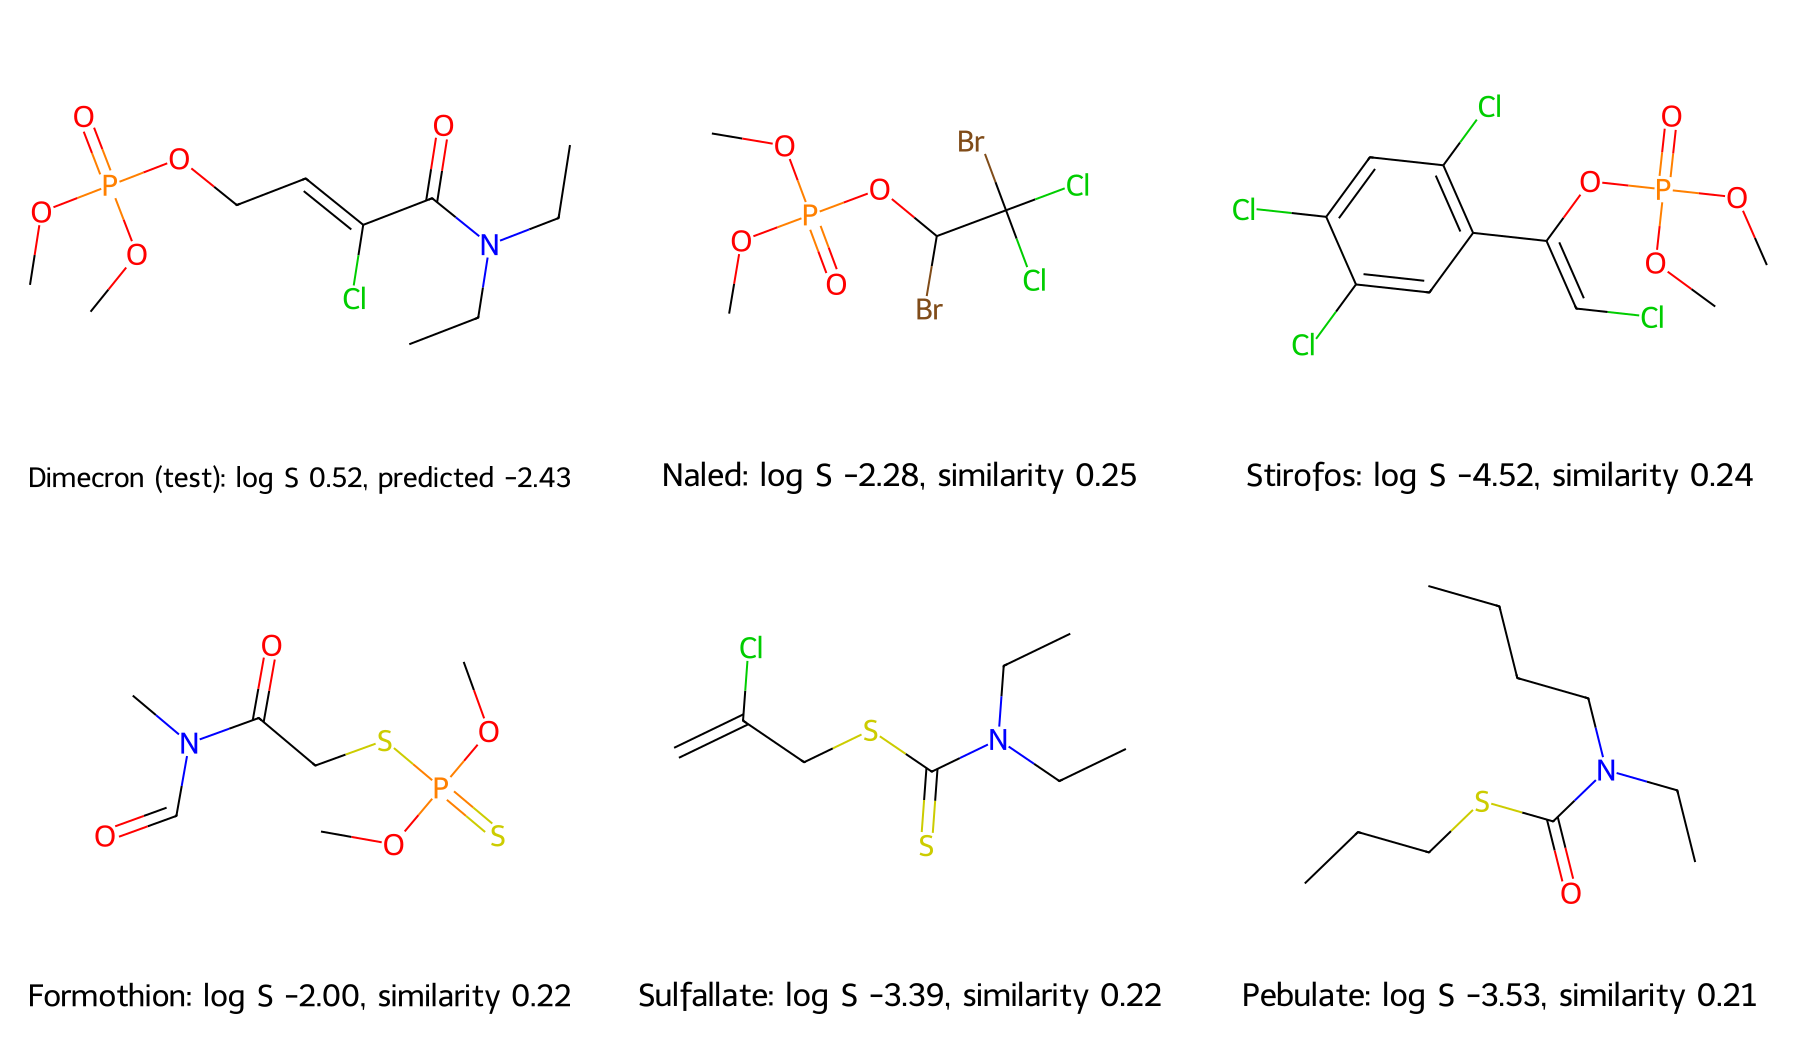

In [44]:
# Source: nearest neighbours with np.argsort on distances as in Tutorial 4 (unsupervised part, 4.0), Tanimoto
# similarity as in Tutorial 3 (section 4), Draw.MolsToGridImage as in Tutorial 3 (section 2) and notebook 01
# (section 7.1)
worst_molecule = worst.index[0]   # rank 1 of the list in section 9
for seed in SPLIT_SEEDS:
    df_train, df_test = stratified_split(df_model, seed)
    if worst_molecule in df_test.index:
        break   # the first random split in which it is a test molecule
xgb_rows = predictions_03[(predictions_03['seed'] == seed) & (predictions_03['model'] == 'XGBoost')
                          & (predictions_03['feature_set'] == 'descriptors + fingerprints')]
worst_name = df_clean.loc[worst_molecule, 'Compound ID']
worst_log_s = df_clean.loc[worst_molecule, TARGET]
worst_prediction = xgb_rows.loc[worst_molecule, 'y_pred']
print(f"{worst_name}: measured log S {worst_log_s:.2f}, XGBoost {worst_prediction:.2f} (random split {seed})")

morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_SIZE)
worst_fp = morgan_gen.GetFingerprint(df_clean.loc[worst_molecule, 'molecule'])
train_fps = [morgan_gen.GetFingerprint(mol) for mol in df_train['molecule']]
similarities = np.array(DataStructs.BulkTanimotoSimilarity(worst_fp, train_fps))
distances = 1 - similarities
nearest = np.argsort(distances)[:5]   # positions of the 5 closest training molecules
neighbours = df_train.iloc[nearest]

legends = [f"{worst_name} (test): log S {worst_log_s:.2f}, predicted {worst_prediction:.2f}"]
for name, log_s, similarity in zip(neighbours['Compound ID'], neighbours[TARGET], similarities[nearest]):
    print(f"   {name}: log S {log_s:.2f}, similarity {similarity:.2f}")
    legends.append(f"{name}: log S {log_s:.2f}, similarity {similarity:.2f}")

# larger legend text for print. returnPNG=False gives an image object we can save
draw_options = Draw.MolDrawOptions()
draw_options.legendFontSize = 32
draw_options.legendFraction = 0.15
img = Draw.MolsToGridImage([df_clean.loc[worst_molecule, 'molecule']] + list(neighbours['molecule']),
                           molsPerRow=3, subImgSize=(600, 520), legends=legends, drawOptions=draw_options,
                           returnPNG=False)
img.save(os.path.join(FIG_DIR, 'interpretation_worst_neighbours.png'))
img

**Observations (worst molecule)**
- Dimecron is very soluble (measured log S 0.52), but XGBoost predicts -2.43 in random split 2. Its most similar training molecule has a Tanimoto similarity of only 0.25, and its 5 nearest training molecules all have a log S between -4.52 and -2.00.
- Dimecron contains phosphorus, and so do 3 of its 5 nearest neighbours (Naled, Stirofos and Formothion). The model has no close neighbour with a similar log S to learn from, which fits the larger XGBoost errors for the phosphorus molecules in section 9.1 (exploratory). It is one molecule, so we use it only as an example.

## 10. Training time

The introduction of our proposal says that simpler models are faster to train. We time the fit of each model on the training set of split 1 with the settings chosen by cross-validation (`time.time()`, as in `03_models.ipynb`). Each fit is timed 3 times and we report the median, because a single timing is noisy. The times depend on the computer, so only their order of magnitude matters. Ridge on the 8 descriptors is fitted with `alpha = 1`, since the fitting time hardly depends on `alpha`.

In [45]:
# Source: new (final project). Timed fits on split 1
df_train, df_test = stratified_split(df_model, 1)
knn_settings = pd.read_csv(os.path.join(TABLE_DIR, 'baselines_knn_settings.csv')).set_index('seed').loc[1]

# the baselines, with the kNN setting that notebook 02 chose for split 1 and ridge with alpha = 1
timed_models = {
    'ESOL refit (Crippen logP)': (LinearRegression(), ESOL_TERMS),
    'Ridge (8 descriptors)': (Pipeline([('scaling', StandardScaler()), ('ridge', Ridge(alpha=1.0))]), FEATURES),
    'kNN (8 descriptors)': (Pipeline([('scaling', StandardScaler()),
                                      ('knn', KNeighborsRegressor(n_neighbors=int(knn_settings['n_neighbors']),
                                                                  weights=knn_settings['weights']))]), FEATURES),
}
# the four models of notebook 03, with the settings it chose for split 1
for model_name in ['Ridge (descriptors + fingerprints)', 'Kernel ridge', 'Random forest', 'XGBoost']:
    make_model, model_03, feature_set, columns = REFIT_MODELS[model_name]
    model = make_model(feature_set)
    model.set_params(**settings_03(1, model_03, feature_set))
    timed_models[model_name] = (model, columns)

# median time of 3 fits of each model on the training set of split 1
training_time = []
for model_name, (model, columns) in timed_models.items():
    seconds = []
    for repeat in range(3):
        start = time.time()
        model.fit(df_train[columns], df_train[TARGET])
        seconds.append(time.time() - start)
    training_time.append({'model': model_name, 'fit_seconds_median': np.median(seconds)})
training_time = pd.DataFrame(training_time).set_index('model')
training_time.round(3).to_csv(os.path.join(TABLE_DIR, 'training_time.csv'))
training_time.round(3)

,fit_seconds_median
model,
ESOL refit (Crippen logP),0.001
Ridge (8 descriptors),0.001
kNN (8 descriptors),0.001
Ridge (descriptors + fingerprints),0.035
Kernel ridge,0.065
Random forest,2.722
XGBoost,1.725


**Observations (training time)**
- The ESOL refit, ridge and kNN on the 8 descriptors train in about a millisecond. Ridge on descriptors + fingerprints and kernel ridge take a fraction of a second. XGBoost and the random forest take one to a few seconds, more than ten times longer than ridge on descriptors + fingerprints and kernel ridge and more than a hundred times longer than the models on the 8 descriptors. The exact times change a little from run to run. For kNN, fitting only stores the training molecules, and the real work happens at prediction time.
- Tuning takes much longer than one fit. In `03_models.ipynb` one split takes about 4 minutes for all models (section 3).

## 11. Diversity of the dataset

Lecture 8 (slides 19 to 22) describes the diversity of a dataset with three numbers. Variety is the number of distinct types, balance is how evenly the molecules are spread over the types (Shannon evenness, where 1 means perfectly even), and disparity is how different the types are from each other. We use the Bemis-Murcko scaffolds of `04_scaffold_split_and_uncertainty.ipynb` as the types, with all molecules without a ring as one type, and the Tanimoto distance (1 minus the similarity) between the scaffolds for the disparity.

In [46]:
# Source: new (final project). Diversity metrics of Lecture 8 (slides 19 to 22). Tanimoto similarity of
#         Morgan fingerprints as in Tutorial 3 (4.), value_counts(normalize=True) as in Tutorial 3 (6.)
# Changes: Tanimoto distance of fingerprints instead of the Euclidean or cosine examples of slide 22

def variety_and_balance(groups):
    """Number of distinct groups and Shannon evenness of a list of group labels."""
    shares = groups.value_counts(normalize=True)
    entropy = -(shares * np.log(shares)).sum()
    return len(shares), entropy / np.log(len(shares))


variety, balance = variety_and_balance(scaffolds)
largest = scaffolds.value_counts(normalize=True).head(2)
print(f"Variety: {variety} scaffold groups (all molecules without a ring count as one)")
print(f"Balance (Shannon evenness): {balance:.2f}")
print(f"The two largest groups hold {largest.iloc[0]:.0%} (no ring) and {largest.iloc[1]:.0%} (benzene) of "
      "the molecules")

# disparity: mean Tanimoto distance between the ring scaffolds
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_SIZE)
ring_scaffolds = [s for s in scaffolds.unique() if s != '']
scaffold_fps = [morgan_gen.GetFingerprint(Chem.MolFromSmiles(s)) for s in ring_scaffolds]
distances = []
for k in range(len(scaffold_fps) - 1):
    similarities = DataStructs.BulkTanimotoSimilarity(scaffold_fps[k], scaffold_fps[k + 1:])   # one against a list
    distances.extend(1 - np.array(similarities))
print(f"Disparity: mean Tanimoto distance between the {len(ring_scaffolds)} ring scaffolds = {np.mean(distances):.2f}")

# the same variety and balance for the test sets of the two kinds of split
diversity_rows = []
for seed in SPLIT_SEEDS:
    for split_type in ['random', 'scaffold']:
        if split_type == 'random':
            df_train, df_test = stratified_split(df_model, seed)
        else:
            df_train, df_test = scaffold_split(df_model, scaffolds, seed)
        test_variety, test_balance = variety_and_balance(scaffolds.loc[df_test.index])
        diversity_rows.append({'split': split_type, 'seed': seed, 'variety': test_variety, 'balance': test_balance})
diversity = pd.DataFrame(diversity_rows)
diversity.round(3).to_csv(os.path.join(TABLE_DIR, 'interpretation_test_set_diversity.csv'), index=False)
print("\nScaffold groups in the 223 test molecules, mean over the 10 splits:")
print(diversity.groupby('split')[['variety', 'balance']].mean().round(2))

Variety: 269 scaffold groups (all molecules without a ring count as one)
Balance (Shannon evenness): 0.63
The two largest groups hold 28% (no ring) and 23% (benzene) of the molecules
Disparity: mean Tanimoto distance between the 268 ring scaffolds = 0.89

Scaffold groups in the 223 test molecules, mean over the 10 splits:
          variety  balance
split                     
random       77.9     0.71
scaffold    105.3     0.88


**Observations (diversity)**
- The dataset has 269 scaffold groups, but the molecules are unevenly spread over them (balance 0.63). The molecules without a ring (28%) and the substituted benzenes (23%) make up half of the dataset.
- The mean Tanimoto distance between the ring scaffolds is 0.89 (1 means that two scaffolds share no fingerprint bits). Morgan fingerprints give high distances even for related scaffolds, so this number alone does not show how different they are chemically.
- The scaffold test sets are more varied (105 scaffold groups on average against 78) and more even (balance 0.88 against 0.71) than the random test sets. This follows from how the split is built, because the benzene and no-ring groups always stay in the training set.
- All our results, both the model comparison and the explanations, depend on which molecules are in ESOL (Lecture 8, slide 17: explanations depend on "The data we trained on"). Because half of the dataset is in two groups and most scaffolds have only a few examples, the errors and the ranking of the models could be different for molecules unlike those in ESOL.

In [47]:
# Source: t-SNE as in Tutorial 4 (2.0 t-SNE), here on the fingerprint bits with the Jaccard distance
#         (1 - Tanimoto similarity, as for kNN on fingerprints in 03_models.ipynb)
# Changes: fitted on all 1,115 molecules (t-SNE cannot place new ones, Lecture 7, slide 21). No log S is used
tsne = TSNE(n_components=2, metric='jaccard', random_state=RANDOM_SEED)
with warnings.catch_warnings():
    # the 0/1 bits are read as True/False for the Jaccard distance, which is what we want
    warnings.filterwarnings('ignore', message='Data was converted to boolean')
    tsne_map = pd.DataFrame(tsne.fit_transform(df_model[FP_COLUMNS].values.astype(bool)),
                            index=df_model.index, columns=['t-SNE 1', 't-SNE 2'])

# the group of each molecule: no ring, benzene or another ring system
scaffold_group = pd.Series('other ring system', index=df_model.index)
scaffold_group[scaffolds == ''] = 'no ring'
scaffold_group[scaffolds == 'c1ccccc1'] = 'benzene'
print(scaffold_group.value_counts().to_string())

other ring system    548
no ring              314
benzene              253


**Observations (map of the molecules)**
- In the t-SNE map of the fingerprints (section 13, `interpretation_tsne_map.png`), the molecules without a ring, the substituted benzenes and the other ring systems lie in different regions.
- In random split 1 the test molecules are spread over the whole map, between training molecules. In scaffold split 1 they lie almost only where the other ring systems are, because the benzene and no-ring groups always stay in the training set, and some of them form small groups of their own because a whole scaffold is held out. This shows why the scaffold test sets are harder (Lecture 9, slide 25 compares training and test data in such a map).
- t-SNE keeps neighbours together, but the distances between groups are not meaningful (Lecture 7, slide 21), so we use the map only as a picture and not for any number.

## 12. The final model

Lecture 9 (slide 27) says that in the projects "you aim to deploy your good model!". We train the main model, XGBoost on descriptors + fingerprints, on all 1,115 molecules with the settings that cross-validation chose most often in `03_models.ipynb`. We save it with `joblib`, as in Tutorial 4 (section 10). The function `predict_log_s()` in `src/esol_predict.py` turns a list of SMILES into descriptors and fingerprints in the same way as our data and returns the predicted log S.

The model was trained on 1,115 small neutral organic molecules (log S from -11.6 to 1.6), so its predictions are only meaningful for similar molecules. In `04_scaffold_split_and_uncertainty.ipynb` the test RMSE of this kind of model (XGBoost on descriptors + fingerprints, refitted on each split) is 0.61 over all random test molecules, 0.69 for the "other ring" molecules of the random splits and 0.83 for molecules with a new scaffold, so its predictions are less reliable for molecules unlike those it was trained on.

In [48]:
# Source: joblib.dump and joblib.load as in Tutorial 4 (10. Saving the model)
xgb_rows = results_03[(results_03['model'] == 'XGBoost') & (results_03['feature_set'] == 'descriptors + fingerprints')]
most_common = xgb_rows['best_params'].value_counts()
print(f"Settings chosen in {most_common.iloc[0]} of 10 splits: {most_common.index[0]}")

final_model = make_xgb_pipeline('descriptors + fingerprints')
final_model.set_params(**ast.literal_eval(most_common.index[0]))
final_model.fit(df_model[DESCRIPTORS_AND_FP], df_model[TARGET])
MODEL_FILE = os.path.join(MODEL_DIR, 'xgboost_final.joblib')
joblib.dump(final_model, MODEL_FILE)
print("Saved results/models/xgboost_final.joblib")

Settings chosen in 9 of 10 splits: {'xgb__subsample': 0.7, 'xgb__n_estimators': 800, 'xgb__min_child_weight': 5, 'xgb__max_depth': 6, 'xgb__learning_rate': 0.05, 'xgb__colsample_bytree': 0.5}


Saved results/models/xgboost_final.joblib


In [49]:
# Source: new (final project). The prediction function in src/esol_predict.py
from esol_predict import predict_log_s

# check: the function gives the same predictions as the model on our own data
check = predict_log_s(df_clean['canonical_smiles'].tolist())
assert np.allclose(check, final_model.predict(df_model[DESCRIPTORS_AND_FP]), atol=1e-4)
print("predict_log_s() gives the same predictions as the saved model on all 1,115 molecules")

# example: three common drugs
examples = {'aspirin': 'CC(=O)Oc1ccccc1C(=O)O',
            'caffeine': 'Cn1cnc2c1c(=O)n(C)c(=O)n2C',
            'ibuprofen': 'CC(C)Cc1ccc(cc1)C(C)C(=O)O'}
predicted = predict_log_s(list(examples.values()))
for (name, smiles), value in zip(examples.items(), predicted):
    in_data = df_clean['canonical_smiles'] == canonicalize_smiles(smiles, isomeric=False)
    note = f"in ESOL, measured {df_clean.loc[in_data, TARGET].iloc[0]:.2f}" if in_data.any() else "not in ESOL"
    print(f"{name:10s} predicted log S {value:.2f} ({note})")

predict_log_s() gives the same predictions as the saved model on all 1,115 molecules
aspirin    predicted log S -1.62 (not in ESOL)
caffeine   predicted log S -0.89 (in ESOL, measured -0.88)
ibuprofen  predicted log S -3.26 (not in ESOL)


**Observations (final model)**
- The final model uses the settings that cross-validation chose in 9 of 10 splits (800 trees, depth 6, learning rate 0.05). These were the most common choice among the same 20 settings, not a proven best setting (section 4.2). The function `predict_log_s()` gives the same predictions as the saved model (to 0.0001 log units) for all 1,115 molecules.
- Caffeine is in ESOL, so its prediction (-0.89, measured -0.88) is not a test. Aspirin and ibuprofen are not in ESOL, and their predictions only show how to use the function.

## 13. Figures

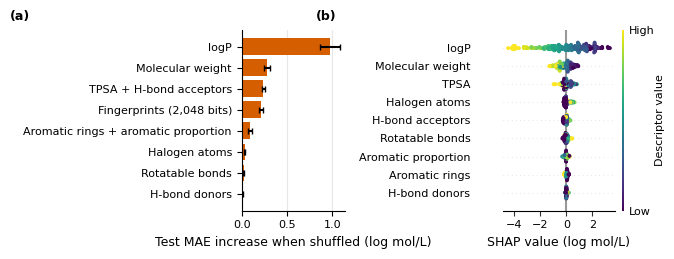

In [50]:
# Source: new figure. Horizontal bar chart as in Tutorial 4 (11.4), error bars = SD over the splits.
#         SHAP beeswarm as in Tutorial 4 (5.3, Beeswarm Plot)
# Changes: no panel titles, the caption says which model each panel shows. Plain names instead of column names

def plain_name(group):
    """Plain name of an input or a group of inputs.

    For example 'AromRings + AromProp' becomes 'Aromatic rings + aromatic proportion'."""
    names = [SHORT_NAMES.get(part, part) for part in group.split(' + ')]
    # lower case after the '+' for ordinary words (not for names like 'H-bond' or 'TPSA')
    names = [names[0]] + [name[0].lower() + name[1:] if name[1].islower() else name for name in names[1:]]
    return ' + '.join(names)


# the size in the paper
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.5), gridspec_kw={'width_ratios': [1, 1.35]})

# (a) permutation importance of the main model (mean and standard deviation over the 10 random splits)
main = importance_summary.loc['XGBoost'].sort_values('mean')
ax_a.barh(range(len(main)), main['mean'], xerr=main['std'], color=MODEL_COLOURS['XGBoost'], capsize=2)
ax_a.set_yticks(range(len(main)))
ax_a.set_yticklabels([plain_name(group) for group in main.index])
ax_a.set_xlabel('Test MAE increase when shuffled (log mol/L)')
ax_a.grid(True, axis='x', alpha=0.3)
ax_a.set_axisbelow(True)

# (b) SHAP values of XGBoost on the 9 descriptors, test molecules of split 1
shap.plots.beeswarm(shap_split_1, max_display=9, ax=ax_b, show=False, plot_size=None, s=8,
                    color_bar_label='Descriptor value', color=plt.get_cmap('viridis'))
# shap uses its own larger fonts, so we set the paper sizes again
ax_b.set_xlabel('SHAP value (log mol/L)', fontsize=9)
ax_b.tick_params(axis='both', labelsize=8, labelcolor='black')   # shap draws grey labels, ours are black
ax_b.set_xticks([-4, -2, 0, 2])   # fewer, shorter tick labels
colour_bar = fig.axes[-1]
colour_bar.tick_params(labelsize=8)
colour_bar.set_ylabel('Descriptor value', fontsize=8)
plt.tight_layout()
# panel labels at the top left of each half of the figure, after tight_layout has placed the panels
fig.text(0.0, 0.97, '(a)', fontweight='bold')
fig.text(0.47, 0.97, '(b)', fontweight='bold')
fig.savefig(os.path.join(FIG_DIR, 'interpretation_importance_and_shap.png'), bbox_inches='tight')
# a PDF copy stays sharp when enlarged on the poster (no creation date, so every run gives the same file)
fig.savefig(os.path.join(FIG_DIR, 'interpretation_importance_and_shap.pdf'), bbox_inches='tight',
            metadata={'CreationDate': None})
plt.show()

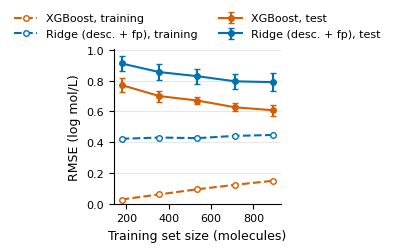

In [51]:
# Source: new figure for the appendix. Training and validation error lines as in Tutorial 4 (7.2), error bars added
fig, ax = plt.subplots(figsize=(HALF_WIDTH, 2.6))
# test RMSE with error bars (SD over the 10 splits) and training RMSE as a dashed line
for model_name, label in [('XGBoost', 'XGBoost'), ('Ridge (descriptors + fingerprints)', 'Ridge (desc. + fp)')]:
    rows = curve_summary.loc[model_name]
    colour = MODEL_COLOURS[model_name]
    ax.errorbar(rows.index, rows[('test_rmse', 'mean')], yerr=rows[('test_rmse', 'std')], color=colour,
                marker='o', ms=4, capsize=2, label=f'{label}, test')
    ax.plot(rows.index, rows[('train_rmse', 'mean')], color=colour, ls='--', marker='o', ms=4, mfc='white',
            label=f'{label}, training')
ax.set_xlabel('Training set size (molecules)')
ax.set_ylabel('RMSE (log mol/L)')
ax.set_ylim(0, None)
ax.grid(True, axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=2)
# save the figure for the appendix
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'interpretation_learning_curve.png'), bbox_inches='tight')
plt.show()

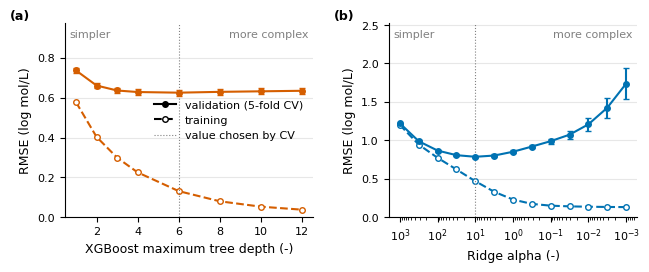

In [52]:
# Source: new figure for the appendix. Training and validation error lines as in Tutorial 4 (7.2), error bars added,
#         the bias-variance picture of Lecture 4 (slide 6)
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.8))
for ax, model_name, label, xlabel in [(ax_a, 'XGBoost', '(a)', 'XGBoost maximum tree depth (-)'),
                                      (ax_b, 'Ridge (descriptors + fingerprints)', '(b)', 'Ridge alpha (-)')]:
    rows = complexity_summary.loc[model_name]
    colour = MODEL_COLOURS[model_name]
    ax.errorbar(rows.index, rows[('val_rmse', 'mean')], yerr=rows[('val_rmse', 'std')], color=colour,
                marker='o', ms=4, capsize=2)
    ax.plot(rows.index, rows[('train_rmse', 'mean')], color=colour, ls='--', marker='o', ms=4, mfc='white')
    # the value chosen most often in notebook 03
    chosen = at_chosen[at_chosen['model'] == model_name]['value'].mode()[0]
    ax.axvline(chosen, color='grey', lw=0.8, ls=':')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('RMSE (log mol/L)')
    top = (rows[('val_rmse', 'mean')] + rows[('val_rmse', 'std')]).max()
    ax.set_ylim(0, top * 1.3)   # room for the labels at the top
    ax.grid(True, axis='y', alpha=0.3)
    ax.set_axisbelow(True)
    ax.text(-0.22, 1.02, label, transform=ax.transAxes, fontweight='bold')
    ax.text(0.02, 0.97, 'simpler', transform=ax.transAxes, fontsize=8, color='grey', va='top')
    ax.text(0.98, 0.97, 'more complex', transform=ax.transAxes, fontsize=8, color='grey', va='top', ha='right')
ax_b.set_xscale('log')
ax_b.invert_xaxis()   # large alpha (simple model) on the left, as for the tree depth
# one legend for both panels, in black because the line styles are the same in both
ax_a.legend(handles=[Line2D([], [], color='k', marker='o', ms=4, label='validation (5-fold CV)'),
                     Line2D([], [], color='k', ls='--', marker='o', ms=4, mfc='white', label='training'),
                     Line2D([], [], color='grey', ls=':', lw=0.8, label='value chosen by CV')],
            frameon=False, loc='center right')   # the empty area between the two lines
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'interpretation_validation_curve.png'), bbox_inches='tight')
plt.show()

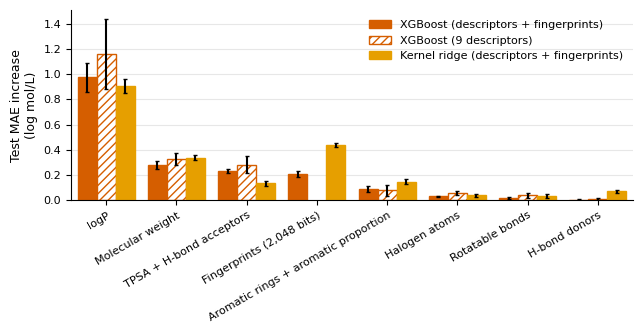

In [53]:
# Source: new figure for the appendix. Bar chart as in Tutorial 4 (11.4), with error bars (standard deviation
#         over the splits)
# the groups in the order of the main model. The 9-descriptor model has no fingerprint bar
LEGEND_LABELS = {'XGBoost': 'XGBoost (descriptors + fingerprints)',
                 'XGBoost (9 descriptors)': 'XGBoost (9 descriptors)',
                 'Kernel ridge': 'Kernel ridge (descriptors + fingerprints)'}
fig, ax = plt.subplots(figsize=(FULL_WIDTH, 3.4))   # room for the turned labels
order = importance_summary.loc['XGBoost'].sort_values('mean', ascending=False).index
width = 0.27
for k, model_name in enumerate(IMPORTANCE_MODELS):
    values = importance_summary.loc[model_name].reindex(order)
    colour = MODEL_COLOURS['Kernel ridge'] if model_name == 'Kernel ridge' else MODEL_COLOURS['XGBoost']
    hatch = '////' if model_name == 'XGBoost (9 descriptors)' else None
    ax.bar(np.arange(len(order)) + (k - 1) * width, values['mean'], width=width, yerr=values['std'],
           color='white' if hatch else colour, edgecolor=colour, hatch=hatch, capsize=1.5,
           label=LEGEND_LABELS[model_name])
ax.set_xticks(range(len(order)))
# plain names (plain_name() is defined with Figure 2 above), turned so that long names do not overlap
ax.set_xticklabels([plain_name(group) for group in order], rotation=30, ha='right', rotation_mode='anchor')
ax.set_xlim(-0.5, len(order) - 0.5)
ax.set_ylabel('Test MAE increase\n(log mol/L)')
ax.legend(frameon=False)
ax.grid(True, axis='y', alpha=0.3)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'interpretation_importance_three_models.png'), bbox_inches='tight')
plt.show()

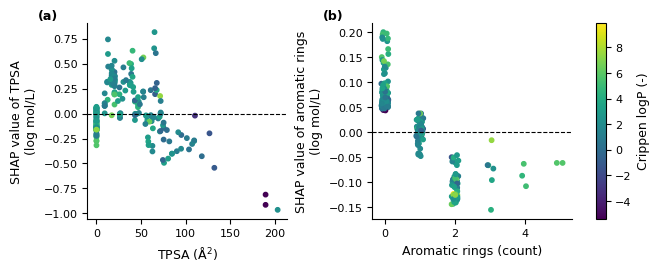

In [54]:
# Source: new figure for the appendix. Scatter plots as in Tutorial 1 (6.), a visual check of the reasons the
# proposal gave for kernel ridge (curved TPSA effect) and XGBoost (step with the number of aromatic rings)
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(FULL_WIDTH, 2.6), layout='constrained')
for ax, feature, label, name in [(ax_a, 'TPSA', '(a)', 'TPSA'), (ax_b, 'AromRings', '(b)', 'aromatic rings')]:
    column = FEATURES_9.index(feature)
    x_values = X_split_1[feature]
    if feature == 'AromRings':
        # small horizontal shift so the points do not hide each other (drawing only)
        x_values = x_values + np.random.default_rng(RANDOM_SEED).uniform(-0.1, 0.1, len(x_values))
    points = ax.scatter(x_values, shap_split_1.values[:, column], c=X_split_1['LogP'], cmap='viridis', s=10)
    ax.axhline(0, color='k', lw=0.8, ls='--')
    ax.set_xlabel(LABELS[feature])
    ax.set_ylabel(f'SHAP value of {name}\n(log mol/L)')
    ax.text(-0.25, 1.02, label, transform=ax.transAxes, fontweight='bold')
fig.colorbar(points, ax=[ax_a, ax_b], label=LABELS['LogP'])
fig.savefig(os.path.join(FIG_DIR, 'interpretation_tpsa_and_rings.png'), bbox_inches='tight')
plt.show()

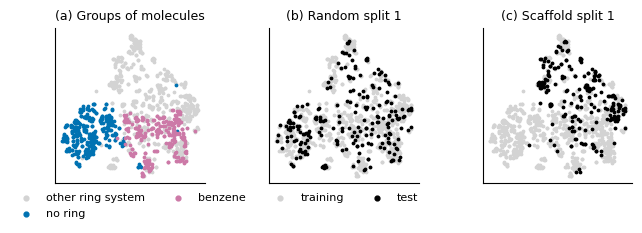

In [55]:
# Source: new figure. t-SNE map as in Tutorial 4 (2.0 t-SNE), with the training and test molecules of split 1
fig, axes = plt.subplots(1, 3, figsize=(FULL_WIDTH, 2.4), sharex=True, sharey=True)

# (a) the three groups of molecules
for group, colour in [('other ring system', 'lightgrey'), ('no ring', '#0072B2'), ('benzene', '#CC79A7')]:
    rows = tsne_map[scaffold_group == group]
    axes[0].scatter(rows['t-SNE 1'], rows['t-SNE 2'], s=3, color=colour, label=group)
axes[0].set_title('(a) Groups of molecules', fontsize=9)
# under the panel
axes[0].legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, 0), ncol=2, markerscale=2)

# (b) and (c) the training and test molecules of the first random and the first scaffold split
for ax, split_type in [(axes[1], 'random'), (axes[2], 'scaffold')]:
    if split_type == 'random':
        df_train, df_test = stratified_split(df_model, 1)
    else:
        df_train, df_test = scaffold_split(df_model, scaffolds, 1)
    ax.scatter(tsne_map.loc[df_train.index, 't-SNE 1'], tsne_map.loc[df_train.index, 't-SNE 2'], s=3,
               color='lightgrey', label='training')
    ax.scatter(tsne_map.loc[df_test.index, 't-SNE 1'], tsne_map.loc[df_test.index, 't-SNE 2'], s=3,
               color='k', label='test')
    ax.set_title(f"({'b' if split_type == 'random' else 'c'}) {split_type.capitalize()} split 1", fontsize=9)
axes[1].legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, 0), ncol=2, markerscale=2)

for ax in axes:
    ax.set_xticks([])   # the t-SNE axes have no units
    ax.set_yticks([])
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'interpretation_tsne_map.png'), bbox_inches='tight')
plt.show()

2,2',3,3',4,4',5,5',6,6'-PCB: measured log S -11.60, predicted -7.94


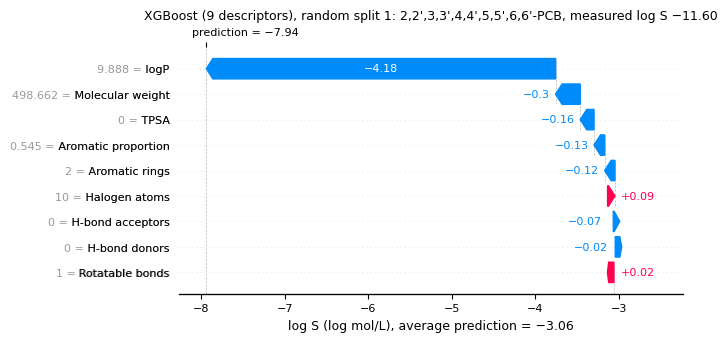

In [56]:
# Source: SHAP waterfall plot as in Tutorial 4 (5.3, Waterfall Plots).
# The test molecule of split 1 with the largest error of the 9-descriptor XGBoost (rule fixed in advance)
model = fitted[('XGBoost (9 descriptors)', 1)]
split_1_errors = np.abs(model.predict(X_split_1) - df_model.loc[X_split_1.index, TARGET])
position = int(np.argmax(split_1_errors.values))
molecule = X_split_1.index[position]
print(f"{df_clean.loc[molecule, 'Compound ID']}: measured log S {df_clean.loc[molecule, TARGET]:.2f}, "
      f"predicted {model.predict(X_split_1.iloc[[position]])[0]:.2f}")

shap.plots.waterfall(shap_split_1[position], max_display=9, show=False)
# shap sets its own figure size and larger fonts, so we set the paper sizes again
fig = plt.gcf()
fig.set_size_inches(FULL_WIDTH, 3.2)
main_ax, base_ax, prediction_ax = fig.axes
main_ax.tick_params(labelsize=8)
for text in main_ax.texts:
    text.set_fontsize(8)
# shap writes the average and the prediction as two labels that drift apart at small fonts, so we write them again
explanation = shap_split_1[position]
prediction = explanation.base_values + explanation.values.sum()
base_ax.set_xticks([])
# \u2212: minus sign
prediction_ax.set_xticks([prediction], [f'prediction = {prediction:.2f}'.replace('-', '\u2212')], fontsize=8)
main_ax.set_xlabel(f'log S (log mol/L), average prediction = {explanation.base_values:.2f}'
                   .replace('-', '\u2212'), fontsize=9)
measured = f"{df_clean.loc[molecule, TARGET]:.2f}".replace('-', '\u2212')   # only the number gets the minus sign
main_ax.set_title(f"XGBoost (9 descriptors), random split 1: {df_clean.loc[molecule, 'Compound ID']}, "
                  f"measured log S {measured}",
                  fontsize=9)
plt.savefig(os.path.join(FIG_DIR, 'interpretation_waterfall_worst.png'), bbox_inches='tight')
plt.show()

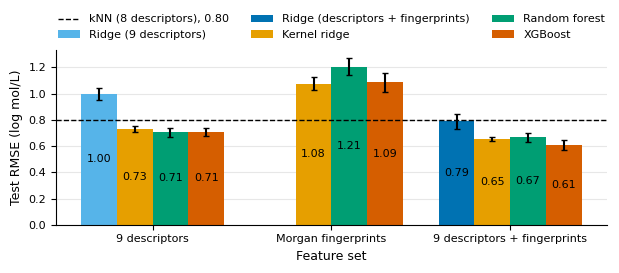

In [57]:
# Source: new figure for the appendix. Bar chart with bar_label as in Tutorial 4 (11.4)
# Changes: bars grouped by feature set, error bars = SD over the 10 splits, kNN as a dashed line
combinations = pd.read_csv(os.path.join(TABLE_DIR, 'models_all_combinations.csv'))
models_summary = pd.read_csv(os.path.join(TABLE_DIR, 'models_summary.csv'), index_col=0)
feature_sets = ['9 descriptors', 'fingerprints', 'descriptors + fingerprints']
tick_labels = ['9 descriptors', 'Morgan fingerprints', '9 descriptors + fingerprints']
bar_models = [('Ridge', 'Ridge (9 descriptors)'), ('Kernel ridge', 'Kernel ridge'),
              ('Random forest', 'Random forest'), ('XGBoost', 'XGBoost')]
width = 0.2

fig, ax = plt.subplots(figsize=(FULL_WIDTH, 2.8))
for k, (model_name, colour_name) in enumerate(bar_models):
    for j, feature_set in enumerate(feature_sets):
        row = combinations[(combinations['model'] == model_name) & (combinations['feature_set'] == feature_set)]
        if len(row) == 0:   # ridge was not run on the fingerprints alone
            continue
        # ridge with fingerprints has its own darker colour, as in Figure 1
        colour = MODEL_COLOURS[colour_name]
        label = colour_name if model_name == 'Ridge' else model_name
        if model_name == 'Ridge' and feature_set == 'descriptors + fingerprints':
            colour = MODEL_COLOURS['Ridge (descriptors + fingerprints)']
            label = 'Ridge (descriptors + fingerprints)'
        elif j > 0:
            label = '_nolegend_'   # one legend entry per model
        bars = ax.bar(j + (k - 1.5) * width, row['rmse_mean'].iloc[0], width, yerr=row['rmse_sd'].iloc[0],
                      capsize=2, color=colour, label=label)   # 4 bars side by side around each feature set
        ax.bar_label(bars, fmt='%.2f', fontsize=8, label_type='center')
knn_rmse = models_summary.loc['kNN (8 descriptors)', 'rmse_mean']
ax.axhline(knn_rmse, color='k', ls='--', lw=1, label=f'kNN (8 descriptors), {knn_rmse:.2f}')
ax.set_xticks(range(len(feature_sets)))
ax.set_xticklabels(tick_labels)
ax.set_xlabel('Feature set')
ax.set_ylabel('Test RMSE (log mol/L)')
ax.grid(True, axis='y', alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, ncol=3, fontsize=8, loc='lower center', bbox_to_anchor=(0.5, 1.0))
plt.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'models_feature_sets.png'), bbox_inches='tight')
plt.show()

**Observations (feature sets)**
- On the fingerprints alone every model is worse than kNN (1.08 to 1.21). Every model is best with the 9 descriptors and the fingerprints together. XGBoost on both is the lowest (0.61). We did not fit ridge on the fingerprints alone.
- The feature set of each model was chosen by cross-validation in notebook 03. The test RMSE in this figure is shown for information only.

The pipeline diagram below summarizes the steps of the whole project for the paper and the poster. Each box names the notebooks that do the step.

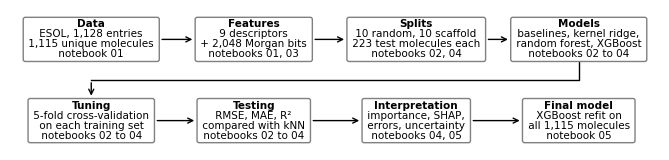

In [58]:
# Source: new figure for the paper and the poster. Text boxes and arrows with matplotlib (ax.text and
#         ax.annotate, as for the labels in 01_data_and_eda.ipynb, section 8)
# Changes: the steps of our pipeline, with the notebooks that do each step
# each step: title, what it does (2 lines), the notebooks that do it
STEPS = [
    ('Data', 'ESOL, 1,128 entries\n1,115 unique molecules', 'notebook 01'),
    ('Features', '9 descriptors\n+ 2,048 Morgan bits', 'notebooks 01, 03'),
    ('Splits', '10 random, 10 scaffold\n223 test molecules each', 'notebooks 02, 04'),
    ('Models', 'baselines, kernel ridge,\nrandom forest, XGBoost', 'notebooks 02 to 04'),
    ('Tuning', '5-fold cross-validation\non each training set', 'notebooks 02 to 04'),
    ('Testing', 'RMSE, MAE, R²\ncompared with kNN', 'notebooks 02 to 04'),
    ('Interpretation', 'importance, SHAP,\nerrors, uncertainty', 'notebooks 04, 05'),
    ('Final model', 'XGBoost refit on\nall 1,115 molecules', 'notebook 05'),
]

# an empty figure as wide as the page, with room for 2 rows of 4 boxes
fig = plt.figure(figsize=(FULL_WIDTH, 1.4))
ax = fig.add_axes([0, 0, 1, 1])   # the axes fill the whole figure
ax.set_xlim(0, 4)
ax.set_ylim(0, 2)
ax.axis('off')
boxes = []
for k, (title, text, notebooks) in enumerate(STEPS):
    row, column = divmod(k, 4)           # 4 boxes per row
    x = column + 0.5
    y = 1.58 if row == 0 else 0.42   # the two rows sit near the top and bottom edges, to leave room for the arrow
    # the box holds the two text lines and the notebooks, with an empty first line for the title
    # and a little room at the sides
    padded = '\n'.join(f' {line} ' for line in f'{text}\n{notebooks}'.split('\n'))   # a space at both ends of each line
    boxes.append(ax.text(x, y, f' \n{padded}', ha='center', va='center', fontsize=7.5, linespacing=1.0,
                         bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='grey')))
    # the title in bold on that first line (a second text at the same place, with empty lines below it)
    ax.text(x, y, f'{title}\n \n \n ', ha='center', va='center', fontsize=7.5, linespacing=1.0, fontweight='bold')

# the arrows start and end at the edges of the boxes, so we first ask matplotlib where each box was drawn
fig.canvas.draw()
edges = [box.get_bbox_patch().get_window_extent().transformed(ax.transData.inverted()) for box in boxes]
arrow = dict(arrowstyle='->', lw=1)
for k in range(len(STEPS) - 1):
    if k == 3:   # from the bottom of the last box of the first row to the top of the first box of the second row
        middle = (edges[3].y0 + max(edge.y1 for edge in edges[4:])) / 2
        ax.plot([3.5, 3.5, 0.5], [edges[3].y0, middle, middle], color='k', lw=1)
        ax.annotate('', xy=(0.5, edges[4].y1), xytext=(0.5, middle), arrowprops=arrow)
    else:        # from the right edge of a box to the left edge of the next box
        ax.annotate('', xy=(edges[k + 1].x0, 1.58 if k < 3 else 0.42), xytext=(edges[k].x1, 1.58 if k < 3 else 0.42),
                    arrowprops=arrow)
fig.savefig(os.path.join(FIG_DIR, 'pipeline_diagram.png'), bbox_inches='tight', pad_inches=0.03)
# a PDF copy for the poster (no creation date, so every run gives the same file)
fig.savefig(os.path.join(FIG_DIR, 'pipeline_diagram.pdf'), bbox_inches='tight', pad_inches=0.03,
            metadata={'CreationDate': None})
plt.show()

## 14. Summary of the notebooks

`01_data_and_eda.ipynb` explores the data, `02_baselines.ipynb` sets the baselines, `03_models.ipynb` answers the research question on random splits, `04_scaffold_split_and_uncertainty.ipynb` tests the models on new scaffolds and estimates their uncertainty, and this notebook looks at what the models rely on and where they fail, and saves the final model.